In [24]:
import pickle
import numpy as np
from collections import defaultdict

print("="*80)
print("UNIFIED BURST ANALYSIS")
print("="*80)
print("\nThis script performs three analyses with CONSISTENT burst detection:")
print("  1. Burst length distribution by drug condition")
print("  2. Participant-level burst patterns")
print("  3. Temporal overlaps between clusters")
print("  4. Polarity switches and interval ranges")
print()

# ============================================================================
# CONFIGURATION - All parameters in one place
# ============================================================================

class BurstConfig:
    """Centralized configuration for burst detection"""
    
    # Burst detection parameters
    MAX_INTERVAL_MS = 50           # Maximum interval between activations in a burst
    MIN_BURST_LENGTH = 2           # Minimum number of activations to count as burst
    CORRELATION_THRESHOLD = 0.825    # Minimum |correlation| to include activation
    
    # Interval ranges for detailed analysis
    INTERVAL_RANGES = [
        (0, 50, "0-50ms"),
        (50, 100, "50-100ms")
    ]
    
    # Clusters to analyze
    CLUSTERS_TO_ANALYZE = list(range(0, 12))#list(range(0, 9)) + list(range(10, 12))  # Clusters 0-8 and 10-11
    
    # Overlap detection
    MIN_OVERLAP_MS = 50  # Minimum overlap duration to report
    
    @classmethod
    def print_config(cls):
        print("BURST DETECTION CONFIGURATION:")
        print(f"  Max interval between activations: {cls.MAX_INTERVAL_MS}ms")
        print(f"  Min burst length: {cls.MIN_BURST_LENGTH} activations")
        print(f"  Correlation threshold: |r| > {cls.CORRELATION_THRESHOLD}")
        print(f"  Clusters analyzed: {len(cls.CLUSTERS_TO_ANALYZE)} ({min(cls.CLUSTERS_TO_ANALYZE)}-{max(cls.CLUSTERS_TO_ANALYZE)})")
        print(f"  Interval ranges: {[r[2] for r in cls.INTERVAL_RANGES]}")
        print(f"  Min overlap duration: {cls.MIN_OVERLAP_MS}ms")
        print(f"\nANALYSIS REPORTING:")
        print(f"  All clusters with ≥1 burst will be included in analyses")
        print()

config = BurstConfig()
config.print_config()

# ============================================================================
# LOAD DATA
# ============================================================================
print("Loading data...")

with open('/home/novicky/clean_code/similarity_blocks_with_polarity_3/cluster_analysis_k10.0_no_threshold.pkl', 'rb') as f:
    results = pickle.load(f)

with open('/home/novicky/metadata.pkl', 'rb') as f:
    file_metadata = pickle.load(f)

with open('/home/novicky/clean_code/similarity_blocks_with_polarity_3/cluster_averages.pkl', 'rb') as f:
    cluster_averages = pickle.load(f)

cluster_activation_times = results['cluster_activation_times']
top_clusters = len(cluster_activation_times)

# Get cluster pattern durations (in seconds) - only for clusters that exist
cluster_durations = {}
available_clusters = []
for cluster_id in range(top_clusters):
    if cluster_id < len(cluster_averages):
        n_timepoints = cluster_averages[cluster_id].shape[1]
        duration_sec = n_timepoints / 250.0  # 250 Hz sampling rate
        cluster_durations[cluster_id] = duration_sec
        available_clusters.append(cluster_id)

# Filter CLUSTERS_TO_ANALYZE to only include available clusters
filtered_clusters = [c for c in BurstConfig.CLUSTERS_TO_ANALYZE if c in available_clusters]

print(f"Loaded activation data for {top_clusters} clusters")
print(f"Loaded metadata for {len(file_metadata)} datasets")
print(f"Available clusters with duration data: {len(cluster_durations)} clusters")
print(f"Requested clusters to analyze: {BurstConfig.CLUSTERS_TO_ANALYZE}")
print(f"Actually analyzing (filtered to available): {filtered_clusters}")
print()

# ============================================================================
# UNIFIED BURST DETECTION FUNCTION
# ============================================================================
def detect_bursts_unified(times, polarities, correlations, cluster_duration, dataset_idx):
    """
    Unified burst detection with consistent logic.
    
    Returns:
        list of burst dictionaries with all relevant information
    """
    bursts = []
    
    # Filter by correlation threshold
    high_corr_mask = np.abs(correlations) > config.CORRELATION_THRESHOLD
    times_filtered = times[high_corr_mask]
    polarities_filtered = polarities[high_corr_mask]
    correlations_filtered = correlations[high_corr_mask]
    
    if len(times_filtered) < config.MIN_BURST_LENGTH:
        return bursts
    
    # Initialize first burst
    current_burst = {
        'times': [times_filtered[0]],
        'polarities': [polarities_filtered[0]],
        'correlations': [correlations_filtered[0]],
        'intervals': []
    }
    
    # Iterate through remaining activations
    for i in range(1, len(times_filtered)):
        interval_ms = (times_filtered[i] - current_burst['times'][-1]) * 1000
        
        if interval_ms < config.MAX_INTERVAL_MS:
            # Continue current burst
            current_burst['times'].append(times_filtered[i])
            current_burst['polarities'].append(polarities_filtered[i])
            current_burst['correlations'].append(correlations_filtered[i])
            current_burst['intervals'].append(interval_ms)
        else:
            # Save current burst if long enough
            if len(current_burst['times']) >= config.MIN_BURST_LENGTH:
                burst = finalize_burst(current_burst, cluster_duration, dataset_idx)
                bursts.append(burst)
            
            # Start new burst
            current_burst = {
                'times': [times_filtered[i]],
                'polarities': [polarities_filtered[i]],
                'correlations': [correlations_filtered[i]],
                'intervals': []
            }
    
    # Don't forget the last burst
    if len(current_burst['times']) >= config.MIN_BURST_LENGTH:
        burst = finalize_burst(current_burst, cluster_duration, dataset_idx)
        bursts.append(burst)
    
    return bursts

def finalize_burst(burst_data, cluster_duration, dataset_idx):
    """Convert burst data into final burst dictionary"""
    metadata = file_metadata[dataset_idx]
    
    # Calculate burst duration (from start of first to end of last activation)
    burst_duration = (burst_data['times'][-1] - burst_data['times'][0]) * 1000 + cluster_duration * 1000
    
    # Calculate polarity switches and patterns
    n_switches = 0
    n_stable = 0
    for j in range(len(burst_data['polarities']) - 1):
        if burst_data['polarities'][j] * burst_data['polarities'][j+1] < 0:
            n_switches += 1
        else:
            n_stable += 1
    
    total_transitions = n_switches + n_stable
    switch_rate = (n_switches / total_transitions * 100) if total_transitions > 0 else 0
    
    # Determine polarity type: stable, switching, or mixed
    # stable: all same polarity (e.g., +++, ---)
    # switching: alternates between polarities (e.g., +-+-, -+-+)
    # mixed: both polarities present but not alternating (e.g., +++--, --++)
    
    if len(burst_data['polarities']) == 1:
        polarity_type = 'stable'
    else:
        # Check if all same polarity
        all_same = all(p == burst_data['polarities'][0] for p in burst_data['polarities'])
        
        if all_same:
            polarity_type = 'stable'
        elif n_switches > 0 and n_stable > 0:
            # Has both switches and non-switches = mixed
            polarity_type = 'mixed'
        elif n_switches > 0:
            # All transitions are switches = switching
            polarity_type = 'switching'
        else:
            # This shouldn't happen if not all_same, but just in case
            polarity_type = 'stable'
    
    # Determine interval range (all intervals must fit in one range)
    interval_range = None
    if len(burst_data['intervals']) > 0:
        for min_int, max_int, label in config.INTERVAL_RANGES:
            if all(min_int <= interval < max_int for interval in burst_data['intervals']):
                interval_range = label
                break
    
    return {
        'dataset': dataset_idx,
        'start_time': burst_data['times'][0],
        'end_time': burst_data['times'][-1] + cluster_duration,
        'length': len(burst_data['times']),
        'duration': burst_duration,
        'intervals': burst_data['intervals'].copy(),
        'interval_range': interval_range,
        'n_switches': n_switches,
        'n_stable': n_stable,
        'switch_rate': switch_rate,
        'polarity_type': polarity_type,
        'polarities': burst_data['polarities'].copy(),
        'correlations': burst_data['correlations'].copy(),
        'drug': metadata.get('drug_condition', 'Unknown'),
        'task': metadata.get('task', 'Unknown'),
        'subject_id': metadata.get('subject_id', 'Unknown'),
        'subject_number': metadata.get('subject_number', 'Unknown'),
        'is_trained': metadata.get('is_trained', None)
    }

# ============================================================================
# HELPER FUNCTION FOR POLARITY TYPE
# ============================================================================
def get_polarity_type(burst):
    """Get polarity type, computing it if not present in burst dict (backwards compatibility)"""
    if 'polarity_type' in burst:
        return burst['polarity_type']
    
    # Fallback: compute it from burst data
    polarities = burst.get('polarities', [])
    n_switches = burst.get('n_switches', 0)
    n_stable = burst.get('n_stable', 0)
    
    if len(polarities) == 1:
        return 'stable'
    
    all_same = all(p == polarities[0] for p in polarities) if len(polarities) > 0 else True
    
    if all_same:
        return 'stable'
    elif n_switches > 0 and n_stable > 0:
        return 'mixed'
    elif n_switches > 0:
        return 'switching'
    else:
        return 'stable'

# ============================================================================
# DETECT ALL BURSTS
# ============================================================================
print("="*80)
print("DETECTING BURSTS ACROSS ALL CLUSTERS")
print("="*80)

burst_data_by_cluster = {}

total_activations = 0
total_bursts = 0

for cluster_id in config.CLUSTERS_TO_ANALYZE:
    print(f"Processing Cluster {cluster_id}...", end="\r")
    
    cluster_bursts = []
    cluster_duration = cluster_durations[cluster_id]
    
    for dataset_idx, times, polarities, correlations in cluster_activation_times[cluster_id]:
        total_activations += len(times)
        
        # Detect bursts
        bursts = detect_bursts_unified(times, polarities, correlations, 
                                       cluster_duration, dataset_idx)
        
        cluster_bursts.extend(bursts)
        total_bursts += len(bursts)
    
    burst_data_by_cluster[cluster_id] = cluster_bursts

print(f"\nBurst detection complete!")
print(f"  Total activations processed: {total_activations}")
print(f"  Total bursts detected: {total_bursts}")
print(f"  Bursts per cluster (mean): {total_bursts / len(config.CLUSTERS_TO_ANALYZE):.1f}")

# Create combined list of all bursts for analyses
all_bursts = [b for bursts in burst_data_by_cluster.values() for b in bursts]

# Validation: Check actual burst lengths match MIN_BURST_LENGTH setting
if len(all_bursts) > 0:
    min_detected = min(b['length'] for b in all_bursts)
    max_detected = max(b['length'] for b in all_bursts)
    mean_detected = np.mean([b['length'] for b in all_bursts])
    
    print(f"\nBurst Length Statistics:")
    print(f"  Min:  {min_detected}")
    print(f"  Max:  {max_detected}")
    print(f"  Mean: {mean_detected:.2f}")
    
    if min_detected < config.MIN_BURST_LENGTH:
        print(f"\n⚠️  WARNING: Detected bursts with length {min_detected}, but MIN_BURST_LENGTH = {config.MIN_BURST_LENGTH}")
        print(f"    This suggests you're analyzing OLD burst data.")
        print(f"    To fix: Restart kernel and re-run entire script from beginning.")
    else:
        print(f"  ✓ Validation: All bursts have length ≥ {config.MIN_BURST_LENGTH}")
    
    # Debug polarity type distribution
    print(f"\nPolarity Type Distribution (all bursts):")
    stable_count = sum(1 for b in all_bursts if get_polarity_type(b) == 'stable')
    switching_count = sum(1 for b in all_bursts if get_polarity_type(b) == 'switching')
    mixed_count = sum(1 for b in all_bursts if get_polarity_type(b) == 'mixed')
    
    print(f"  Stable:    {stable_count:5d} ({stable_count/len(all_bursts)*100:.1f}%)")
    print(f"  Switching: {switching_count:5d} ({switching_count/len(all_bursts)*100:.1f}%)")
    print(f"  Mixed:     {mixed_count:5d} ({mixed_count/len(all_bursts)*100:.1f}%)")
    

print()

# ============================================================================
# ANALYSIS 1: BURST LENGTH DISTRIBUTION BY DRUG CONDITION
# ============================================================================
print("="*80)
print("ANALYSIS 1: BURST LENGTH DISTRIBUTION")
print("="*80)
print("Comparing Control vs Psilocybin\n")

for cluster_id in config.CLUSTERS_TO_ANALYZE:
    bursts = burst_data_by_cluster[cluster_id]
    
    # Skip if no bursts at all
    if len(bursts) == 0:
        continue
    
    # Separate by drug condition
    ctrl_lengths = [b['length'] for b in bursts if b['drug'] == 'Control']
    psi_lengths = [b['length'] for b in bursts if b['drug'] == 'Psilocybin']
    
    # Skip only if no bursts at all (already handled above, but be safe)
    if len(ctrl_lengths) == 0 and len(psi_lengths) == 0:
        continue
    
    print(f"{'='*80}")
    print(f"Cluster {cluster_id}")
    print(f"{'='*80}")
    
    # Basic statistics
    print(f"\nTotal Bursts:")
    if len(ctrl_lengths) > 0:
        print(f"  Control:    {len(ctrl_lengths):4d} bursts")
    else:
        print(f"  Control:       0 bursts (no data)")
    
    if len(psi_lengths) > 0:
        print(f"  Psilocybin: {len(psi_lengths):4d} bursts")
    else:
        print(f"  Psilocybin:    0 bursts (no data)")
    
    # Distribution statistics - only show if data exists
    if len(ctrl_lengths) > 0 or len(psi_lengths) > 0:
        print(f"\nDescriptive Statistics:")
    
    if len(ctrl_lengths) > 0:
        print(f"  Control:    Mean={np.mean(ctrl_lengths):.2f}, Median={np.median(ctrl_lengths):.0f}, "
              f"75th%={np.percentile(ctrl_lengths, 75):.0f}, 90th%={np.percentile(ctrl_lengths, 90):.0f}, "
              f"Max={np.max(ctrl_lengths):.0f}")
    
    if len(psi_lengths) > 0:
        print(f"  Psilocybin: Mean={np.mean(psi_lengths):.2f}, Median={np.median(psi_lengths):.0f}, "
              f"75th%={np.percentile(psi_lengths, 75):.0f}, 90th%={np.percentile(psi_lengths, 90):.0f}, "
              f"Max={np.max(psi_lengths):.0f}")
    
    # Distribution table - only show if at least one condition has data
    if len(ctrl_lengths) > 0 or len(psi_lengths) > 0:
        max_length = max(
            max(ctrl_lengths) if len(ctrl_lengths) > 0 else 0,
            max(psi_lengths) if len(psi_lengths) > 0 else 0
        )
        
        print(f"\nBurst Length Distribution:")
        print(f"  Length | Control | Psilocybin")
        print(f"  -------|---------|------------")
        
        for length in range(2, min(int(max_length) + 1, 15)):
            ctrl_count = sum(1 for l in ctrl_lengths if l == length)
            psi_count = sum(1 for l in psi_lengths if l == length)
            if ctrl_count > 0 or psi_count > 0:
                print(f"  {length:4d}   | {ctrl_count:7d} | {psi_count:10d}")
        
        if max_length >= 15:
            ctrl_count_15plus = sum(1 for l in ctrl_lengths if l >= 15)
            psi_count_15plus = sum(1 for l in psi_lengths if l >= 15)
            if ctrl_count_15plus > 0 or psi_count_15plus > 0:
                print(f"  15+    | {ctrl_count_15plus:7d} | {psi_count_15plus:10d}")
    
    print()

# ============================================================================
# ANALYSIS 1a: BURST DISTRIBUTION BY TASK
# ============================================================================
print("="*80)
print("ANALYSIS 1a: BURST DISTRIBUTION BY TASK")
print("="*80)
print("Within each drug condition\n")

tasks = ['Meditation', 'Music', 'Resting state', 'Video']

for cluster_id in config.CLUSTERS_TO_ANALYZE:
    bursts = burst_data_by_cluster[cluster_id]
    
    # Skip if no bursts at all
    if len(bursts) == 0:
        continue
    
    # Organize by drug and task
    ctrl_by_task = {task: [] for task in tasks}
    psi_by_task = {task: [] for task in tasks}
    
    for burst in bursts:
        if burst['task'] in tasks:
            if burst['drug'] == 'Control':
                ctrl_by_task[burst['task']].append(burst['length'])
            elif burst['drug'] == 'Psilocybin':
                psi_by_task[burst['task']].append(burst['length'])
    
    # Check if there's any data
    has_data = any(len(ctrl_by_task[task]) > 0 or len(psi_by_task[task]) > 0 
                   for task in tasks)
    
    if not has_data:
        continue
    
    print(f"Cluster {cluster_id}:")
    
    # Control condition
    print("  CONTROL:")
    for task in tasks:
        if len(ctrl_by_task[task]) > 0:
            mean_len = np.mean(ctrl_by_task[task])
            std_len = np.std(ctrl_by_task[task]) if len(ctrl_by_task[task]) > 1 else 0.0
            print(f"    {task:15s}: {mean_len:.2f}±{std_len:.2f} (n={len(ctrl_by_task[task])} bursts)")
    
    # Psilocybin condition
    print("  PSILOCYBIN:")
    for task in tasks:
        if len(psi_by_task[task]) > 0:
            mean_len = np.mean(psi_by_task[task])
            std_len = np.std(psi_by_task[task]) if len(psi_by_task[task]) > 1 else 0.0
            print(f"    {task:15s}: {mean_len:.2f}±{std_len:.2f} (n={len(psi_by_task[task])} bursts)")
    print()

# ============================================================================
# ANALYSIS 2: PARTICIPANT-LEVEL BURST PATTERNS
# ============================================================================
print("="*80)
print("ANALYSIS 2: BURST PATTERNS PER PARTICIPANT")
print("="*80)
print("Showing only participants with ≥3 bursts\n")

for cluster_id in config.CLUSTERS_TO_ANALYZE:
    bursts = burst_data_by_cluster[cluster_id]
    
    # Skip if no bursts at all
    if len(bursts) == 0:
        continue
    
    # Count bursts per participant
    participant_burst_counts = defaultdict(lambda: {'count': 0, 'drug': None, 'task': None})
    
    for burst in bursts:
        subject_key = f"{burst['subject_id']}_{burst['subject_number']}"
        participant_burst_counts[subject_key]['count'] += 1
        participant_burst_counts[subject_key]['drug'] = burst['drug']
        participant_burst_counts[subject_key]['task'] = burst['task']
    
    # Filter to participants with >=3 bursts
    filtered_participants = {k: v for k, v in participant_burst_counts.items() 
                            if v['count'] >= 3}
    
    if len(filtered_participants) == 0:
        continue
    
    # Sort by burst count
    sorted_participants = sorted(filtered_participants.items(), 
                                 key=lambda x: x[1]['count'], reverse=True)
    
    print(f"Cluster {cluster_id}:")
    print(f"  Total bursts: {len(bursts)}")
    print(f"  Participants with ≥3 bursts: {len(filtered_participants)}")
    
    # Show distribution
    ctrl_counts = [data['count'] for _, data in sorted_participants if data['drug'] == 'Control']
    psi_counts = [data['count'] for _, data in sorted_participants if data['drug'] == 'Psilocybin']
    
    if len(ctrl_counts) > 0:
        print(f"  Control - Mean: {np.mean(ctrl_counts):.1f}, Median: {np.median(ctrl_counts):.0f}, "
              f"Max: {np.max(ctrl_counts):.0f} (n={len(ctrl_counts)} participants)")
    if len(psi_counts) > 0:
        print(f"  Psilocybin - Mean: {np.mean(psi_counts):.1f}, Median: {np.median(psi_counts):.0f}, "
              f"Max: {np.max(psi_counts):.0f} (n={len(psi_counts)} participants)")
    
    # Show top 10 participants
    print(f"\n  Top 10 most active participants:")
    for i, (subject, data) in enumerate(sorted_participants[:10], 1):
        print(f"    {i:2d}. {subject:20s}: {data['count']:3d} bursts | {data['drug']:11s} | {data['task']}")
    print()

# ============================================================================
# ANALYSIS 3: POLARITY TYPE BY INTERVAL RANGE
# ============================================================================
print("="*80)
print("ANALYSIS 3: POLARITY TYPE BY INTERVAL RANGE")
print("="*80)
print("Stable = all same polarity")
print("Switching = alternating polarities") 
print("Mixed = both polarities present but not alternating (e.g., +++--)\n")

for cluster_id in config.CLUSTERS_TO_ANALYZE:
    bursts = burst_data_by_cluster[cluster_id]
    
    # Skip if no bursts at all
    if len(bursts) == 0:
        continue
    
    # Categorize bursts
    results = {}
    for _, _, range_label in config.INTERVAL_RANGES:
        results[range_label] = {
            'Control': {'stable': [], 'switching': [], 'mixed': []},
            'Psilocybin': {'stable': [], 'switching': [], 'mixed': []}
        }
    
    for burst in bursts:
        if burst['interval_range'] is None:
            continue
        
        # Use the polarity_type (with fallback if not present)
        polarity_type = get_polarity_type(burst)
        
        # Store burst length
        drug = burst['drug']
        if drug in results[burst['interval_range']]:
            results[burst['interval_range']][drug][polarity_type].append(burst['length'])
    
    # Check if there's data to display
    has_data = any(
        len(results[range_label][drug][ptype]) > 0
        for range_label in results
        for drug in ['Control', 'Psilocybin']
        for ptype in ['stable', 'switching', 'mixed']
    )
    
    if not has_data:
        continue
    
    print(f"Cluster {cluster_id}:")
    
    for _, _, range_label in config.INTERVAL_RANGES:
        range_data = results[range_label]
        
        # Check if this range has any data
        range_has_data = any(
            len(range_data[drug][ptype]) > 0
            for drug in ['Control', 'Psilocybin']
            for ptype in ['stable', 'switching', 'mixed']
        )
        
        if not range_has_data:
            continue
        
        print(f"  {range_label}:")
        
        for drug in ['Control', 'Psilocybin']:
            stable_bursts = range_data[drug]['stable']
            switching_bursts = range_data[drug]['switching']
            mixed_bursts = range_data[drug]['mixed']
            
            if len(stable_bursts) > 0 or len(switching_bursts) > 0 or len(mixed_bursts) > 0:
                print(f"    {drug}:")
                
                if len(stable_bursts) > 0:
                    mean_len = np.mean(stable_bursts)
                    std_len = np.std(stable_bursts) if len(stable_bursts) > 1 else 0.0
                    print(f"      Stable:    {len(stable_bursts):3d} bursts, mean length {mean_len:.2f}±{std_len:.2f}")
                
                if len(switching_bursts) > 0:
                    mean_len = np.mean(switching_bursts)
                    std_len = np.std(switching_bursts) if len(switching_bursts) > 1 else 0.0
                    print(f"      Switching: {len(switching_bursts):3d} bursts, mean length {mean_len:.2f}±{std_len:.2f}")
                
                if len(mixed_bursts) > 0:
                    mean_len = np.mean(mixed_bursts)
                    std_len = np.std(mixed_bursts) if len(mixed_bursts) > 1 else 0.0
                    print(f"      Mixed:     {len(mixed_bursts):3d} bursts, mean length {mean_len:.2f}±{std_len:.2f}")
    
    print()

# ============================================================================
# ANALYSIS 4: POLARITY DISTRIBUTION BY DRUG CONDITION AND TASK
# ============================================================================
print("="*80)
print("ANALYSIS 4: POLARITY DISTRIBUTION BY DRUG CONDITION AND TASK")
print("="*80)
print("Analyzing 0-50ms bursts only\n")

# Filter to only bursts in 0-50ms range
bursts_0_50 = [b for b in all_bursts 
               if b['interval_range'] == '0-50ms']

print(f"Total 0-50ms bursts: {len(bursts_0_50)}\n")

# ============================================================================
# 4a. Total distribution by Drug Condition (0-50ms only)
# ============================================================================
print("-" * 80)
print("4a. OVERALL POLARITY DISTRIBUTION BY DRUG CONDITION")
print("-" * 80)

ctrl_stable = sum(1 for b in bursts_0_50 if b['drug'] == 'Control' and get_polarity_type(b) == 'stable')
ctrl_switching = sum(1 for b in bursts_0_50 if b['drug'] == 'Control' and get_polarity_type(b) == 'switching')
ctrl_mixed = sum(1 for b in bursts_0_50 if b['drug'] == 'Control' and get_polarity_type(b) == 'mixed')
psi_stable = sum(1 for b in bursts_0_50 if b['drug'] == 'Psilocybin' and get_polarity_type(b) == 'stable')
psi_switching = sum(1 for b in bursts_0_50 if b['drug'] == 'Psilocybin' and get_polarity_type(b) == 'switching')
psi_mixed = sum(1 for b in bursts_0_50 if b['drug'] == 'Psilocybin' and get_polarity_type(b) == 'mixed')

ctrl_total = ctrl_stable + ctrl_switching + ctrl_mixed
psi_total = psi_stable + psi_switching + psi_mixed

if ctrl_total > 0:
    print(f"\nControl ({ctrl_total} bursts):")
    print(f"  Stable:    {ctrl_stable:4d} ({ctrl_stable/ctrl_total*100:.1f}%)")
    print(f"  Switching: {ctrl_switching:4d} ({ctrl_switching/ctrl_total*100:.1f}%)")
    print(f"  Mixed:     {ctrl_mixed:4d} ({ctrl_mixed/ctrl_total*100:.1f}%)")
else:
    print(f"\nControl: No bursts in 0-50ms range")

if psi_total > 0:
    print(f"\nPsilocybin ({psi_total} bursts):")
    print(f"  Stable:    {psi_stable:4d} ({psi_stable/psi_total*100:.1f}%)")
    print(f"  Switching: {psi_switching:4d} ({psi_switching/psi_total*100:.1f}%)")
    print(f"  Mixed:     {psi_mixed:4d} ({psi_mixed/psi_total*100:.1f}%)")
else:
    print(f"\nPsilocybin: No bursts in 0-50ms range")

# ============================================================================
# 4b. Distribution by Task (within each drug condition, 0-50ms only)
# ============================================================================
print("\n" + "-" * 80)
print("4b. POLARITY DISTRIBUTION BY TASK (within each drug condition)")
print("-" * 80)

for drug in ['Control', 'Psilocybin']:
    print(f"\n{drug.upper()}:")
    
    drug_has_data = False
    for task in tasks:
        task_bursts = [b for b in bursts_0_50 if b['drug'] == drug and b['task'] == task]
        
        if len(task_bursts) == 0:
            continue
        
        drug_has_data = True
        stable = sum(1 for b in task_bursts if get_polarity_type(b) == 'stable')
        switching = sum(1 for b in task_bursts if get_polarity_type(b) == 'switching')
        mixed = sum(1 for b in task_bursts if get_polarity_type(b) == 'mixed')
        total = len(task_bursts)
        
        print(f"  {task:15s}: {total:3d} bursts")
        print(f"    Stable:    {stable:3d} ({stable/total*100:.1f}%)")
        print(f"    Switching: {switching:3d} ({switching/total*100:.1f}%)")
        print(f"    Mixed:     {mixed:3d} ({mixed/total*100:.1f}%)")
    
    if not drug_has_data:
        print(f"  No 0-50ms bursts for {drug}")

# ============================================================================
# 4c. Switch rate statistics by drug and task
# ============================================================================
print("\n" + "-" * 80)
print("4c. POLARITY SWITCH RATE STATISTICS")
print("-" * 80)
print("(Average percentage of polarity switches per burst)\n")

for drug in ['Control', 'Psilocybin']:
    print(f"{drug.upper()}:")
    
    drug_has_data = False
    for task in tasks:
        task_bursts = [b for b in bursts_0_50 if b['drug'] == drug and b['task'] == task]
        
        if len(task_bursts) == 0:
            continue
        
        drug_has_data = True
        switch_rates = [b['switch_rate'] for b in task_bursts]
        
        print(f"  {task:15s}: Mean={np.mean(switch_rates):.1f}%, "
              f"Median={np.median(switch_rates):.1f}%, "
              f"Std={np.std(switch_rates):.1f}% (n={len(task_bursts)})")
    
    if not drug_has_data:
        print(f"  No data for {drug}")
    print()

# ============================================================================
# 4d. Most Stable and Most Switching Clusters (by drug and task)
# ============================================================================
print("\n" + "-" * 80)
print("4d. CLUSTERS RANKED BY POLARITY STABILITY")
print("-" * 80)
print("Showing top 10 most stable and top 10 most switching clusters\n")

# Simple approach - use the burst data directly organized by cluster
cluster_stability_simple = defaultdict(lambda: {
    'Control': defaultdict(lambda: {'stable': 0, 'switching': 0, 'mixed': 0}),
    'Psilocybin': defaultdict(lambda: {'stable': 0, 'switching': 0, 'mixed': 0})
})

# Count by cluster, drug, and task
for cluster_id in config.CLUSTERS_TO_ANALYZE:
    cluster_bursts = burst_data_by_cluster.get(cluster_id, [])
    cluster_bursts_0_50 = [b for b in cluster_bursts if b['interval_range'] == '0-50ms']
    
    for burst in cluster_bursts_0_50:
        drug = burst['drug']
        task = burst['task']
        ptype = get_polarity_type(burst)
        
        cluster_stability_simple[cluster_id][drug][task][ptype] += 1

# Now rank clusters
print("="*80)
print("BY DRUG CONDITION")
print("="*80)

for drug in ['Control', 'Psilocybin']:
    print(f"\n{drug.upper()}:")
    
    # Calculate overall stability per cluster (across all tasks)
    cluster_overall = {}
    for cluster_id in config.CLUSTERS_TO_ANALYZE:
        total_stable = sum(cluster_stability_simple[cluster_id][drug][task]['stable'] 
                          for task in tasks)
        total_switching = sum(cluster_stability_simple[cluster_id][drug][task]['switching'] 
                             for task in tasks)
        total_mixed = sum(cluster_stability_simple[cluster_id][drug][task]['mixed'] 
                         for task in tasks)
        total_bursts = total_stable + total_switching + total_mixed
        
        if total_bursts >= 3:  # Only include clusters with at least 3 bursts
            stable_pct = (total_stable / total_bursts * 100) if total_bursts > 0 else 0
            switching_pct = (total_switching / total_bursts * 100) if total_bursts > 0 else 0
            
            cluster_overall[cluster_id] = {
                'stable_pct': stable_pct,
                'switching_pct': switching_pct,
                'n_bursts': total_bursts,
                'stable_count': total_stable,
                'switching_count': total_switching,
                'mixed_count': total_mixed
            }
    
    # Sort by stability (most stable first)
    stable_sorted = sorted(cluster_overall.items(), 
                          key=lambda x: x[1]['stable_pct'], 
                          reverse=True)
    
    print(f"\n  Top 10 Most STABLE Clusters:")
    for i, (cluster_id, data) in enumerate(stable_sorted[:10], 1):
        print(f"    {i:2d}. Cluster {cluster_id:2d}: {data['stable_pct']:5.1f}% stable "
              f"({data['stable_count']}/{data['n_bursts']} bursts)")
    
    # Sort by switching (most switching first)
    switching_sorted = sorted(cluster_overall.items(), 
                             key=lambda x: x[1]['switching_pct'], 
                             reverse=True)
    
    print(f"\n  Top 10 Most SWITCHING Clusters:")
    for i, (cluster_id, data) in enumerate(switching_sorted[:10], 1):
        print(f"    {i:2d}. Cluster {cluster_id:2d}: {data['switching_pct']:5.1f}% switching "
              f"({data['switching_count']}/{data['n_bursts']} bursts)")

print("\n" + "="*80)
print("BY TASK")
print("="*80)

for task in tasks:
    print(f"\n{task.upper()}:")
    
    for drug in ['Control', 'Psilocybin']:
        # Calculate stability per cluster for this task
        cluster_task = {}
        for cluster_id in config.CLUSTERS_TO_ANALYZE:
            stable = cluster_stability_simple[cluster_id][drug][task]['stable']
            switching = cluster_stability_simple[cluster_id][drug][task]['switching']
            mixed = cluster_stability_simple[cluster_id][drug][task]['mixed']
            total_bursts = stable + switching + mixed
            
            if total_bursts >= 2:  # At least 2 bursts for task-specific ranking
                stable_pct = (stable / total_bursts * 100) if total_bursts > 0 else 0
                switching_pct = (switching / total_bursts * 100) if total_bursts > 0 else 0
                
                cluster_task[cluster_id] = {
                    'stable_pct': stable_pct,
                    'switching_pct': switching_pct,
                    'n_bursts': total_bursts,
                    'stable_count': stable,
                    'switching_count': switching,
                    'mixed_count': mixed
                }
        
        if len(cluster_task) == 0:
            continue
        
        # Sort by stability
        stable_sorted = sorted(cluster_task.items(), 
                              key=lambda x: x[1]['stable_pct'], 
                              reverse=True)
        
        print(f"\n  {drug} - Top 5 Most STABLE:")
        for i, (cluster_id, data) in enumerate(stable_sorted[:5], 1):
            print(f"    {i}. Cluster {cluster_id:2d}: {data['stable_pct']:5.1f}% stable "
                  f"({data['stable_count']}/{data['n_bursts']})")
        
        # Sort by switching
        switching_sorted = sorted(cluster_task.items(), 
                                 key=lambda x: x[1]['switching_pct'], 
                                 reverse=True)
        
        print(f"\n  {drug} - Top 5 Most SWITCHING:")
        for i, (cluster_id, data) in enumerate(switching_sorted[:5], 1):
            print(f"    {i}. Cluster {cluster_id:2d}: {data['switching_pct']:5.1f}% switching "
                  f"({data['switching_count']}/{data['n_bursts']})")

# ============================================================================
# 4e. Polarity Distribution Per Cluster (0-50ms bursts only)
# ============================================================================
print("\n" + "-" * 80)
print("4e. POLARITY DISTRIBUTION PER CLUSTER (0-50ms bursts)")
print("-" * 80)
print("Showing stable/switching/mixed counts for each cluster\n")

for cluster_id in config.CLUSTERS_TO_ANALYZE:
    cluster_bursts = burst_data_by_cluster.get(cluster_id, [])
    cluster_bursts_0_50 = [b for b in cluster_bursts if b['interval_range'] == '0-50ms']
    
    if len(cluster_bursts_0_50) == 0:
        continue
    
    # Count by polarity type
    stable = sum(1 for b in cluster_bursts_0_50 if get_polarity_type(b) == 'stable')
    switching = sum(1 for b in cluster_bursts_0_50 if get_polarity_type(b) == 'switching')
    mixed = sum(1 for b in cluster_bursts_0_50 if get_polarity_type(b) == 'mixed')
    total = len(cluster_bursts_0_50)
    
    print(f"Cluster {cluster_id:2d}: {total:3d} bursts")
    print(f"  Stable:    {stable:3d} ({stable/total*100:5.1f}%)")
    print(f"  Switching: {switching:3d} ({switching/total*100:5.1f}%)")
    print(f"  Mixed:     {mixed:3d} ({mixed/total*100:5.1f}%)")
    
    # Breakdown by drug condition
    ctrl_bursts = [b for b in cluster_bursts_0_50 if b['drug'] == 'Control']
    psi_bursts = [b for b in cluster_bursts_0_50 if b['drug'] == 'Psilocybin']
    
    if len(ctrl_bursts) > 0:
        ctrl_stable = sum(1 for b in ctrl_bursts if get_polarity_type(b) == 'stable')
        ctrl_switching = sum(1 for b in ctrl_bursts if get_polarity_type(b) == 'switching')
        ctrl_mixed = sum(1 for b in ctrl_bursts if get_polarity_type(b) == 'mixed')
        print(f"    Control:    {len(ctrl_bursts):2d} bursts → S:{ctrl_stable} Sw:{ctrl_switching} M:{ctrl_mixed}")
    
    if len(psi_bursts) > 0:
        psi_stable = sum(1 for b in psi_bursts if get_polarity_type(b) == 'stable')
        psi_switching = sum(1 for b in psi_bursts if get_polarity_type(b) == 'switching')
        psi_mixed = sum(1 for b in psi_bursts if get_polarity_type(b) == 'mixed')
        print(f"    Psilocybin: {len(psi_bursts):2d} bursts → S:{psi_stable} Sw:{psi_switching} M:{psi_mixed}")
    
    print()

# ============================================================================

# ============================================================================
# ANALYSIS 5: TEMPORAL OVERLAPS BETWEEN CLUSTERS
# ============================================================================
print("="*80)
print("ANALYSIS 5: TEMPORAL OVERLAPS BETWEEN CLUSTERS")
print("="*80)
print(f"Checking if individual activations from different clusters overlap\n")
print(f"Activation duration: ~{list(cluster_durations.values())[0]*1000:.1f}ms (cluster pattern length)")
print(f"Minimum overlap threshold: {config.MIN_OVERLAP_MS}ms\n")

# Rebuild the activation list properly - store ALL activations from ALL bursts
all_activations_proper = defaultdict(list)

total_activations_for_overlap = 0
for cluster_id in config.CLUSTERS_TO_ANALYZE:
    cluster_bursts = burst_data_by_cluster[cluster_id]
    cluster_duration = cluster_durations[cluster_id]
    
    for burst in cluster_bursts:
        # Each burst has multiple activations (stored in burst['times'])
        # We need to create a separate entry for each activation with its time window
        burst_times = []
        if 'times' in burst:
            # Times are stored directly in burst
            burst_times = [burst['start_time']] + [burst['start_time'] + (burst['intervals'][i]/1000) for i in range(len(burst['intervals']))] if len(burst['intervals']) > 0 else [burst['start_time']]
        else:
            # Only one activation - use start_time
            burst_times = [burst['start_time']]
        
        for i, time in enumerate(burst_times):
            start_time = time
            end_time = time + cluster_duration
            
            all_activations_proper[burst['dataset']].append({
                'cluster_id': cluster_id,
                'start_time': start_time,
                'end_time': end_time,
                'polarity': burst['polarities'][i] if i < len(burst['polarities']) else burst['polarities'][0],
                'correlation': burst['correlations'][i] if i < len(burst['correlations']) else burst['correlations'][0],
                'burst_id': f"{cluster_id}_{burst['dataset']}_{time:.3f}"  # Unique ID
            })
            total_activations_for_overlap += 1

print(f"Total individual activations to check: {total_activations_for_overlap}")
print(f"From {len(all_activations_proper)} datasets\n")

# Now check for overlaps between activations from DIFFERENT clusters
total_overlap_checks = 0
total_overlaps = 0
overlap_details = []

for dataset_idx, activations in all_activations_proper.items():
    # Sort by start time
    activations_sorted = sorted(activations, key=lambda x: x['start_time'])
    
    # Check each pair for overlap
    for i in range(len(activations_sorted)):
        for j in range(i + 1, len(activations_sorted)):
            act1 = activations_sorted[i]
            act2 = activations_sorted[j]
            
            # Skip if same cluster (we only care about DIFFERENT clusters overlapping)
            if act1['cluster_id'] == act2['cluster_id']:
                continue
            
            total_overlap_checks += 1
            
            # If act2 starts after act1 ends, no more overlaps possible for act1
            if act2['start_time'] >= act1['end_time']:
                break
            
            # Check for overlap
            # Two time windows overlap if: start1 < end2 AND start2 < end1
            if act1['start_time'] < act2['end_time'] and act2['start_time'] < act1['end_time']:
                # Calculate overlap duration
                overlap_start = max(act1['start_time'], act2['start_time'])
                overlap_end = min(act1['end_time'], act2['end_time'])
                overlap_duration_ms = (overlap_end - overlap_start) * 1000
                
                # Only count if overlap is meaningful (≥ threshold)
                if overlap_duration_ms >= config.MIN_OVERLAP_MS:
                    total_overlaps += 1
                    
                    overlap_details.append({
                        'dataset_idx': dataset_idx,
                        'cluster1': act1['cluster_id'],
                        'cluster2': act2['cluster_id'],
                        'time1': act1['start_time'],
                        'time2': act2['start_time'],
                        'overlap_duration_ms': overlap_duration_ms,
                        'corr1': act1['correlation'],
                        'corr2': act2['correlation'],
                        'pol1': act1['polarity'],
                        'pol2': act2['polarity']
                    })

print(f"Total overlap checks performed: {total_overlap_checks}")
print(f"Total overlaps found (≥{config.MIN_OVERLAP_MS}ms): {total_overlaps}")

if total_overlaps > 0:
    overlap_rate = (total_overlaps / total_activations_for_overlap) * 100
    print(f"Overlap rate: {overlap_rate:.2f}% of activations have overlaps with other clusters")
    
    # Count overlaps by cluster pair
    cluster_pair_counts = defaultdict(int)
    for overlap in overlap_details:
        c1, c2 = overlap['cluster1'], overlap['cluster2']
        pair = tuple(sorted([c1, c2]))
        cluster_pair_counts[pair] += 1
    
    sorted_pairs = sorted(cluster_pair_counts.items(), key=lambda x: x[1], reverse=True)
    
    print(f"\nMost frequent overlapping cluster pairs:")
    for i, (pair, count) in enumerate(sorted_pairs[:20], 1):
        print(f"  {i:2d}. Clusters {pair[0]:2d} ↔ {pair[1]:2d}: {count:4d} overlaps")
    
    # Overlap duration distribution
    print(f"\nOverlap Duration Statistics:")
    overlap_durations = [o['overlap_duration_ms'] for o in overlap_details]
    print(f"  Mean:   {np.mean(overlap_durations):.2f}ms")
    print(f"  Median: {np.median(overlap_durations):.2f}ms")
    print(f"  Min:    {np.min(overlap_durations):.2f}ms")
    print(f"  Max:    {np.max(overlap_durations):.2f}ms")
    print(f"  Std:    {np.std(overlap_durations):.2f}ms")
    
    # Duration histogram
    print(f"\nDuration Histogram:")
    bins = [config.MIN_OVERLAP_MS, 60, 80, 100, 120, np.inf]
    bin_labels = [f'{bins[i]:.0f}-{bins[i+1]:.0f}ms' if bins[i+1] != np.inf 
                  else f'{bins[i]:.0f}+ms' for i in range(len(bins)-1)]
    
    for i in range(len(bins)-1):
        count = sum(1 for d in overlap_durations if bins[i] <= d < bins[i+1])
        pct = (count / len(overlap_durations)) * 100 if len(overlap_durations) > 0 else 0
        print(f"  {bin_labels[i]:15s}: {count:5d} ({pct:5.1f}%)")
    
    # Example overlaps
    print(f"\nExample Overlaps (first 10):")
    for i, overlap in enumerate(overlap_details[:10], 1):
        metadata = file_metadata[overlap['dataset_idx']]
        filename = metadata.get('file_path', 'Unknown').split('/')[-1]
        
        print(f"\n{i}. Dataset {overlap['dataset_idx']}: {filename}")
        print(f"   Cluster {overlap['cluster1']} at {overlap['time1']:.3f}s "
              f"(r={overlap['corr1']:.3f}, pol={'+'if overlap['pol1']>0 else '−'})")
        print(f"   Cluster {overlap['cluster2']} at {overlap['time2']:.3f}s "
              f"(r={overlap['corr2']:.3f}, pol={'+'if overlap['pol2']>0 else '−'})")
        print(f"   Overlap: {overlap['overlap_duration_ms']:.1f}ms")
else:
    print(f"\n✓ No overlaps found! All cluster activations are temporally distinct.")
    print(f"  This means each activation window is unique to its cluster.")

# FINAL SUMMARY
# ============================================================================
print("\n" + "="*80)
print("FINAL SUMMARY")
print("="*80)

print(f"\nTotal bursts detected: {len(all_bursts)}")
print(f"Clusters with bursts: {sum(1 for c in config.CLUSTERS_TO_ANALYZE if len(burst_data_by_cluster.get(c, [])) > 0)}/{len(config.CLUSTERS_TO_ANALYZE)}")

# By drug condition
ctrl_bursts = sum(1 for b in all_bursts if b['drug'] == 'Control')
psi_bursts = sum(1 for b in all_bursts if b['drug'] == 'Psilocybin')

print(f"\nBursts by drug condition:")
print(f"  Control:    {ctrl_bursts:5d} ({ctrl_bursts/len(all_bursts)*100:.1f}%)")
print(f"  Psilocybin: {psi_bursts:5d} ({psi_bursts/len(all_bursts)*100:.1f}%)")

# By task
print(f"\nBursts by task:")
for task in tasks:
    task_bursts = sum(1 for b in all_bursts if b['task'] == task)
    if task_bursts > 0:
        print(f"  {task:15s}: {task_bursts:5d} ({task_bursts/len(all_bursts)*100:.1f}%)")

# By interval range
print(f"\nBursts by interval range:")
for _, _, range_label in config.INTERVAL_RANGES:
    range_bursts = sum(1 for b in all_bursts if b['interval_range'] == range_label)
    if range_bursts > 0:
        print(f"  {range_label:10s}: {range_bursts:5d} ({range_bursts/len(all_bursts)*100:.1f}%)")

# Mixed intervals
mixed_bursts = sum(1 for b in all_bursts if b['interval_range'] is None and len(b['intervals']) > 0)
if mixed_bursts > 0:
    print(f"  Mixed:       {mixed_bursts:5d} ({mixed_bursts/len(all_bursts)*100:.1f}%)")

# By polarity type
stable_bursts = sum(1 for b in all_bursts if get_polarity_type(b) == 'stable')
switching_bursts = sum(1 for b in all_bursts if get_polarity_type(b) == 'switching')
mixed_bursts_pol = sum(1 for b in all_bursts if get_polarity_type(b) == 'mixed')

print(f"\nBursts by polarity type:")
print(f"  Stable:    {stable_bursts:5d} ({stable_bursts/len(all_bursts)*100:.1f}%)")
print(f"  Switching: {switching_bursts:5d} ({switching_bursts/len(all_bursts)*100:.1f}%)")
print(f"  Mixed:     {mixed_bursts_pol:5d} ({mixed_bursts_pol/len(all_bursts)*100:.1f}%)")

# Burst length statistics
burst_lengths = [b['length'] for b in all_bursts]
print(f"\nBurst length statistics:")
print(f"  Mean:   {np.mean(burst_lengths):.2f}")
print(f"  Median: {np.median(burst_lengths):.0f}")
print(f"  Min:    {np.min(burst_lengths):.0f}")
print(f"  Max:    {np.max(burst_lengths):.0f}")
print(f"  Std:    {np.std(burst_lengths):.2f}")

print("\n" + "="*80)
print("UNIFIED ANALYSIS COMPLETE!")
print("="*80)

UNIFIED BURST ANALYSIS

This script performs three analyses with CONSISTENT burst detection:
  1. Burst length distribution by drug condition
  2. Participant-level burst patterns
  3. Temporal overlaps between clusters
  4. Polarity switches and interval ranges

BURST DETECTION CONFIGURATION:
  Max interval between activations: 50ms
  Min burst length: 2 activations
  Correlation threshold: |r| > 0.825
  Clusters analyzed: 12 (0-11)
  Interval ranges: ['0-50ms', '50-100ms']
  Min overlap duration: 50ms

ANALYSIS REPORTING:
  All clusters with ≥1 burst will be included in analyses

Loading data...
Loaded activation data for 12 clusters
Loaded metadata for 429 datasets
Available clusters with duration data: 12 clusters
Requested clusters to analyze: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
Actually analyzing (filtered to available): [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]

DETECTING BURSTS ACROSS ALL CLUSTERS
Processing Cluster 11...
Burst detection complete!
  Total activations processed:

In [25]:
import pickle
import numpy as np
import json
from collections import defaultdict

# PARAMETERS - Must match unified_burst_analysis.py
max_interval_ms = 50  # Only bursts where intervals are < 50ms
min_burst_length = 2  # Minimum number of activations in a burst
min_correlation = 0.825  # Minimum correlation to include activation
min_overlap_ms = 40  # Minimum overlap duration to count (changed from 30 to match unified)

print("="*80)
print("BURST OVERLAP ANALYSIS ACROSS ALL CLUSTERS")
print("="*80)
print(f"\nParameters:")
print(f"  Maximum interval: {max_interval_ms}ms")
print(f"  Minimum burst length: {min_burst_length} activations")
print(f"  Correlation filter: |r| > {min_correlation}")
print(f"  Minimum overlap: {min_overlap_ms}ms\n")

# Load necessary data
print("Loading data...")
with open('/home/novicky/clean_code/similarity_blocks_with_polarity_3/cluster_analysis_k10.0_no_threshold.pkl', 'rb') as f:
    results = pickle.load(f)

with open('/home/novicky/metadata.pkl', 'rb') as f:
    file_metadata = pickle.load(f)

with open('/home/novicky/clean_code/similarity_blocks_with_polarity_3/cluster_averages.pkl', 'rb') as f:
    cluster_averages = pickle.load(f)

cluster_activation_times = results['cluster_activation_times']
n_clusters = len(cluster_activation_times)

# Get cluster pattern durations (in seconds)
cluster_durations = {}
available_clusters = []
for cluster_id in range(n_clusters):
    if cluster_id < len(cluster_averages):
        n_timepoints = cluster_averages[cluster_id].shape[1]
        duration_sec = n_timepoints / 250.0  # 250 Hz sampling rate
        cluster_durations[cluster_id] = duration_sec
        available_clusters.append(cluster_id)

print(f"Total clusters: {n_clusters}")
print(f"Clusters with duration data: {len(cluster_durations)}")
print(f"Total datasets: {len(file_metadata)}\n")

# ============================================================================
# STEP 1: Find ALL bursts across ALL clusters (UNIFIED LOGIC)
# ============================================================================
print("="*80)
print("STEP 1: FINDING ALL BURSTS ACROSS ALL CLUSTERS")
print("="*80)

all_bursts = []

for cluster_id in available_clusters:
    print(f"Processing Cluster {cluster_id}...", end=" ")
    
    cluster_burst_count = 0
    cluster_duration = cluster_durations[cluster_id]
    
    for dataset_idx, times, polarities, correlations in cluster_activation_times[cluster_id]:
        if len(times) < min_burst_length:
            continue
        
        # Filter: Only keep high correlations
        high_corr_mask = np.abs(correlations) > min_correlation
        times_filtered = times[high_corr_mask]
        polarities_filtered = polarities[high_corr_mask]
        correlations_filtered = correlations[high_corr_mask]
        
        if len(times_filtered) < min_burst_length:
            continue
        
        # Find bursts of rapid consecutive activations
        current_burst = {
            'times': [times_filtered[0]],
            'polarities': [polarities_filtered[0]],
            'correlations': [correlations_filtered[0]],
            'intervals': []
        }
        
        for i in range(1, len(times_filtered)):
            interval_ms = (times_filtered[i] - current_burst['times'][-1]) * 1000
            
            if interval_ms < max_interval_ms:
                # Part of the burst
                current_burst['times'].append(times_filtered[i])
                current_burst['polarities'].append(polarities_filtered[i])
                current_burst['correlations'].append(correlations_filtered[i])
                current_burst['intervals'].append(interval_ms)
            else:
                # End of burst, save if it meets criteria
                if len(current_burst['times']) >= min_burst_length:
                    times_array = np.array(current_burst['times'])
                    intervals = np.array(current_burst['intervals'])
                    
                    # CRITICAL: Calculate burst duration INCLUDING the cluster pattern duration after last activation
                    burst_duration = (times_array[-1] - times_array[0]) * 1000 + cluster_duration * 1000
                    
                    # Calculate polarity switches
                    n_switches = 0
                    n_stable = 0
                    for j in range(len(current_burst['polarities']) - 1):
                        if current_burst['polarities'][j] * current_burst['polarities'][j+1] < 0:
                            n_switches += 1
                        else:
                            n_stable += 1
                    
                    total_transitions = n_switches + n_stable
                    switch_rate = (n_switches / total_transitions * 100) if total_transitions > 0 else 0
                    
                    # Determine polarity type
                    if len(current_burst['polarities']) == 1:
                        polarity_type = 'stable'
                    else:
                        all_same = all(p == current_burst['polarities'][0] for p in current_burst['polarities'])
                        
                        if all_same:
                            polarity_type = 'stable'
                        elif n_switches > 0 and n_stable > 0:
                            polarity_type = 'mixed'
                        elif n_switches > 0:
                            polarity_type = 'switching'
                        else:
                            polarity_type = 'stable'
                    
                    all_bursts.append({
                        'cluster_id': cluster_id,
                        'dataset_idx': dataset_idx,
                        'times': times_array,
                        'start_time': times_array[0],
                        'end_time': times_array[-1] + cluster_duration,  # CRITICAL: Add cluster duration
                        'polarities': np.array(current_burst['polarities']),
                        'correlations': np.array(current_burst['correlations']),
                        'length': len(current_burst['times']),
                        'duration': burst_duration,
                        'intervals': intervals,
                        'mean_interval': np.mean(intervals) if len(intervals) > 0 else 0,
                        'std_interval': np.std(intervals) if len(intervals) > 0 else 0,
                        'n_switches': n_switches,
                        'n_stable': n_stable,
                        'switch_rate': switch_rate,
                        'polarity_type': polarity_type
                    })
                    cluster_burst_count += 1
                
                # Start new burst
                current_burst = {
                    'times': [times_filtered[i]],
                    'polarities': [polarities_filtered[i]],
                    'correlations': [correlations_filtered[i]],
                    'intervals': []
                }
        
        # Don't forget last burst
        if len(current_burst['times']) >= min_burst_length:
            times_array = np.array(current_burst['times'])
            intervals = np.array(current_burst['intervals'])
            
            # CRITICAL: Calculate burst duration INCLUDING the cluster pattern duration after last activation
            burst_duration = (times_array[-1] - times_array[0]) * 1000 + cluster_duration * 1000
            
            # Calculate polarity switches
            n_switches = 0
            n_stable = 0
            for j in range(len(current_burst['polarities']) - 1):
                if current_burst['polarities'][j] * current_burst['polarities'][j+1] < 0:
                    n_switches += 1
                else:
                    n_stable += 1
            
            total_transitions = n_switches + n_stable
            switch_rate = (n_switches / total_transitions * 100) if total_transitions > 0 else 0
            
            # Determine polarity type
            if len(current_burst['polarities']) == 1:
                polarity_type = 'stable'
            else:
                all_same = all(p == current_burst['polarities'][0] for p in current_burst['polarities'])
                
                if all_same:
                    polarity_type = 'stable'
                elif n_switches > 0 and n_stable > 0:
                    polarity_type = 'mixed'
                elif n_switches > 0:
                    polarity_type = 'switching'
                else:
                    polarity_type = 'stable'
            
            all_bursts.append({
                'cluster_id': cluster_id,
                'dataset_idx': dataset_idx,
                'times': times_array,
                'start_time': times_array[0],
                'end_time': times_array[-1] + cluster_duration,  # CRITICAL: Add cluster duration
                'polarities': np.array(current_burst['polarities']),
                'correlations': np.array(current_burst['correlations']),
                'length': len(current_burst['times']),
                'duration': burst_duration,
                'intervals': intervals,
                'mean_interval': np.mean(intervals) if len(intervals) > 0 else 0,
                'std_interval': np.std(intervals) if len(intervals) > 0 else 0,
                'n_switches': n_switches,
                'n_stable': n_stable,
                'switch_rate': switch_rate,
                'polarity_type': polarity_type
            })
            cluster_burst_count += 1
    
    print(f"Found {cluster_burst_count} bursts")

print(f"\nTotal bursts found across all clusters: {len(all_bursts)}")

# ============================================================================
# STEP 2: Calculate overlaps between bursts within same dataset
# ============================================================================
print("\n" + "="*80)
print(f"STEP 2: CALCULATING BURST OVERLAPS (≥{min_overlap_ms}ms)")
print("="*80)

# Organize bursts by dataset for efficient comparison
bursts_by_dataset = defaultdict(list)
for burst_idx, burst in enumerate(all_bursts):
    bursts_by_dataset[burst['dataset_idx']].append((burst_idx, burst))

# Initialize overlap matrix
overlap_matrix = np.zeros((n_clusters, n_clusters), dtype=int)

# Store detailed overlap information
overlap_details = []

total_comparisons = 0
overlap_count = 0

# For each dataset, compare all burst pairs
for dataset_idx, burst_list in bursts_by_dataset.items():
    if len(burst_list) < 2:
        continue
    
    # Compare all pairs of bursts in this dataset
    for i in range(len(burst_list)):
        idx_i, burst_i = burst_list[i]
        
        for j in range(i + 1, len(burst_list)):
            idx_j, burst_j = burst_list[j]
            
            total_comparisons += 1
            
            # Skip if same cluster (no self-overlap counting)
            if burst_i['cluster_id'] == burst_j['cluster_id']:
                continue
            
            # Calculate temporal overlap
            overlap_start = max(burst_i['start_time'], burst_j['start_time'])
            overlap_end = min(burst_i['end_time'], burst_j['end_time'])
            overlap_duration = max(0, overlap_end - overlap_start) * 1000  # Convert to ms
            
            # Count if overlap meets threshold
            if overlap_duration >= min_overlap_ms:
                overlap_count += 1
                
                # Update matrix (symmetric)
                cluster_i = burst_i['cluster_id']
                cluster_j = burst_j['cluster_id']
                overlap_matrix[cluster_i, cluster_j] += 1
                overlap_matrix[cluster_j, cluster_i] += 1
                
                # Store details
                overlap_details.append({
                    'cluster_i': cluster_i,
                    'cluster_j': cluster_j,
                    'dataset_idx': dataset_idx,
                    'burst_i_idx': idx_i,
                    'burst_j_idx': idx_j,
                    'overlap_duration_ms': overlap_duration,
                    'burst_i_start': burst_i['start_time'],
                    'burst_i_end': burst_i['end_time'],
                    'burst_j_start': burst_j['start_time'],
                    'burst_j_end': burst_j['end_time'],
                })

print(f"\nTotal burst pairs compared: {total_comparisons}")
print(f"Overlaps found (≥{min_overlap_ms}ms): {overlap_count}")

# ============================================================================
# STEP 3: Classify overlaps by task and drug conditions
# ============================================================================
print("\n" + "="*80)
print("STEP 3: CLASSIFYING OVERLAPS BY EXPERIMENTAL CONDITIONS")
print("="*80)

# Add metadata to overlap details
for overlap in overlap_details:
    dataset_idx = overlap['dataset_idx']
    metadata = file_metadata[dataset_idx]
    overlap['task'] = metadata.get('task', 'Unknown')
    overlap['drug'] = metadata.get('drug_condition', 'Unknown')
    overlap['subject_id'] = metadata.get('subject_id', 'Unknown')
    overlap['subject_number'] = metadata.get('subject_number', 'Unknown')
    
    # Get polarity patterns for both bursts
    burst_i = all_bursts[overlap['burst_i_idx']]
    burst_j = all_bursts[overlap['burst_j_idx']]
    
    # Get polarity type from burst (already calculated)
    overlap['burst_i_stable'] = burst_i['polarity_type'] == 'stable'
    overlap['burst_j_stable'] = burst_j['polarity_type'] == 'stable'
    overlap['burst_i_polarity_type'] = burst_i['polarity_type']
    overlap['burst_j_polarity_type'] = burst_j['polarity_type']
    
    # Classify the overlap type
    if burst_i['polarity_type'] == 'stable' and burst_j['polarity_type'] == 'stable':
        overlap['overlap_type'] = 'both_stable'
    elif burst_i['polarity_type'] == 'switching' and burst_j['polarity_type'] == 'switching':
        overlap['overlap_type'] = 'both_switching'
    else:
        overlap['overlap_type'] = 'mixed'
    
    # Store polarity patterns as strings for easy viewing
    polarities_i = burst_i['polarities']
    polarities_j = burst_j['polarities']
    overlap['burst_i_pattern'] = ''.join(['+' if p > 0 else '−' for p in polarities_i])
    overlap['burst_j_pattern'] = ''.join(['+' if p > 0 else '−' for p in polarities_j])

# Group overlaps by conditions
overlaps_by_task = defaultdict(list)
overlaps_by_drug = defaultdict(list)
overlaps_by_task_drug = defaultdict(list)
overlaps_by_cluster_pair_task = defaultdict(lambda: defaultdict(int))
overlaps_by_cluster_pair_drug = defaultdict(lambda: defaultdict(int))
overlaps_by_polarity_type = defaultdict(list)

for overlap in overlap_details:
    task = overlap['task']
    drug = overlap['drug']
    cluster_pair = tuple(sorted([overlap['cluster_i'], overlap['cluster_j']]))
    overlap_type = overlap['overlap_type']
    
    overlaps_by_task[task].append(overlap)
    overlaps_by_drug[drug].append(overlap)
    overlaps_by_task_drug[(task, drug)].append(overlap)
    overlaps_by_cluster_pair_task[cluster_pair][task] += 1
    overlaps_by_cluster_pair_drug[cluster_pair][drug] += 1
    overlaps_by_polarity_type[overlap_type].append(overlap)

# ============================================================================
# POLARITY PATTERN ANALYSIS
# ============================================================================
print("\n" + "="*80)
print("POLARITY PATTERN ANALYSIS (STABLE vs SWITCHING)")
print("="*80)

total_overlaps = len(overlap_details)
n_both_stable = len(overlaps_by_polarity_type['both_stable'])
n_both_switching = len(overlaps_by_polarity_type['both_switching'])
n_mixed = len(overlaps_by_polarity_type['mixed'])

print(f"\nTotal overlaps analyzed: {total_overlaps}")
print(f"\nPolarity Pattern Distribution:")
print(f"  Both bursts STABLE:    {n_both_stable:4d} ({n_both_stable/total_overlaps*100:5.1f}%)")
print(f"  Both bursts SWITCHING: {n_both_switching:4d} ({n_both_switching/total_overlaps*100:5.1f}%)")
print(f"  Mixed (one of each):   {n_mixed:4d} ({n_mixed/total_overlaps*100:5.1f}%)")

# Analyze cluster pairs by polarity type
print("\n" + "-"*80)
print("CLUSTER PAIRS BY POLARITY TYPE")
print("-"*80)

for overlap_type in ['both_stable', 'both_switching', 'mixed']:
    print(f"\n{overlap_type.upper().replace('_', ' ')}:")
    
    type_pairs = defaultdict(int)
    for overlap in overlaps_by_polarity_type[overlap_type]:
        pair = tuple(sorted([overlap['cluster_i'], overlap['cluster_j']]))
        type_pairs[pair] += 1
    
    top_pairs = sorted(type_pairs.items(), key=lambda x: x[1], reverse=True)[:10]
    for (c_i, c_j), count in top_pairs:
        print(f"  Cluster {c_i} ↔ {c_j}: {count} overlaps")

# Show example patterns
print("\n" + "-"*80)
print("EXAMPLE POLARITY PATTERNS")
print("-"*80)

for overlap_type in ['both_stable', 'both_switching', 'mixed']:
    print(f"\n{overlap_type.upper().replace('_', ' ')} - Examples:")
    examples = overlaps_by_polarity_type[overlap_type][:3]
    
    for i, overlap in enumerate(examples, 1):
        print(f"  {i}. Cluster {overlap['cluster_i']} ↔ Cluster {overlap['cluster_j']}")
        print(f"     Burst i pattern: {overlap['burst_i_pattern']}")
        print(f"     Burst j pattern: {overlap['burst_j_pattern']}")
        print(f"     Overlap: {overlap['overlap_duration_ms']:.1f}ms")
        print(f"     Task: {overlap['task']}, Drug: {overlap['drug']}")

# Polarity patterns by task
print("\n" + "-"*80)
print("POLARITY PATTERNS BY TASK")
print("-"*80)

for task in sorted(overlaps_by_task.keys()):
    overlaps = overlaps_by_task[task]
    n_stable = sum(1 for o in overlaps if o['overlap_type'] == 'both_stable')
    n_switching = sum(1 for o in overlaps if o['overlap_type'] == 'both_switching')
    n_mixed = sum(1 for o in overlaps if o['overlap_type'] == 'mixed')
    total = len(overlaps)
    
    print(f"\n{task} (n={total}):")
    print(f"  Stable:    {n_stable:3d} ({n_stable/total*100:5.1f}%)")
    print(f"  Switching: {n_switching:3d} ({n_switching/total*100:5.1f}%)")
    print(f"  Mixed:     {n_mixed:3d} ({n_mixed/total*100:5.1f}%)")

# Polarity patterns by drug
print("\n" + "-"*80)
print("POLARITY PATTERNS BY DRUG")
print("-"*80)

for drug in sorted(overlaps_by_drug.keys()):
    overlaps = overlaps_by_drug[drug]
    n_stable = sum(1 for o in overlaps if o['overlap_type'] == 'both_stable')
    n_switching = sum(1 for o in overlaps if o['overlap_type'] == 'both_switching')
    n_mixed = sum(1 for o in overlaps if o['overlap_type'] == 'mixed')
    total = len(overlaps)
    
    print(f"\n{drug} (n={total}):")
    print(f"  Stable:    {n_stable:3d} ({n_stable/total*100:5.1f}%)")
    print(f"  Switching: {n_switching:3d} ({n_switching/total*100:5.1f}%)")
    print(f"  Mixed:     {n_mixed:3d} ({n_mixed/total*100:5.1f}%)")

# Display by task
print("\n" + "="*80)
print("OVERLAPS BY TASK")
print("="*80)
for task in sorted(overlaps_by_task.keys()):
    count = len(overlaps_by_task[task])
    print(f"\n{task}: {count} overlaps")
    
    # Count cluster pairs in this task
    task_pairs = defaultdict(int)
    for overlap in overlaps_by_task[task]:
        pair = tuple(sorted([overlap['cluster_i'], overlap['cluster_j']]))
        task_pairs[pair] += 1
    
    # Show top pairs for this task
    top_pairs = sorted(task_pairs.items(), key=lambda x: x[1], reverse=True)[:10]
    for (c_i, c_j), pair_count in top_pairs:
        print(f"  Cluster {c_i} ↔ {c_j}: {pair_count} overlaps")

# Display by drug
print("\n" + "-"*80)
print("OVERLAPS BY DRUG CONDITION")
print("-"*80)
for drug in sorted(overlaps_by_drug.keys()):
    count = len(overlaps_by_drug[drug])
    print(f"\n{drug}: {count} overlaps")
    
    # Count cluster pairs in this drug condition
    drug_pairs = defaultdict(int)
    for overlap in overlaps_by_drug[drug]:
        pair = tuple(sorted([overlap['cluster_i'], overlap['cluster_j']]))
        drug_pairs[pair] += 1
    
    # Show top pairs for this drug
    top_pairs = sorted(drug_pairs.items(), key=lambda x: x[1], reverse=True)[:10]
    for (c_i, c_j), pair_count in top_pairs:
        print(f"  Cluster {c_i} ↔ {c_j}: {pair_count} overlaps")

# Display by task + drug combination
print("\n" + "-"*80)
print("OVERLAPS BY TASK + DRUG COMBINATION")
print("-"*80)
for (task, drug) in sorted(overlaps_by_task_drug.keys()):
    count = len(overlaps_by_task_drug[(task, drug)])
    print(f"\n{task} + {drug}: {count} overlaps")
    
    # Count cluster pairs
    combo_pairs = defaultdict(int)
    for overlap in overlaps_by_task_drug[(task, drug)]:
        pair = tuple(sorted([overlap['cluster_i'], overlap['cluster_j']]))
        combo_pairs[pair] += 1
    
    # Show top pairs
    top_pairs = sorted(combo_pairs.items(), key=lambda x: x[1], reverse=True)[:5]
    for (c_i, c_j), pair_count in top_pairs:
        print(f"  Cluster {c_i} ↔ {c_j}: {pair_count} overlaps")

# ============================================================================
# STEP 4: Display Overall Results
# ============================================================================
print("\n" + "="*80)
print("OVERLAP MATRIX (Count of burst overlaps between clusters)")
print("="*80)

# Print matrix
print("\n     ", end="")
for j in range(n_clusters):
    print(f"{j:4d}", end="")
print()

for i in range(n_clusters):
    print(f"{i:3d}: ", end="")
    for j in range(n_clusters):
        if i == j:
            print("   -", end="")
        else:
            print(f"{overlap_matrix[i, j]:4d}", end="")
    print()

# Find most frequent overlaps
print("\n" + "="*80)
print("TOP CLUSTER PAIRS WITH MOST OVERLAPS")
print("="*80)

cluster_pairs = []
for i in range(n_clusters):
    for j in range(i + 1, n_clusters):
        if overlap_matrix[i, j] > 0:
            cluster_pairs.append((i, j, overlap_matrix[i, j]))

cluster_pairs.sort(key=lambda x: x[2], reverse=True)

print(f"\nTop 20 cluster pairs:")
for rank, (cluster_i, cluster_j, count) in enumerate(cluster_pairs[:20], 1):
    # Show where these overlaps occur
    pair = (cluster_i, cluster_j)
    tasks_for_pair = overlaps_by_cluster_pair_task[pair]
    drugs_for_pair = overlaps_by_cluster_pair_drug[pair]
    
    # Count polarity types for this pair
    pair_overlaps = [o for o in overlap_details 
                     if tuple(sorted([o['cluster_i'], o['cluster_j']])) == pair]
    n_stable = sum(1 for o in pair_overlaps if o['overlap_type'] == 'both_stable')
    n_switching = sum(1 for o in pair_overlaps if o['overlap_type'] == 'both_switching')
    n_mixed = sum(1 for o in pair_overlaps if o['overlap_type'] == 'mixed')
    
    print(f"{rank:2d}. Cluster {cluster_i} ↔ Cluster {cluster_j}: {count} overlaps")
    print(f"    Polarity: Stable={n_stable}, Switching={n_switching}, Mixed={n_mixed}")
    
    # Show top tasks
    top_tasks = sorted(tasks_for_pair.items(), key=lambda x: x[1], reverse=True)[:3]
    task_str = ", ".join([f"{task}({cnt})" for task, cnt in top_tasks])
    print(f"    Tasks: {task_str}")
    
    # Show top drugs
    top_drugs = sorted(drugs_for_pair.items(), key=lambda x: x[1], reverse=True)[:3]
    drug_str = ", ".join([f"{drug}({cnt})" for drug, cnt in top_drugs])
    print(f"    Drugs: {drug_str}")

# Per-cluster statistics
print("\n" + "="*80)
print("PER-CLUSTER OVERLAP STATISTICS")
print("="*80)

for cluster_id in range(n_clusters):
    # Count bursts for this cluster
    n_bursts = sum(1 for b in all_bursts if b['cluster_id'] == cluster_id)
    
    # Count how many overlaps this cluster has with others
    total_overlaps_cluster = np.sum(overlap_matrix[cluster_id, :])
    
    # Count unique clusters it overlaps with
    n_partners = np.sum(overlap_matrix[cluster_id, :] > 0)
    
    if n_bursts > 0:
        print(f"Cluster {cluster_id:2d}: {n_bursts:3d} bursts | "
              f"{total_overlaps_cluster:4d} total overlaps | "
              f"{n_partners:2d} partner clusters")

# ============================================================================
# STEP 5: Save results
# ============================================================================
print("\n" + "="*80)
print("SAVING RESULTS")
print("="*80)

output_data = {
    'parameters': {
        'max_interval_ms': max_interval_ms,
        'min_burst_length': min_burst_length,
        'min_correlation': min_correlation,
        'min_overlap_ms': min_overlap_ms
    },
    'all_bursts': all_bursts,
    'overlap_matrix': overlap_matrix,
    'overlap_details': overlap_details,
    'n_clusters': n_clusters,
    'summary': {
        'total_bursts': len(all_bursts),
        'total_overlaps': overlap_count,
        'total_comparisons': total_comparisons
    },
    'condition_breakdown': {
        'by_task': {task: len(overlaps) for task, overlaps in overlaps_by_task.items()},
        'by_drug': {drug: len(overlaps) for drug, overlaps in overlaps_by_drug.items()},
        'by_task_drug': {f"{task}+{drug}": len(overlaps) 
                         for (task, drug), overlaps in overlaps_by_task_drug.items()},
        'cluster_pair_by_task': dict(overlaps_by_cluster_pair_task),
        'cluster_pair_by_drug': dict(overlaps_by_cluster_pair_drug)
    },
    'polarity_analysis': {
        'total': total_overlaps,
        'both_stable': n_both_stable,
        'both_switching': n_both_switching,
        'mixed': n_mixed,
        'by_type': {k: len(v) for k, v in overlaps_by_polarity_type.items()},
        'by_task': {
            task: {
                'stable': sum(1 for o in overlaps if o['overlap_type'] == 'both_stable'),
                'switching': sum(1 for o in overlaps if o['overlap_type'] == 'both_switching'),
                'mixed': sum(1 for o in overlaps if o['overlap_type'] == 'mixed')
            }
            for task, overlaps in overlaps_by_task.items()
        },
        'by_drug': {
            drug: {
                'stable': sum(1 for o in overlaps if o['overlap_type'] == 'both_stable'),
                'switching': sum(1 for o in overlaps if o['overlap_type'] == 'both_switching'),
                'mixed': sum(1 for o in overlaps if o['overlap_type'] == 'mixed')
            }
            for drug, overlaps in overlaps_by_drug.items()
        }
    }
}

output_file = 'burst_overlap_analysis.pkl'
with open(output_file, 'wb') as f:
    pickle.dump(output_data, f)

print(f"\nResults saved to '{output_file}'")
print("\nAnalysis complete!")

BURST OVERLAP ANALYSIS ACROSS ALL CLUSTERS

Parameters:
  Maximum interval: 50ms
  Minimum burst length: 2 activations
  Correlation filter: |r| > 0.825
  Minimum overlap: 40ms

Loading data...
Total clusters: 12
Clusters with duration data: 12
Total datasets: 429

STEP 1: FINDING ALL BURSTS ACROSS ALL CLUSTERS
Processing Cluster 0... Found 14 bursts
Processing Cluster 1... Found 8 bursts
Processing Cluster 2... Found 0 bursts
Processing Cluster 3... Found 10 bursts
Processing Cluster 4... Found 15 bursts
Processing Cluster 5... Found 211 bursts
Processing Cluster 6... Found 373 bursts
Processing Cluster 7... Found 77 bursts
Processing Cluster 8... Found 5 bursts
Processing Cluster 9... Found 39 bursts
Processing Cluster 10... Found 133 bursts
Processing Cluster 11... Found 100 bursts

Total bursts found across all clusters: 985

STEP 2: CALCULATING BURST OVERLAPS (≥40ms)

Total burst pairs compared: 10811
Overlaps found (≥40ms): 137

STEP 3: CLASSIFYING OVERLAPS BY EXPERIMENTAL CONDIT


VISUALIZATION: COMBINED ANALYSIS FIGURE

Saved: overlap_analysis_combined.png


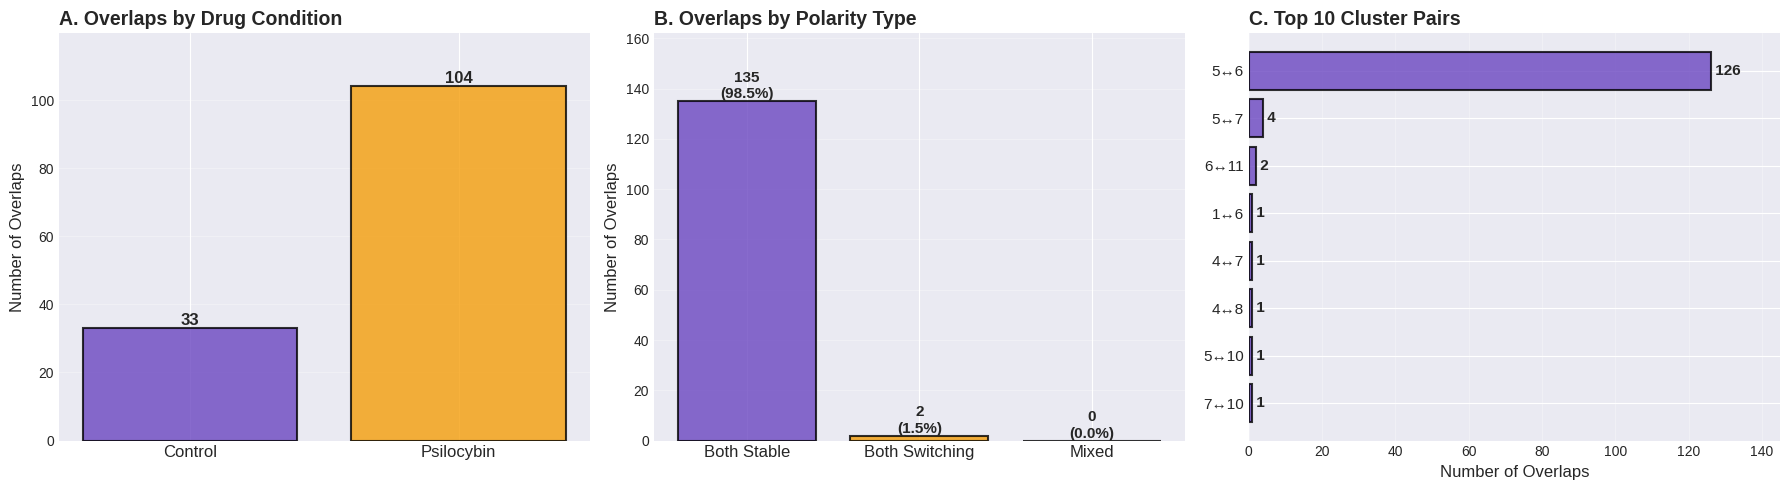


✓ Combined visualization saved!


In [26]:
# ============================================================================
# VISUALIZATION: COMBINED FIGURE (A-C)
# ============================================================================
print("\n" + "="*80)
print("VISUALIZATION: COMBINED ANALYSIS FIGURE")
print("="*80)

import matplotlib.pyplot as plt
import seaborn as sns

# Create figure with 3 subplots
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

# Define purple-golden yellow color scheme (darker purple)
color_purple = '#6B46C1'  # Darker purple
color_gold = '#F59E0B'     # Golden yellow
color_purple_light = '#8B5CF6'  # Medium purple

# A. Overlaps by Drug Condition
drugs = sorted(overlaps_by_drug.keys())
drug_counts = [len(overlaps_by_drug[drug]) for drug in drugs]

colors_drug = [color_purple if 'Control' in drug else color_gold for drug in drugs]
bars1 = ax1.bar(range(len(drugs)), drug_counts, color=colors_drug, alpha=0.8, 
                edgecolor='black', linewidth=1.5)
ax1.set_xticks(range(len(drugs)))
ax1.set_xticklabels(drugs, fontsize=12)
ax1.set_ylabel('Number of Overlaps', fontsize=12)
ax1.set_title('A. Overlaps by Drug Condition', fontsize=14, fontweight='bold', loc='left')
ax1.grid(axis='y', alpha=0.3)
ax1.set_ylim(0, max(drug_counts) * 1.15)

# Add value labels on top of bars
for i, (bar, count) in enumerate(zip(bars1, drug_counts)):
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height,
            f'{count}',
            ha='center', va='bottom', fontsize=12, fontweight='bold')

# B. Polarity Type Distribution
polarity_types = ['both_stable', 'both_switching', 'mixed']
polarity_labels = ['Both Stable', 'Both Switching', 'Mixed']
polarity_counts = [n_both_stable, n_both_switching, n_mixed]
polarity_colors = [color_purple, color_gold, color_purple_light]

bars2 = ax2.bar(range(len(polarity_types)), polarity_counts, color=polarity_colors, 
                alpha=0.8, edgecolor='black', linewidth=1.5)
ax2.set_xticks(range(len(polarity_types)))
ax2.set_xticklabels(polarity_labels, fontsize=12)
ax2.set_ylabel('Number of Overlaps', fontsize=12)
ax2.set_title('B. Overlaps by Polarity Type', fontsize=14, fontweight='bold', loc='left')
ax2.grid(axis='y', alpha=0.3)
ax2.set_ylim(0, max(polarity_counts) * 1.2)

# Add value labels with percentages on top of bars
for i, (bar, count) in enumerate(zip(bars2, polarity_counts)):
    height = bar.get_height()
    pct = count / total_overlaps * 100 if total_overlaps > 0 else 0
    ax2.text(bar.get_x() + bar.get_width()/2., height,
            f'{count}\n({pct:.1f}%)',
            ha='center', va='bottom', fontsize=11, fontweight='bold')

# C. Top 10 Cluster Pairs - all in darker purple
top_10_pairs = cluster_pairs[:10]
pair_labels = [f"{c1}↔{c2}" for c1, c2, _ in top_10_pairs]
pair_counts = [count for _, _, count in top_10_pairs]

bars3 = ax3.barh(range(len(top_10_pairs)), pair_counts, color=color_purple, alpha=0.8, 
                 edgecolor='black', linewidth=1.5)
ax3.set_yticks(range(len(top_10_pairs)))
ax3.set_yticklabels(pair_labels, fontsize=11)
ax3.set_xlabel('Number of Overlaps', fontsize=12)
ax3.set_title('C. Top 10 Cluster Pairs', fontsize=14, fontweight='bold', loc='left')
ax3.grid(axis='x', alpha=0.3)
ax3.invert_yaxis()
ax3.set_xlim(0, max(pair_counts) * 1.15)

# Add value labels at the end of bars
for i, (bar, count) in enumerate(zip(bars3, pair_counts)):
    width = bar.get_width()
    ax3.text(width, bar.get_y() + bar.get_height()/2.,
            f' {count}',
            ha='left', va='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('overlap_analysis_combined.png', dpi=300, bbox_inches='tight')
print("\nSaved: overlap_analysis_combined.png")
plt.show()

print("\n✓ Combined visualization saved!")

In [22]:
import pickle
import numpy as np
from collections import defaultdict

print("="*80)
print("COMBINED CLUSTERS 5+6 BURST ANALYSIS")
print("="*80)
print("\nThis script analyzes clusters 5 and 6 as a SINGLE COMBINED cluster")
print("  - All activations from both clusters are pooled together")
print("  - Bursts can contain activations from either cluster 5 or 6")
print("  - Statistics treat 5+6 as one entity")
print()

# ============================================================================
# CONFIGURATION
# ============================================================================

class BurstConfig:
    """Centralized configuration for burst detection"""
    
    # Burst detection parameters
    MAX_INTERVAL_MS = 50           # Maximum interval between activations in a burst
    MIN_BURST_LENGTH = 2           # Minimum number of activations to count as burst
    CORRELATION_THRESHOLD = 0.825    # Minimum |correlation| to include activation
    
    # Interval ranges for detailed analysis
    INTERVAL_RANGES = [
        (0, 50, "0-50ms"),
        (50, 100, "50-100ms")
    ]
    
    # Only analyze clusters 5 and 6
    CLUSTERS_TO_ANALYZE = [5, 6]
    
    # Overlap detection
    MIN_OVERLAP_MS = 50  # Minimum overlap duration to report
    
    @classmethod
    def print_config(cls):
        print("BURST DETECTION CONFIGURATION:")
        print(f"  Max interval between activations: {cls.MAX_INTERVAL_MS}ms")
        print(f"  Min burst length: {cls.MIN_BURST_LENGTH} activations")
        print(f"  Correlation threshold: |r| > {cls.CORRELATION_THRESHOLD}")
        print(f"  Analyzing: Clusters 5+6 COMBINED")
        print(f"  Interval ranges: {[r[2] for r in cls.INTERVAL_RANGES]}")
        print()

config = BurstConfig()
config.print_config()

# ============================================================================
# LOAD DATA
# ============================================================================
print("Loading data...")

with open('/home/novicky/clean_code/similarity_blocks_with_polarity_3/cluster_analysis_k10.0_no_threshold.pkl', 'rb') as f:
    results = pickle.load(f)

with open('/home/novicky/metadata.pkl', 'rb') as f:
    file_metadata = pickle.load(f)

with open('/home/novicky/clean_code/similarity_blocks_with_polarity_3/cluster_averages.pkl', 'rb') as f:
    cluster_averages = pickle.load(f)

cluster_activation_times = results['cluster_activation_times']

# Get cluster pattern durations (in seconds)
cluster_durations = {}
for cluster_id in [5, 6]:
    n_timepoints = cluster_averages[cluster_id].shape[1]
    duration_sec = n_timepoints / 250.0  # 250 Hz sampling rate (consistent with original)
    cluster_durations[cluster_id] = duration_sec

print(f"Loaded activation data")
print(f"Loaded metadata for {len(file_metadata)} datasets")
print(f"Cluster 5 duration: {cluster_durations[5]*1000:.1f}ms")
print(f"Cluster 6 duration: {cluster_durations[6]*1000:.1f}ms")
print()

# ============================================================================
# COMBINE ACTIVATIONS FROM CLUSTERS 5 AND 6
# ============================================================================
print("="*80)
print("COMBINING ACTIVATIONS FROM CLUSTERS 5 AND 6")
print("="*80)

# Organize all activations by dataset
combined_activations_by_dataset = defaultdict(list)

total_activations_c5 = 0
total_activations_c6 = 0

for cluster_id in [5, 6]:
    cluster_duration = cluster_durations[cluster_id]
    
    for dataset_idx, times, polarities, correlations in cluster_activation_times[cluster_id]:
        # Filter by correlation threshold
        high_corr_mask = np.abs(correlations) > config.CORRELATION_THRESHOLD
        times_filtered = times[high_corr_mask]
        polarities_filtered = polarities[high_corr_mask]
        correlations_filtered = correlations[high_corr_mask]
        
        # Add each activation to the combined pool
        for i in range(len(times_filtered)):
            combined_activations_by_dataset[dataset_idx].append({
                'time': times_filtered[i],
                'polarity': polarities_filtered[i],
                'correlation': correlations_filtered[i],
                'cluster_id': cluster_id,
                'duration': cluster_duration
            })
            
            if cluster_id == 5:
                total_activations_c5 += 1
            else:
                total_activations_c6 += 1

print(f"Cluster 5 activations: {total_activations_c5}")
print(f"Cluster 6 activations: {total_activations_c6}")
print(f"Total combined activations: {total_activations_c5 + total_activations_c6}")
print(f"Datasets with activations: {len(combined_activations_by_dataset)}")
print()

# ============================================================================
# BURST DETECTION ON COMBINED DATA
# ============================================================================

def detect_bursts_combined(activations, dataset_idx):
    """
    Detect bursts from combined cluster 5+6 activations.
    
    Activations can be from either cluster 5 or 6.
    """
    if len(activations) < config.MIN_BURST_LENGTH:
        return []
    
    # Sort activations by time
    activations_sorted = sorted(activations, key=lambda x: x['time'])
    
    bursts = []
    
    # Start first burst
    current_burst = {
        'times': [activations_sorted[0]['time']],
        'polarities': [activations_sorted[0]['polarity']],
        'correlations': [activations_sorted[0]['correlation']],
        'cluster_ids': [activations_sorted[0]['cluster_id']],
        'durations': [activations_sorted[0]['duration']],
        'intervals': []
    }
    
    # Process remaining activations
    for i in range(1, len(activations_sorted)):
        curr_act = activations_sorted[i]
        prev_act = activations_sorted[i-1]
        
        # Calculate interval from START to START (consistent with original script)
        interval_ms = (curr_act['time'] - prev_act['time']) * 1000
        
        # Check for overlap: current starts before previous ends
        prev_end_time = prev_act['time'] + prev_act['duration']
        has_overlap = curr_act['time'] < prev_end_time
        
        # Only continue burst if:
        # 1. No overlap (strictly sequential)
        # 2. Interval is less than MAX_INTERVAL_MS
        if not has_overlap and interval_ms < config.MAX_INTERVAL_MS:
            # Continue current burst
            current_burst['times'].append(curr_act['time'])
            current_burst['polarities'].append(curr_act['polarity'])
            current_burst['correlations'].append(curr_act['correlation'])
            current_burst['cluster_ids'].append(curr_act['cluster_id'])
            current_burst['durations'].append(curr_act['duration'])
            current_burst['intervals'].append(interval_ms)
        else:
            # Save current burst if long enough
            if len(current_burst['times']) >= config.MIN_BURST_LENGTH:
                burst = finalize_burst(current_burst, dataset_idx)
                bursts.append(burst)
            
            # Start new burst
            current_burst = {
                'times': [curr_act['time']],
                'polarities': [curr_act['polarity']],
                'correlations': [curr_act['correlation']],
                'cluster_ids': [curr_act['cluster_id']],
                'durations': [curr_act['duration']],
                'intervals': []
            }
    
    # Don't forget the last burst
    if len(current_burst['times']) >= config.MIN_BURST_LENGTH:
        burst = finalize_burst(current_burst, dataset_idx)
        bursts.append(burst)
    
    return bursts

def finalize_burst(burst_data, dataset_idx):
    """Convert burst data into final burst dictionary"""
    metadata = file_metadata[dataset_idx]
    
    # Calculate burst duration (from start of first to end of last activation)
    # End time = start of last activation + its duration
    last_duration = burst_data['durations'][-1]
    burst_duration = (burst_data['times'][-1] - burst_data['times'][0]) * 1000 + last_duration * 1000
    
    # Calculate polarity switches and patterns
    n_switches = 0
    n_stable = 0
    for j in range(len(burst_data['polarities']) - 1):
        if burst_data['polarities'][j] * burst_data['polarities'][j+1] < 0:
            n_switches += 1
        else:
            n_stable += 1
    
    total_transitions = n_switches + n_stable
    switch_rate = (n_switches / total_transitions * 100) if total_transitions > 0 else 0
    
    # Determine polarity type
    if len(burst_data['polarities']) == 1:
        polarity_type = 'stable'
    else:
        all_same = all(p == burst_data['polarities'][0] for p in burst_data['polarities'])
        
        if all_same:
            polarity_type = 'stable'
        elif n_switches > 0 and n_stable > 0:
            polarity_type = 'mixed'
        elif n_switches > 0:
            polarity_type = 'switching'
        else:
            polarity_type = 'stable'
    
    # Determine interval range (all intervals must fit in one range)
    interval_range = None
    if len(burst_data['intervals']) > 0:
        for min_int, max_int, label in config.INTERVAL_RANGES:
            if all(min_int <= interval < max_int for interval in burst_data['intervals']):
                interval_range = label
                break
    
    # Count activations from each cluster
    n_cluster5 = sum(1 for c in burst_data['cluster_ids'] if c == 5)
    n_cluster6 = sum(1 for c in burst_data['cluster_ids'] if c == 6)
    
    return {
        'dataset': dataset_idx,
        'start_time': burst_data['times'][0],
        'end_time': burst_data['times'][-1] + last_duration,
        'length': len(burst_data['times']),
        'duration': burst_duration,
        'intervals': burst_data['intervals'].copy(),
        'interval_range': interval_range,
        'n_switches': n_switches,
        'n_stable': n_stable,
        'switch_rate': switch_rate,
        'polarity_type': polarity_type,
        'polarities': burst_data['polarities'].copy(),
        'correlations': burst_data['correlations'].copy(),
        'cluster_ids': burst_data['cluster_ids'].copy(),
        'n_cluster5': n_cluster5,
        'n_cluster6': n_cluster6,
        'drug': metadata.get('drug_condition', 'Unknown'),
        'task': metadata.get('task', 'Unknown'),
        'subject_id': metadata.get('subject_id', 'Unknown'),
        'subject_number': metadata.get('subject_number', 'Unknown'),
        'is_trained': metadata.get('is_trained', None)
    }

# ============================================================================
# DETECT ALL BURSTS
# ============================================================================
print("="*80)
print("DETECTING BURSTS FROM COMBINED CLUSTERS 5+6")
print("="*80)

all_bursts = []
n_overlaps_detected = 0  # Track overlapping activations

for dataset_idx, activations in combined_activations_by_dataset.items():
    bursts = detect_bursts_combined(activations, dataset_idx)
    all_bursts.extend(bursts)
    
    # Check for overlaps in the sorted activations
    activations_sorted = sorted(activations, key=lambda x: x['time'])
    for i in range(1, len(activations_sorted)):
        curr_start = activations_sorted[i]['time']
        prev_end = activations_sorted[i-1]['time'] + activations_sorted[i-1]['duration']
        if curr_start < prev_end:
            n_overlaps_detected += 1

print(f"Total bursts detected: {len(all_bursts)}")
print(f"Overlapping activations detected (excluded from bursts): {n_overlaps_detected}")
if n_overlaps_detected > 0:
    print(f"  → These overlapping activations were not included in burst sequences")
else:
    print(f"  ✓ No overlaps detected - all activations are sequential")
print()

if len(all_bursts) > 0:
    # Burst composition statistics with polarity breakdown
    pure_c5 = sum(1 for b in all_bursts if b['n_cluster6'] == 0)
    pure_c6 = sum(1 for b in all_bursts if b['n_cluster5'] == 0)
    mixed_bursts = sum(1 for b in all_bursts if b['n_cluster5'] > 0 and b['n_cluster6'] > 0)
    
    print(f"\nBurst composition:")
    print(f"  Pure cluster 5 bursts: {pure_c5} ({pure_c5/len(all_bursts)*100:.1f}%)")
    print(f"  Pure cluster 6 bursts: {pure_c6} ({pure_c6/len(all_bursts)*100:.1f}%)")
    print(f"  Mixed (5+6) bursts:    {mixed_bursts} ({mixed_bursts/len(all_bursts)*100:.1f}%)")
    
    # Polarity breakdown by cluster composition
    print(f"\nPolarity distribution by cluster composition:")
    
    # Pure cluster 5
    pure_c5_bursts = [b for b in all_bursts if b['n_cluster6'] == 0]
    if len(pure_c5_bursts) > 0:
        c5_stable = sum(1 for b in pure_c5_bursts if b['polarity_type'] == 'stable')
        c5_switching = sum(1 for b in pure_c5_bursts if b['polarity_type'] == 'switching')
        c5_mixed = sum(1 for b in pure_c5_bursts if b['polarity_type'] == 'mixed')
        print(f"  Pure Cluster 5 ({len(pure_c5_bursts)} bursts):")
        print(f"    Stable:    {c5_stable} ({c5_stable/len(pure_c5_bursts)*100:.1f}%)")
        print(f"    Switching: {c5_switching} ({c5_switching/len(pure_c5_bursts)*100:.1f}%)")
        print(f"    Mixed:     {c5_mixed} ({c5_mixed/len(pure_c5_bursts)*100:.1f}%)")
    
    # Pure cluster 6
    pure_c6_bursts = [b for b in all_bursts if b['n_cluster5'] == 0]
    if len(pure_c6_bursts) > 0:
        c6_stable = sum(1 for b in pure_c6_bursts if b['polarity_type'] == 'stable')
        c6_switching = sum(1 for b in pure_c6_bursts if b['polarity_type'] == 'switching')
        c6_mixed = sum(1 for b in pure_c6_bursts if b['polarity_type'] == 'mixed')
        print(f"  Pure Cluster 6 ({len(pure_c6_bursts)} bursts):")
        print(f"    Stable:    {c6_stable} ({c6_stable/len(pure_c6_bursts)*100:.1f}%)")
        print(f"    Switching: {c6_switching} ({c6_switching/len(pure_c6_bursts)*100:.1f}%)")
        print(f"    Mixed:     {c6_mixed} ({c6_mixed/len(pure_c6_bursts)*100:.1f}%)")
    
    # Mixed bursts
    mixed_bursts_list = [b for b in all_bursts if b['n_cluster5'] > 0 and b['n_cluster6'] > 0]
    if len(mixed_bursts_list) > 0:
        mixed_stable = sum(1 for b in mixed_bursts_list if b['polarity_type'] == 'stable')
        mixed_switching = sum(1 for b in mixed_bursts_list if b['polarity_type'] == 'switching')
        mixed_mixed = sum(1 for b in mixed_bursts_list if b['polarity_type'] == 'mixed')
        print(f"  Mixed (5+6) bursts ({len(mixed_bursts_list)} bursts):")
        print(f"    Stable:    {mixed_stable} ({mixed_stable/len(mixed_bursts_list)*100:.1f}%)")
        print(f"    Switching: {mixed_switching} ({mixed_switching/len(mixed_bursts_list)*100:.1f}%)")
        print(f"    Mixed:     {mixed_mixed} ({mixed_mixed/len(mixed_bursts_list)*100:.1f}%)")
    
    # Breakdown by drug condition for each cluster type
    print(f"\nPolarity distribution by cluster composition AND drug condition:")
    
    for cluster_type, cluster_filter in [
        ("Pure Cluster 5", lambda b: b['n_cluster6'] == 0),
        ("Pure Cluster 6", lambda b: b['n_cluster5'] == 0),
        ("Mixed (5+6)", lambda b: b['n_cluster5'] > 0 and b['n_cluster6'] > 0)
    ]:
        cluster_bursts = [b for b in all_bursts if cluster_filter(b)]
        if len(cluster_bursts) == 0:
            continue
        
        print(f"\n  {cluster_type}:")
        
        # Control
        ctrl_bursts = [b for b in cluster_bursts if b['drug'] == 'Control']
        if len(ctrl_bursts) > 0:
            ctrl_stable = sum(1 for b in ctrl_bursts if b['polarity_type'] == 'stable')
            ctrl_switching = sum(1 for b in ctrl_bursts if b['polarity_type'] == 'switching')
            ctrl_mixed = sum(1 for b in ctrl_bursts if b['polarity_type'] == 'mixed')
            print(f"    Control ({len(ctrl_bursts)} bursts):")
            print(f"      Stable:    {ctrl_stable} ({ctrl_stable/len(ctrl_bursts)*100:.1f}%)")
            print(f"      Switching: {ctrl_switching} ({ctrl_switching/len(ctrl_bursts)*100:.1f}%)")
            print(f"      Mixed:     {ctrl_mixed} ({ctrl_mixed/len(ctrl_bursts)*100:.1f}%)")
        
        # Psilocybin
        psi_bursts = [b for b in cluster_bursts if b['drug'] == 'Psilocybin']
        if len(psi_bursts) > 0:
            psi_stable = sum(1 for b in psi_bursts if b['polarity_type'] == 'stable')
            psi_switching = sum(1 for b in psi_bursts if b['polarity_type'] == 'switching')
            psi_mixed = sum(1 for b in psi_bursts if b['polarity_type'] == 'mixed')
            print(f"    Psilocybin ({len(psi_bursts)} bursts):")
            print(f"      Stable:    {psi_stable} ({psi_stable/len(psi_bursts)*100:.1f}%)")
            print(f"      Switching: {psi_switching} ({psi_switching/len(psi_bursts)*100:.1f}%)")
            print(f"      Mixed:     {psi_mixed} ({psi_mixed/len(psi_bursts)*100:.1f}%)")
    
    # Validation
    min_detected = min(b['length'] for b in all_bursts)
    max_detected = max(b['length'] for b in all_bursts)
    mean_detected = np.mean([b['length'] for b in all_bursts])
    
    print(f"\nBurst Length Statistics:")
    print(f"  Min:  {min_detected}")
    print(f"  Max:  {max_detected}")
    print(f"  Mean: {mean_detected:.2f}")
    
    if min_detected < config.MIN_BURST_LENGTH:
        print(f"\n⚠️  WARNING: Detected bursts with length {min_detected}, but MIN_BURST_LENGTH = {config.MIN_BURST_LENGTH}")
    else:
        print(f"  ✓ Validation: All bursts have length ≥ {config.MIN_BURST_LENGTH}")
    
    # Polarity type distribution
    print(f"\nPolarity Type Distribution:")
    stable_count = sum(1 for b in all_bursts if b['polarity_type'] == 'stable')
    switching_count = sum(1 for b in all_bursts if b['polarity_type'] == 'switching')
    mixed_count = sum(1 for b in all_bursts if b['polarity_type'] == 'mixed')
    
    print(f"  Stable:    {stable_count:5d} ({stable_count/len(all_bursts)*100:.1f}%)")
    print(f"  Switching: {switching_count:5d} ({switching_count/len(all_bursts)*100:.1f}%)")
    print(f"  Mixed:     {mixed_count:5d} ({mixed_count/len(all_bursts)*100:.1f}%)")

print()

# ============================================================================
# ANALYSIS 1: BURST LENGTH DISTRIBUTION BY DRUG CONDITION
# ============================================================================
print("="*80)
print("ANALYSIS 1: BURST LENGTH DISTRIBUTION")
print("="*80)
print("Comparing Control vs Psilocybin\n")

# Separate by drug condition
ctrl_lengths = [b['length'] for b in all_bursts if b['drug'] == 'Control']
psi_lengths = [b['length'] for b in all_bursts if b['drug'] == 'Psilocybin']

print(f"Total Bursts:")
print(f"  Control:    {len(ctrl_lengths):4d} bursts")
print(f"  Psilocybin: {len(psi_lengths):4d} bursts")

if len(ctrl_lengths) > 0 or len(psi_lengths) > 0:
    print(f"\nDescriptive Statistics:")

if len(ctrl_lengths) > 0:
    print(f"  Control:    Mean={np.mean(ctrl_lengths):.2f}, Median={np.median(ctrl_lengths):.0f}, "
          f"75th%={np.percentile(ctrl_lengths, 75):.0f}, 90th%={np.percentile(ctrl_lengths, 90):.0f}, "
          f"Max={np.max(ctrl_lengths):.0f}")

if len(psi_lengths) > 0:
    print(f"  Psilocybin: Mean={np.mean(psi_lengths):.2f}, Median={np.median(psi_lengths):.0f}, "
          f"75th%={np.percentile(psi_lengths, 75):.0f}, 90th%={np.percentile(psi_lengths, 90):.0f}, "
          f"Max={np.max(psi_lengths):.0f}")

# Distribution table
if len(ctrl_lengths) > 0 or len(psi_lengths) > 0:
    max_length = max(
        max(ctrl_lengths) if len(ctrl_lengths) > 0 else 0,
        max(psi_lengths) if len(psi_lengths) > 0 else 0
    )
    
    print(f"\nBurst Length Distribution:")
    print(f"  Length | Control | Psilocybin")
    print(f"  -------|---------|------------")
    
    for length in range(2, min(int(max_length) + 1, 15)):
        ctrl_count = sum(1 for l in ctrl_lengths if l == length)
        psi_count = sum(1 for l in psi_lengths if l == length)
        if ctrl_count > 0 or psi_count > 0:
            print(f"  {length:4d}   | {ctrl_count:7d} | {psi_count:10d}")
    
    if max_length >= 15:
        ctrl_count_15plus = sum(1 for l in ctrl_lengths if l >= 15)
        psi_count_15plus = sum(1 for l in psi_lengths if l >= 15)
        if ctrl_count_15plus > 0 or psi_count_15plus > 0:
            print(f"  15+    | {ctrl_count_15plus:7d} | {psi_count_15plus:10d}")

print()

# ============================================================================
# ANALYSIS 1a: BURST DISTRIBUTION BY TASK
# ============================================================================
print("="*80)
print("ANALYSIS 1a: BURST DISTRIBUTION BY TASK")
print("="*80)
print("Within each drug condition\n")

tasks = ['Meditation', 'Music', 'Resting state', 'Video']

# Organize by drug and task
ctrl_by_task = {task: [] for task in tasks}
psi_by_task = {task: [] for task in tasks}

for burst in all_bursts:
    if burst['task'] in tasks:
        if burst['drug'] == 'Control':
            ctrl_by_task[burst['task']].append(burst['length'])
        elif burst['drug'] == 'Psilocybin':
            psi_by_task[burst['task']].append(burst['length'])

# Control condition
print("CONTROL:")
for task in tasks:
    if len(ctrl_by_task[task]) > 0:
        mean_len = np.mean(ctrl_by_task[task])
        std_len = np.std(ctrl_by_task[task]) if len(ctrl_by_task[task]) > 1 else 0.0
        print(f"  {task:15s}: {mean_len:.2f}±{std_len:.2f} (n={len(ctrl_by_task[task])} bursts)")

# Psilocybin condition
print("\nPSILOCYBIN:")
for task in tasks:
    if len(psi_by_task[task]) > 0:
        mean_len = np.mean(psi_by_task[task])
        std_len = np.std(psi_by_task[task]) if len(psi_by_task[task]) > 1 else 0.0
        print(f"  {task:15s}: {mean_len:.2f}±{std_len:.2f} (n={len(psi_by_task[task])} bursts)")

print()

# ============================================================================
# ANALYSIS 2: PARTICIPANT-LEVEL BURST PATTERNS
# ============================================================================
print("="*80)
print("ANALYSIS 2: BURST PATTERNS PER PARTICIPANT")
print("="*80)
print("Showing only participants with ≥3 bursts\n")

# Count bursts per participant
participant_burst_counts = defaultdict(lambda: {'count': 0, 'drug': None, 'task': None})

for burst in all_bursts:
    subject_key = f"{burst['subject_id']}_{burst['subject_number']}"
    participant_burst_counts[subject_key]['count'] += 1
    participant_burst_counts[subject_key]['drug'] = burst['drug']
    participant_burst_counts[subject_key]['task'] = burst['task']

# Filter to participants with >=3 bursts
filtered_participants = {k: v for k, v in participant_burst_counts.items() 
                        if v['count'] >= 3}

# Sort by burst count
sorted_participants = sorted(filtered_participants.items(), 
                             key=lambda x: x[1]['count'], reverse=True)

print(f"Total bursts: {len(all_bursts)}")
print(f"Participants with ≥3 bursts: {len(filtered_participants)}")

# Show distribution
ctrl_counts = [data['count'] for _, data in sorted_participants if data['drug'] == 'Control']
psi_counts = [data['count'] for _, data in sorted_participants if data['drug'] == 'Psilocybin']

if len(ctrl_counts) > 0:
    print(f"\nControl - Mean: {np.mean(ctrl_counts):.1f}, Median: {np.median(ctrl_counts):.0f}, "
          f"Max: {np.max(ctrl_counts):.0f} (n={len(ctrl_counts)} participants)")
if len(psi_counts) > 0:
    print(f"Psilocybin - Mean: {np.mean(psi_counts):.1f}, Median: {np.median(psi_counts):.0f}, "
          f"Max: {np.max(psi_counts):.0f} (n={len(psi_counts)} participants)")

# Show top 10 participants
print(f"\nTop 10 most active participants:")
for i, (subject, data) in enumerate(sorted_participants[:10], 1):
    print(f"  {i:2d}. {subject:20s}: {data['count']:3d} bursts | {data['drug']:11s} | {data['task']}")

print()

# ============================================================================
# ANALYSIS 3: POLARITY TYPE BY INTERVAL RANGE
# ============================================================================
print("="*80)
print("ANALYSIS 3: POLARITY TYPE BY INTERVAL RANGE")
print("="*80)
print("Stable = all same polarity")
print("Switching = alternating polarities") 
print("Mixed = both polarities present but not alternating\n")

# Categorize bursts
results = {}
for _, _, range_label in config.INTERVAL_RANGES:
    results[range_label] = {
        'Control': {'stable': [], 'switching': [], 'mixed': []},
        'Psilocybin': {'stable': [], 'switching': [], 'mixed': []}
    }

for burst in all_bursts:
    if burst['interval_range'] is None:
        continue
    
    polarity_type = burst['polarity_type']
    drug = burst['drug']
    if drug in results[burst['interval_range']]:
        results[burst['interval_range']][drug][polarity_type].append(burst['length'])

for _, _, range_label in config.INTERVAL_RANGES:
    range_data = results[range_label]
    
    # Check if this range has any data
    range_has_data = any(
        len(range_data[drug][ptype]) > 0
        for drug in ['Control', 'Psilocybin']
        for ptype in ['stable', 'switching', 'mixed']
    )
    
    if not range_has_data:
        continue
    
    print(f"{range_label}:")
    
    for drug in ['Control', 'Psilocybin']:
        stable_bursts = range_data[drug]['stable']
        switching_bursts = range_data[drug]['switching']
        mixed_bursts = range_data[drug]['mixed']
        
        if len(stable_bursts) > 0 or len(switching_bursts) > 0 or len(mixed_bursts) > 0:
            print(f"  {drug}:")
            
            if len(stable_bursts) > 0:
                mean_len = np.mean(stable_bursts)
                std_len = np.std(stable_bursts) if len(stable_bursts) > 1 else 0.0
                print(f"    Stable:    {len(stable_bursts):3d} bursts, mean length {mean_len:.2f}±{std_len:.2f}")
            
            if len(switching_bursts) > 0:
                mean_len = np.mean(switching_bursts)
                std_len = np.std(switching_bursts) if len(switching_bursts) > 1 else 0.0
                print(f"    Switching: {len(switching_bursts):3d} bursts, mean length {mean_len:.2f}±{std_len:.2f}")
            
            if len(mixed_bursts) > 0:
                mean_len = np.mean(mixed_bursts)
                std_len = np.std(mixed_bursts) if len(mixed_bursts) > 1 else 0.0
                print(f"    Mixed:     {len(mixed_bursts):3d} bursts, mean length {mean_len:.2f}±{std_len:.2f}")

print()

# ============================================================================
# ANALYSIS 4: POLARITY DISTRIBUTION BY DRUG CONDITION AND TASK
# ============================================================================
print("="*80)
print("ANALYSIS 4: POLARITY DISTRIBUTION BY DRUG CONDITION AND TASK")
print("="*80)
print("Analyzing 0-50ms bursts only\n")

# Filter to only bursts in 0-50ms range
bursts_0_50 = [b for b in all_bursts if b['interval_range'] == '0-50ms']

print(f"Total 0-50ms bursts: {len(bursts_0_50)}\n")

# ============================================================================
# 4a. Total distribution by Drug Condition (0-50ms only)
# ============================================================================
print("-" * 80)
print("4a. OVERALL POLARITY DISTRIBUTION BY DRUG CONDITION")
print("-" * 80)

ctrl_stable = sum(1 for b in bursts_0_50 if b['drug'] == 'Control' and b['polarity_type'] == 'stable')
ctrl_switching = sum(1 for b in bursts_0_50 if b['drug'] == 'Control' and b['polarity_type'] == 'switching')
ctrl_mixed = sum(1 for b in bursts_0_50 if b['drug'] == 'Control' and b['polarity_type'] == 'mixed')
psi_stable = sum(1 for b in bursts_0_50 if b['drug'] == 'Psilocybin' and b['polarity_type'] == 'stable')
psi_switching = sum(1 for b in bursts_0_50 if b['drug'] == 'Psilocybin' and b['polarity_type'] == 'switching')
psi_mixed = sum(1 for b in bursts_0_50 if b['drug'] == 'Psilocybin' and b['polarity_type'] == 'mixed')

ctrl_total = ctrl_stable + ctrl_switching + ctrl_mixed
psi_total = psi_stable + psi_switching + psi_mixed

if ctrl_total > 0:
    print(f"\nControl ({ctrl_total} bursts):")
    print(f"  Stable:    {ctrl_stable:4d} ({ctrl_stable/ctrl_total*100:.1f}%)")
    print(f"  Switching: {ctrl_switching:4d} ({ctrl_switching/ctrl_total*100:.1f}%)")
    print(f"  Mixed:     {ctrl_mixed:4d} ({ctrl_mixed/ctrl_total*100:.1f}%)")
else:
    print(f"\nControl: No bursts in 0-50ms range")

if psi_total > 0:
    print(f"\nPsilocybin ({psi_total} bursts):")
    print(f"  Stable:    {psi_stable:4d} ({psi_stable/psi_total*100:.1f}%)")
    print(f"  Switching: {psi_switching:4d} ({psi_switching/psi_total*100:.1f}%)")
    print(f"  Mixed:     {psi_mixed:4d} ({psi_mixed/psi_total*100:.1f}%)")
else:
    print(f"\nPsilocybin: No bursts in 0-50ms range")

# ============================================================================
# 4b. Distribution by Task (within each drug condition, 0-50ms only)
# ============================================================================
print("\n" + "-" * 80)
print("4b. POLARITY DISTRIBUTION BY TASK (within each drug condition)")
print("-" * 80)

for drug in ['Control', 'Psilocybin']:
    print(f"\n{drug.upper()}:")
    
    drug_has_data = False
    for task in tasks:
        task_bursts = [b for b in bursts_0_50 if b['drug'] == drug and b['task'] == task]
        
        if len(task_bursts) == 0:
            continue
        
        drug_has_data = True
        stable = sum(1 for b in task_bursts if b['polarity_type'] == 'stable')
        switching = sum(1 for b in task_bursts if b['polarity_type'] == 'switching')
        mixed = sum(1 for b in task_bursts if b['polarity_type'] == 'mixed')
        total = len(task_bursts)
        
        print(f"  {task:15s}: {total:3d} bursts")
        print(f"    Stable:    {stable:3d} ({stable/total*100:.1f}%)")
        print(f"    Switching: {switching:3d} ({switching/total*100:.1f}%)")
        print(f"    Mixed:     {mixed:3d} ({mixed/total*100:.1f}%)")
    
    if not drug_has_data:
        print(f"  No 0-50ms bursts for {drug}")

# ============================================================================
# 4c. Switch rate statistics by drug and task
# ============================================================================
print("\n" + "-" * 80)
print("4c. POLARITY SWITCH RATE STATISTICS")
print("-" * 80)
print("(Average percentage of polarity switches per burst)\n")

for drug in ['Control', 'Psilocybin']:
    print(f"{drug.upper()}:")
    
    drug_has_data = False
    for task in tasks:
        task_bursts = [b for b in bursts_0_50 if b['drug'] == drug and b['task'] == task]
        
        if len(task_bursts) == 0:
            continue
        
        drug_has_data = True
        switch_rates = [b['switch_rate'] for b in task_bursts]
        
        print(f"  {task:15s}: Mean={np.mean(switch_rates):.1f}%, "
              f"Median={np.median(switch_rates):.1f}%, "
              f"Std={np.std(switch_rates):.1f}% (n={len(task_bursts)})")
    
    if not drug_has_data:
        print(f"  No data for {drug}")
    print()

# ============================================================================
# 4d. Polarity Distribution (0-50ms bursts)
# ============================================================================
print("-" * 80)
print("4d. DETAILED POLARITY DISTRIBUTION (0-50ms bursts)")
print("-" * 80)

if len(bursts_0_50) > 0:
    stable = sum(1 for b in bursts_0_50 if b['polarity_type'] == 'stable')
    switching = sum(1 for b in bursts_0_50 if b['polarity_type'] == 'switching')
    mixed = sum(1 for b in bursts_0_50 if b['polarity_type'] == 'mixed')
    total = len(bursts_0_50)
    
    print(f"\nCombined Clusters 5+6: {total} bursts")
    print(f"  Stable:    {stable:3d} ({stable/total*100:5.1f}%)")
    print(f"  Switching: {switching:3d} ({switching/total*100:5.1f}%)")
    print(f"  Mixed:     {mixed:3d} ({mixed/total*100:5.1f}%)")
    
    # Breakdown by drug condition
    ctrl_bursts = [b for b in bursts_0_50 if b['drug'] == 'Control']
    psi_bursts = [b for b in bursts_0_50 if b['drug'] == 'Psilocybin']
    
    if len(ctrl_bursts) > 0:
        ctrl_stable = sum(1 for b in ctrl_bursts if b['polarity_type'] == 'stable')
        ctrl_switching = sum(1 for b in ctrl_bursts if b['polarity_type'] == 'switching')
        ctrl_mixed = sum(1 for b in ctrl_bursts if b['polarity_type'] == 'mixed')
        print(f"\n  Control:    {len(ctrl_bursts):2d} bursts → S:{ctrl_stable} Sw:{ctrl_switching} M:{ctrl_mixed}")
    
    if len(psi_bursts) > 0:
        psi_stable = sum(1 for b in psi_bursts if b['polarity_type'] == 'stable')
        psi_switching = sum(1 for b in psi_bursts if b['polarity_type'] == 'switching')
        psi_mixed = sum(1 for b in psi_bursts if b['polarity_type'] == 'mixed')
        print(f"  Psilocybin: {len(psi_bursts):2d} bursts → S:{psi_stable} Sw:{psi_switching} M:{psi_mixed}")

print()

# FINAL SUMMARY
# ============================================================================
print("="*80)
print("FINAL SUMMARY - COMBINED CLUSTERS 5+6")
print("="*80)

print(f"\nTotal bursts detected: {len(all_bursts)}")

if len(all_bursts) > 0:
    # By drug condition
    ctrl_bursts = sum(1 for b in all_bursts if b['drug'] == 'Control')
    psi_bursts = sum(1 for b in all_bursts if b['drug'] == 'Psilocybin')
    
    print(f"\nBursts by drug condition:")
    print(f"  Control:    {ctrl_bursts:5d} ({ctrl_bursts/len(all_bursts)*100:.1f}%)")
    print(f"  Psilocybin: {psi_bursts:5d} ({psi_bursts/len(all_bursts)*100:.1f}%)")
    
    # By task
    print(f"\nBursts by task:")
    for task in tasks:
        task_bursts = sum(1 for b in all_bursts if b['task'] == task)
        if task_bursts > 0:
            print(f"  {task:15s}: {task_bursts:5d} ({task_bursts/len(all_bursts)*100:.1f}%)")
    
    # By interval range
    print(f"\nBursts by interval range:")
    for _, _, range_label in config.INTERVAL_RANGES:
        range_bursts = sum(1 for b in all_bursts if b['interval_range'] == range_label)
        if range_bursts > 0:
            print(f"  {range_label:10s}: {range_bursts:5d} ({range_bursts/len(all_bursts)*100:.1f}%)")
    
    # Mixed intervals
    mixed_bursts = sum(1 for b in all_bursts if b['interval_range'] is None and len(b['intervals']) > 0)
    if mixed_bursts > 0:
        print(f"  Mixed:       {mixed_bursts:5d} ({mixed_bursts/len(all_bursts)*100:.1f}%)")
    
    # By polarity type
    stable_bursts = sum(1 for b in all_bursts if b['polarity_type'] == 'stable')
    switching_bursts = sum(1 for b in all_bursts if b['polarity_type'] == 'switching')
    mixed_bursts_pol = sum(1 for b in all_bursts if b['polarity_type'] == 'mixed')
    
    print(f"\nBursts by polarity type:")
    print(f"  Stable:    {stable_bursts:5d} ({stable_bursts/len(all_bursts)*100:.1f}%)")
    print(f"  Switching: {switching_bursts:5d} ({switching_bursts/len(all_bursts)*100:.1f}%)")
    print(f"  Mixed:     {mixed_bursts_pol:5d} ({mixed_bursts_pol/len(all_bursts)*100:.1f}%)")
    
    # Burst length statistics
    burst_lengths = [b['length'] for b in all_bursts]
    print(f"\nBurst length statistics:")
    print(f"  Mean:   {np.mean(burst_lengths):.2f}")
    print(f"  Median: {np.median(burst_lengths):.0f}")
    print(f"  Min:    {np.min(burst_lengths):.0f}")
    print(f"  Max:    {np.max(burst_lengths):.0f}")
    print(f"  Std:    {np.std(burst_lengths):.2f}")
    
    # Burst composition
    pure_c5 = sum(1 for b in all_bursts if b['n_cluster6'] == 0)
    pure_c6 = sum(1 for b in all_bursts if b['n_cluster5'] == 0)
    mixed_bursts_comp = sum(1 for b in all_bursts if b['n_cluster5'] > 0 and b['n_cluster6'] > 0)
    
    print(f"\nBurst composition (cluster membership):")
    print(f"  Pure cluster 5: {pure_c5:5d} ({pure_c5/len(all_bursts)*100:.1f}%)")
    print(f"  Pure cluster 6: {pure_c6:5d} ({pure_c6/len(all_bursts)*100:.1f}%)")
    print(f"  Mixed (5+6):    {mixed_bursts_comp:5d} ({mixed_bursts_comp/len(all_bursts)*100:.1f}%)")

print("\n" + "="*80)
print("COMBINED ANALYSIS COMPLETE!")
print("="*80)

COMBINED CLUSTERS 5+6 BURST ANALYSIS

This script analyzes clusters 5 and 6 as a SINGLE COMBINED cluster
  - All activations from both clusters are pooled together
  - Bursts can contain activations from either cluster 5 or 6
  - Statistics treat 5+6 as one entity

BURST DETECTION CONFIGURATION:
  Max interval between activations: 50ms
  Min burst length: 2 activations
  Correlation threshold: |r| > 0.825
  Analyzing: Clusters 5+6 COMBINED
  Interval ranges: ['0-50ms', '50-100ms']

Loading data...
Loaded activation data
Loaded metadata for 429 datasets
Cluster 5 duration: 44.0ms
Cluster 6 duration: 44.0ms

COMBINING ACTIVATIONS FROM CLUSTERS 5 AND 6
Cluster 5 activations: 3556
Cluster 6 activations: 12204
Total combined activations: 15760
Datasets with activations: 413

DETECTING BURSTS FROM COMBINED CLUSTERS 5+6
Total bursts detected: 453
Overlapping activations detected (excluded from bursts): 2151
  → These overlapping activations were not included in burst sequences


Burst composi

In [ ]:
import pickle
import numpy as np
from collections import defaultdict

print("="*80)
print("UNIFIED BURST ANALYSIS")
print("="*80)
print("\nThis script performs three analyses with CONSISTENT burst detection:")
print("  1. Burst length distribution by drug condition")
print("  2. Participant-level burst patterns")
print("  3. Temporal overlaps between clusters")
print("  4. Polarity switches and interval ranges")
print()

# ============================================================================
# CONFIGURATION - All parameters in one place
# ============================================================================

class BurstConfig:
    """Centralized configuration for burst detection"""
    
    # Burst detection parameters
    MAX_INTERVAL_MS = 50           # Maximum interval between activations in a burst
    MIN_BURST_LENGTH = 2           # Minimum number of activations to count as burst
    CORRELATION_THRESHOLD = 0.825    # Minimum |correlation| to include activation
    
    # Interval ranges for detailed analysis
    INTERVAL_RANGES = [
        (0, 50, "0-50ms"),
        (50, 100, "50-100ms")
    ]
    
    # Clusters to analyze
    CLUSTERS_TO_ANALYZE = list(range(0, 12))#list(range(0, 9)) + list(range(10, 12))  # Clusters 0-8 and 10-11
    
    # Overlap detection
    MIN_OVERLAP_MS = 50  # Minimum overlap duration to report
    
    @classmethod
    def print_config(cls):
        print("BURST DETECTION CONFIGURATION:")
        print(f"  Max interval between activations: {cls.MAX_INTERVAL_MS}ms")
        print(f"  Min burst length: {cls.MIN_BURST_LENGTH} activations")
        print(f"  Correlation threshold: |r| > {cls.CORRELATION_THRESHOLD}")
        print(f"  Clusters analyzed: {len(cls.CLUSTERS_TO_ANALYZE)} ({min(cls.CLUSTERS_TO_ANALYZE)}-{max(cls.CLUSTERS_TO_ANALYZE)})")
        print(f"  Interval ranges: {[r[2] for r in cls.INTERVAL_RANGES]}")
        print(f"  Min overlap duration: {cls.MIN_OVERLAP_MS}ms")
        print(f"\nANALYSIS REPORTING:")
        print(f"  All clusters with ≥1 burst will be included in analyses")
        print()

config = BurstConfig()
config.print_config()

# ============================================================================
# LOAD DATA
# ============================================================================
print("Loading data...")

with open('/home/novicky/clean_code/similarity_blocks_with_polarity_3/cluster_analysis_k10.0_no_threshold.pkl', 'rb') as f:
    results = pickle.load(f)

with open('/home/novicky/metadata.pkl', 'rb') as f:
    file_metadata = pickle.load(f)

with open('/home/novicky/clean_code/similarity_blocks_with_polarity_3/cluster_averages.pkl', 'rb') as f:
    cluster_averages = pickle.load(f)

cluster_activation_times = results['cluster_activation_times']
top_clusters = len(cluster_activation_times)

# Get cluster pattern durations (in seconds) - only for clusters that exist
cluster_durations = {}
available_clusters = []
for cluster_id in range(top_clusters):
    if cluster_id < len(cluster_averages):
        n_timepoints = cluster_averages[cluster_id].shape[1]
        duration_sec = n_timepoints / 250.0  # 250 Hz sampling rate
        cluster_durations[cluster_id] = duration_sec
        available_clusters.append(cluster_id)

# Filter CLUSTERS_TO_ANALYZE to only include available clusters
filtered_clusters = [c for c in BurstConfig.CLUSTERS_TO_ANALYZE if c in available_clusters]

print(f"Loaded activation data for {top_clusters} clusters")
print(f"Loaded metadata for {len(file_metadata)} datasets")
print(f"Available clusters with duration data: {len(cluster_durations)} clusters")
print(f"Requested clusters to analyze: {BurstConfig.CLUSTERS_TO_ANALYZE}")
print(f"Actually analyzing (filtered to available): {filtered_clusters}")
print()

# ============================================================================
# UNIFIED BURST DETECTION FUNCTION
# ============================================================================
def detect_bursts_unified(times, polarities, correlations, cluster_duration, dataset_idx):
    """
    Unified burst detection with consistent logic.
    
    Returns:
        list of burst dictionaries with all relevant information
    """
    bursts = []
    
    # Filter by correlation threshold
    high_corr_mask = np.abs(correlations) > config.CORRELATION_THRESHOLD
    times_filtered = times[high_corr_mask]
    polarities_filtered = polarities[high_corr_mask]
    correlations_filtered = correlations[high_corr_mask]
    
    if len(times_filtered) < config.MIN_BURST_LENGTH:
        return bursts
    
    # Initialize first burst
    current_burst = {
        'times': [times_filtered[0]],
        'polarities': [polarities_filtered[0]],
        'correlations': [correlations_filtered[0]],
        'intervals': []
    }
    
    # Iterate through remaining activations
    for i in range(1, len(times_filtered)):
        interval_ms = (times_filtered[i] - current_burst['times'][-1]) * 1000
        
        if interval_ms < config.MAX_INTERVAL_MS:
            # Continue current burst
            current_burst['times'].append(times_filtered[i])
            current_burst['polarities'].append(polarities_filtered[i])
            current_burst['correlations'].append(correlations_filtered[i])
            current_burst['intervals'].append(interval_ms)
        else:
            # Save current burst if long enough
            if len(current_burst['times']) >= config.MIN_BURST_LENGTH:
                burst = finalize_burst(current_burst, cluster_duration, dataset_idx)
                bursts.append(burst)
            
            # Start new burst
            current_burst = {
                'times': [times_filtered[i]],
                'polarities': [polarities_filtered[i]],
                'correlations': [correlations_filtered[i]],
                'intervals': []
            }
    
    # Don't forget the last burst
    if len(current_burst['times']) >= config.MIN_BURST_LENGTH:
        burst = finalize_burst(current_burst, cluster_duration, dataset_idx)
        bursts.append(burst)
    
    return bursts

def finalize_burst(burst_data, cluster_duration, dataset_idx):
    """Convert burst data into final burst dictionary"""
    metadata = file_metadata[dataset_idx]
    
    # Calculate burst duration (from start of first to end of last activation)
    burst_duration = (burst_data['times'][-1] - burst_data['times'][0]) * 1000 + cluster_duration * 1000
    
    # Calculate polarity switches and patterns
    n_switches = 0
    n_stable = 0
    for j in range(len(burst_data['polarities']) - 1):
        if burst_data['polarities'][j] * burst_data['polarities'][j+1] < 0:
            n_switches += 1
        else:
            n_stable += 1
    
    total_transitions = n_switches + n_stable
    switch_rate = (n_switches / total_transitions * 100) if total_transitions > 0 else 0
    
    # Determine polarity type: stable, switching, or mixed
    # stable: all same polarity (e.g., +++, ---)
    # switching: alternates between polarities (e.g., +-+-, -+-+)
    # mixed: both polarities present but not alternating (e.g., +++--, --++)
    
    if len(burst_data['polarities']) == 1:
        polarity_type = 'stable'
    else:
        # Check if all same polarity
        all_same = all(p == burst_data['polarities'][0] for p in burst_data['polarities'])
        
        if all_same:
            polarity_type = 'stable'
        elif n_switches > 0 and n_stable > 0:
            # Has both switches and non-switches = mixed
            polarity_type = 'mixed'
        elif n_switches > 0:
            # All transitions are switches = switching
            polarity_type = 'switching'
        else:
            # This shouldn't happen if not all_same, but just in case
            polarity_type = 'stable'
    
    # Determine interval range (all intervals must fit in one range)
    interval_range = None
    if len(burst_data['intervals']) > 0:
        for min_int, max_int, label in config.INTERVAL_RANGES:
            if all(min_int <= interval < max_int for interval in burst_data['intervals']):
                interval_range = label
                break
    
    return {
        'dataset': dataset_idx,
        'start_time': burst_data['times'][0],
        'end_time': burst_data['times'][-1] + cluster_duration,
        'length': len(burst_data['times']),
        'duration': burst_duration,
        'intervals': burst_data['intervals'].copy(),
        'interval_range': interval_range,
        'n_switches': n_switches,
        'n_stable': n_stable,
        'switch_rate': switch_rate,
        'polarity_type': polarity_type,
        'polarities': burst_data['polarities'].copy(),
        'correlations': burst_data['correlations'].copy(),
        'drug': metadata.get('drug_condition', 'Unknown'),
        'task': metadata.get('task', 'Unknown'),
        'subject_id': metadata.get('subject_id', 'Unknown'),
        'subject_number': metadata.get('subject_number', 'Unknown'),
        'is_trained': metadata.get('is_trained', None)
    }

# ============================================================================
# HELPER FUNCTION FOR POLARITY TYPE
# ============================================================================
def get_polarity_type(burst):
    """Get polarity type, computing it if not present in burst dict (backwards compatibility)"""
    if 'polarity_type' in burst:
        return burst['polarity_type']
    
    # Fallback: compute it from burst data
    polarities = burst.get('polarities', [])
    n_switches = burst.get('n_switches', 0)
    n_stable = burst.get('n_stable', 0)
    
    if len(polarities) == 1:
        return 'stable'
    
    all_same = all(p == polarities[0] for p in polarities) if len(polarities) > 0 else True
    
    if all_same:
        return 'stable'
    elif n_switches > 0 and n_stable > 0:
        return 'mixed'
    elif n_switches > 0:
        return 'switching'
    else:
        return 'stable'

# ============================================================================
# DETECT ALL BURSTS
# ============================================================================
print("="*80)
print("DETECTING BURSTS ACROSS ALL CLUSTERS")
print("="*80)

burst_data_by_cluster = {}

total_activations = 0
total_bursts = 0

for cluster_id in config.CLUSTERS_TO_ANALYZE:
    print(f"Processing Cluster {cluster_id}...", end="\r")
    
    cluster_bursts = []
    cluster_duration = cluster_durations[cluster_id]
    
    for dataset_idx, times, polarities, correlations in cluster_activation_times[cluster_id]:
        total_activations += len(times)
        
        # Detect bursts
        bursts = detect_bursts_unified(times, polarities, correlations, 
                                       cluster_duration, dataset_idx)
        
        cluster_bursts.extend(bursts)
        total_bursts += len(bursts)
    
    burst_data_by_cluster[cluster_id] = cluster_bursts

print(f"\nBurst detection complete!")
print(f"  Total activations processed: {total_activations}")
print(f"  Total bursts detected: {total_bursts}")
print(f"  Bursts per cluster (mean): {total_bursts / len(config.CLUSTERS_TO_ANALYZE):.1f}")

# Create combined list of all bursts for analyses
all_bursts = [b for bursts in burst_data_by_cluster.values() for b in bursts]

# Validation: Check actual burst lengths match MIN_BURST_LENGTH setting
if len(all_bursts) > 0:
    min_detected = min(b['length'] for b in all_bursts)
    max_detected = max(b['length'] for b in all_bursts)
    mean_detected = np.mean([b['length'] for b in all_bursts])
    
    print(f"\nBurst Length Statistics:")
    print(f"  Min:  {min_detected}")
    print(f"  Max:  {max_detected}")
    print(f"  Mean: {mean_detected:.2f}")
    
    if min_detected < config.MIN_BURST_LENGTH:
        print(f"\n⚠️  WARNING: Detected bursts with length {min_detected}, but MIN_BURST_LENGTH = {config.MIN_BURST_LENGTH}")
        print(f"    This suggests you're analyzing OLD burst data.")
        print(f"    To fix: Restart kernel and re-run entire script from beginning.")
    else:
        print(f"  ✓ Validation: All bursts have length ≥ {config.MIN_BURST_LENGTH}")
    
    # Debug polarity type distribution
    print(f"\nPolarity Type Distribution (all bursts):")
    stable_count = sum(1 for b in all_bursts if get_polarity_type(b) == 'stable')
    switching_count = sum(1 for b in all_bursts if get_polarity_type(b) == 'switching')
    mixed_count = sum(1 for b in all_bursts if get_polarity_type(b) == 'mixed')
    
    print(f"  Stable:    {stable_count:5d} ({stable_count/len(all_bursts)*100:.1f}%)")
    print(f"  Switching: {switching_count:5d} ({switching_count/len(all_bursts)*100:.1f}%)")
    print(f"  Mixed:     {mixed_count:5d} ({mixed_count/len(all_bursts)*100:.1f}%)")
    

print()

# ============================================================================
# ANALYSIS 1: BURST LENGTH DISTRIBUTION BY DRUG CONDITION
# ============================================================================
print("="*80)
print("ANALYSIS 1: BURST LENGTH DISTRIBUTION")
print("="*80)
print("Comparing Control vs Psilocybin\n")

for cluster_id in config.CLUSTERS_TO_ANALYZE:
    bursts = burst_data_by_cluster[cluster_id]
    
    # Skip if no bursts at all
    if len(bursts) == 0:
        continue
    
    # Separate by drug condition
    ctrl_lengths = [b['length'] for b in bursts if b['drug'] == 'Control']
    psi_lengths = [b['length'] for b in bursts if b['drug'] == 'Psilocybin']
    
    # Skip only if no bursts at all (already handled above, but be safe)
    if len(ctrl_lengths) == 0 and len(psi_lengths) == 0:
        continue
    
    print(f"{'='*80}")
    print(f"Cluster {cluster_id}")
    print(f"{'='*80}")
    
    # Basic statistics
    print(f"\nTotal Bursts:")
    if len(ctrl_lengths) > 0:
        print(f"  Control:    {len(ctrl_lengths):4d} bursts")
    else:
        print(f"  Control:       0 bursts (no data)")
    
    if len(psi_lengths) > 0:
        print(f"  Psilocybin: {len(psi_lengths):4d} bursts")
    else:
        print(f"  Psilocybin:    0 bursts (no data)")
    
    # Distribution statistics - only show if data exists
    if len(ctrl_lengths) > 0 or len(psi_lengths) > 0:
        print(f"\nDescriptive Statistics:")
    
    if len(ctrl_lengths) > 0:
        print(f"  Control:    Mean={np.mean(ctrl_lengths):.2f}, Median={np.median(ctrl_lengths):.0f}, "
              f"75th%={np.percentile(ctrl_lengths, 75):.0f}, 90th%={np.percentile(ctrl_lengths, 90):.0f}, "
              f"Max={np.max(ctrl_lengths):.0f}")
    
    if len(psi_lengths) > 0:
        print(f"  Psilocybin: Mean={np.mean(psi_lengths):.2f}, Median={np.median(psi_lengths):.0f}, "
              f"75th%={np.percentile(psi_lengths, 75):.0f}, 90th%={np.percentile(psi_lengths, 90):.0f}, "
              f"Max={np.max(psi_lengths):.0f}")
    
    # Distribution table - only show if at least one condition has data
    if len(ctrl_lengths) > 0 or len(psi_lengths) > 0:
        max_length = max(
            max(ctrl_lengths) if len(ctrl_lengths) > 0 else 0,
            max(psi_lengths) if len(psi_lengths) > 0 else 0
        )
        
        print(f"\nBurst Length Distribution:")
        print(f"  Length | Control | Psilocybin")
        print(f"  -------|---------|------------")
        
        for length in range(2, min(int(max_length) + 1, 15)):
            ctrl_count = sum(1 for l in ctrl_lengths if l == length)
            psi_count = sum(1 for l in psi_lengths if l == length)
            if ctrl_count > 0 or psi_count > 0:
                print(f"  {length:4d}   | {ctrl_count:7d} | {psi_count:10d}")
        
        if max_length >= 15:
            ctrl_count_15plus = sum(1 for l in ctrl_lengths if l >= 15)
            psi_count_15plus = sum(1 for l in psi_lengths if l >= 15)
            if ctrl_count_15plus > 0 or psi_count_15plus > 0:
                print(f"  15+    | {ctrl_count_15plus:7d} | {psi_count_15plus:10d}")
    
    print()

# ============================================================================
# ANALYSIS 1a: BURST DISTRIBUTION BY TASK
# ============================================================================
print("="*80)
print("ANALYSIS 1a: BURST DISTRIBUTION BY TASK")
print("="*80)
print("Within each drug condition\n")

tasks = ['Meditation', 'Music', 'Resting state', 'Video']

for cluster_id in config.CLUSTERS_TO_ANALYZE:
    bursts = burst_data_by_cluster[cluster_id]
    
    # Skip if no bursts at all
    if len(bursts) == 0:
        continue
    
    # Organize by drug and task
    ctrl_by_task = {task: [] for task in tasks}
    psi_by_task = {task: [] for task in tasks}
    
    for burst in bursts:
        if burst['task'] in tasks:
            if burst['drug'] == 'Control':
                ctrl_by_task[burst['task']].append(burst['length'])
            elif burst['drug'] == 'Psilocybin':
                psi_by_task[burst['task']].append(burst['length'])
    
    # Check if there's any data
    has_data = any(len(ctrl_by_task[task]) > 0 or len(psi_by_task[task]) > 0 
                   for task in tasks)
    
    if not has_data:
        continue
    
    print(f"Cluster {cluster_id}:")
    
    # Control condition
    print("  CONTROL:")
    for task in tasks:
        if len(ctrl_by_task[task]) > 0:
            mean_len = np.mean(ctrl_by_task[task])
            std_len = np.std(ctrl_by_task[task]) if len(ctrl_by_task[task]) > 1 else 0.0
            print(f"    {task:15s}: {mean_len:.2f}±{std_len:.2f} (n={len(ctrl_by_task[task])} bursts)")
    
    # Psilocybin condition
    print("  PSILOCYBIN:")
    for task in tasks:
        if len(psi_by_task[task]) > 0:
            mean_len = np.mean(psi_by_task[task])
            std_len = np.std(psi_by_task[task]) if len(psi_by_task[task]) > 1 else 0.0
            print(f"    {task:15s}: {mean_len:.2f}±{std_len:.2f} (n={len(psi_by_task[task])} bursts)")
    print()

# ============================================================================
# ANALYSIS 2: PARTICIPANT-LEVEL BURST PATTERNS
# ============================================================================
print("="*80)
print("ANALYSIS 2: BURST PATTERNS PER PARTICIPANT")
print("="*80)
print("Showing only participants with ≥3 bursts\n")

for cluster_id in config.CLUSTERS_TO_ANALYZE:
    bursts = burst_data_by_cluster[cluster_id]
    
    # Skip if no bursts at all
    if len(bursts) == 0:
        continue
    
    # Count bursts per participant
    participant_burst_counts = defaultdict(lambda: {'count': 0, 'drug': None, 'task': None})
    
    for burst in bursts:
        subject_key = f"{burst['subject_id']}_{burst['subject_number']}"
        participant_burst_counts[subject_key]['count'] += 1
        participant_burst_counts[subject_key]['drug'] = burst['drug']
        participant_burst_counts[subject_key]['task'] = burst['task']
    
    # Filter to participants with >=3 bursts
    filtered_participants = {k: v for k, v in participant_burst_counts.items() 
                            if v['count'] >= 3}
    
    if len(filtered_participants) == 0:
        continue
    
    # Sort by burst count
    sorted_participants = sorted(filtered_participants.items(), 
                                 key=lambda x: x[1]['count'], reverse=True)
    
    print(f"Cluster {cluster_id}:")
    print(f"  Total bursts: {len(bursts)}")
    print(f"  Participants with ≥3 bursts: {len(filtered_participants)}")
    
    # Show distribution
    ctrl_counts = [data['count'] for _, data in sorted_participants if data['drug'] == 'Control']
    psi_counts = [data['count'] for _, data in sorted_participants if data['drug'] == 'Psilocybin']
    
    if len(ctrl_counts) > 0:
        print(f"  Control - Mean: {np.mean(ctrl_counts):.1f}, Median: {np.median(ctrl_counts):.0f}, "
              f"Max: {np.max(ctrl_counts):.0f} (n={len(ctrl_counts)} participants)")
    if len(psi_counts) > 0:
        print(f"  Psilocybin - Mean: {np.mean(psi_counts):.1f}, Median: {np.median(psi_counts):.0f}, "
              f"Max: {np.max(psi_counts):.0f} (n={len(psi_counts)} participants)")
    
    # Show top 10 participants
    print(f"\n  Top 10 most active participants:")
    for i, (subject, data) in enumerate(sorted_participants[:10], 1):
        print(f"    {i:2d}. {subject:20s}: {data['count']:3d} bursts | {data['drug']:11s} | {data['task']}")
    print()

# ============================================================================
# ANALYSIS 3: POLARITY TYPE BY INTERVAL RANGE
# ============================================================================
print("="*80)
print("ANALYSIS 3: POLARITY TYPE BY INTERVAL RANGE")
print("="*80)
print("Stable = all same polarity")
print("Switching = alternating polarities") 
print("Mixed = both polarities present but not alternating (e.g., +++--)\n")

for cluster_id in config.CLUSTERS_TO_ANALYZE:
    bursts = burst_data_by_cluster[cluster_id]
    
    # Skip if no bursts at all
    if len(bursts) == 0:
        continue
    
    # Categorize bursts
    results = {}
    for _, _, range_label in config.INTERVAL_RANGES:
        results[range_label] = {
            'Control': {'stable': [], 'switching': [], 'mixed': []},
            'Psilocybin': {'stable': [], 'switching': [], 'mixed': []}
        }
    
    for burst in bursts:
        if burst['interval_range'] is None:
            continue
        
        # Use the polarity_type (with fallback if not present)
        polarity_type = get_polarity_type(burst)
        
        # Store burst length
        drug = burst['drug']
        if drug in results[burst['interval_range']]:
            results[burst['interval_range']][drug][polarity_type].append(burst['length'])
    
    # Check if there's data to display
    has_data = any(
        len(results[range_label][drug][ptype]) > 0
        for range_label in results
        for drug in ['Control', 'Psilocybin']
        for ptype in ['stable', 'switching', 'mixed']
    )
    
    if not has_data:
        continue
    
    print(f"Cluster {cluster_id}:")
    
    for _, _, range_label in config.INTERVAL_RANGES:
        range_data = results[range_label]
        
        # Check if this range has any data
        range_has_data = any(
            len(range_data[drug][ptype]) > 0
            for drug in ['Control', 'Psilocybin']
            for ptype in ['stable', 'switching', 'mixed']
        )
        
        if not range_has_data:
            continue
        
        print(f"  {range_label}:")
        
        for drug in ['Control', 'Psilocybin']:
            stable_bursts = range_data[drug]['stable']
            switching_bursts = range_data[drug]['switching']
            mixed_bursts = range_data[drug]['mixed']
            
            if len(stable_bursts) > 0 or len(switching_bursts) > 0 or len(mixed_bursts) > 0:
                print(f"    {drug}:")
                
                if len(stable_bursts) > 0:
                    mean_len = np.mean(stable_bursts)
                    std_len = np.std(stable_bursts) if len(stable_bursts) > 1 else 0.0
                    print(f"      Stable:    {len(stable_bursts):3d} bursts, mean length {mean_len:.2f}±{std_len:.2f}")
                
                if len(switching_bursts) > 0:
                    mean_len = np.mean(switching_bursts)
                    std_len = np.std(switching_bursts) if len(switching_bursts) > 1 else 0.0
                    print(f"      Switching: {len(switching_bursts):3d} bursts, mean length {mean_len:.2f}±{std_len:.2f}")
                
                if len(mixed_bursts) > 0:
                    mean_len = np.mean(mixed_bursts)
                    std_len = np.std(mixed_bursts) if len(mixed_bursts) > 1 else 0.0
                    print(f"      Mixed:     {len(mixed_bursts):3d} bursts, mean length {mean_len:.2f}±{std_len:.2f}")
    
    print()

# ============================================================================
# ANALYSIS 4: POLARITY DISTRIBUTION BY DRUG CONDITION AND TASK
# ============================================================================
print("="*80)
print("ANALYSIS 4: POLARITY DISTRIBUTION BY DRUG CONDITION AND TASK")
print("="*80)
print("Analyzing 0-50ms bursts only\n")

# Filter to only bursts in 0-50ms range
bursts_0_50 = [b for b in all_bursts 
               if b['interval_range'] == '0-50ms']

print(f"Total 0-50ms bursts: {len(bursts_0_50)}\n")

# ============================================================================
# 4a. Total distribution by Drug Condition (0-50ms only)
# ============================================================================
print("-" * 80)
print("4a. OVERALL POLARITY DISTRIBUTION BY DRUG CONDITION")
print("-" * 80)

ctrl_stable = sum(1 for b in bursts_0_50 if b['drug'] == 'Control' and get_polarity_type(b) == 'stable')
ctrl_switching = sum(1 for b in bursts_0_50 if b['drug'] == 'Control' and get_polarity_type(b) == 'switching')
ctrl_mixed = sum(1 for b in bursts_0_50 if b['drug'] == 'Control' and get_polarity_type(b) == 'mixed')
psi_stable = sum(1 for b in bursts_0_50 if b['drug'] == 'Psilocybin' and get_polarity_type(b) == 'stable')
psi_switching = sum(1 for b in bursts_0_50 if b['drug'] == 'Psilocybin' and get_polarity_type(b) == 'switching')
psi_mixed = sum(1 for b in bursts_0_50 if b['drug'] == 'Psilocybin' and get_polarity_type(b) == 'mixed')

ctrl_total = ctrl_stable + ctrl_switching + ctrl_mixed
psi_total = psi_stable + psi_switching + psi_mixed

if ctrl_total > 0:
    print(f"\nControl ({ctrl_total} bursts):")
    print(f"  Stable:    {ctrl_stable:4d} ({ctrl_stable/ctrl_total*100:.1f}%)")
    print(f"  Switching: {ctrl_switching:4d} ({ctrl_switching/ctrl_total*100:.1f}%)")
    print(f"  Mixed:     {ctrl_mixed:4d} ({ctrl_mixed/ctrl_total*100:.1f}%)")
else:
    print(f"\nControl: No bursts in 0-50ms range")

if psi_total > 0:
    print(f"\nPsilocybin ({psi_total} bursts):")
    print(f"  Stable:    {psi_stable:4d} ({psi_stable/psi_total*100:.1f}%)")
    print(f"  Switching: {psi_switching:4d} ({psi_switching/psi_total*100:.1f}%)")
    print(f"  Mixed:     {psi_mixed:4d} ({psi_mixed/psi_total*100:.1f}%)")
else:
    print(f"\nPsilocybin: No bursts in 0-50ms range")

# ============================================================================
# 4b. Distribution by Task (within each drug condition, 0-50ms only)
# ============================================================================
print("\n" + "-" * 80)
print("4b. POLARITY DISTRIBUTION BY TASK (within each drug condition)")
print("-" * 80)

for drug in ['Control', 'Psilocybin']:
    print(f"\n{drug.upper()}:")
    
    drug_has_data = False
    for task in tasks:
        task_bursts = [b for b in bursts_0_50 if b['drug'] == drug and b['task'] == task]
        
        if len(task_bursts) == 0:
            continue
        
        drug_has_data = True
        stable = sum(1 for b in task_bursts if get_polarity_type(b) == 'stable')
        switching = sum(1 for b in task_bursts if get_polarity_type(b) == 'switching')
        mixed = sum(1 for b in task_bursts if get_polarity_type(b) == 'mixed')
        total = len(task_bursts)
        
        print(f"  {task:15s}: {total:3d} bursts")
        print(f"    Stable:    {stable:3d} ({stable/total*100:.1f}%)")
        print(f"    Switching: {switching:3d} ({switching/total*100:.1f}%)")
        print(f"    Mixed:     {mixed:3d} ({mixed/total*100:.1f}%)")
    
    if not drug_has_data:
        print(f"  No 0-50ms bursts for {drug}")

# ============================================================================
# 4c. Switch rate statistics by drug and task
# ============================================================================
print("\n" + "-" * 80)
print("4c. POLARITY SWITCH RATE STATISTICS")
print("-" * 80)
print("(Average percentage of polarity switches per burst)\n")

for drug in ['Control', 'Psilocybin']:
    print(f"{drug.upper()}:")
    
    drug_has_data = False
    for task in tasks:
        task_bursts = [b for b in bursts_0_50 if b['drug'] == drug and b['task'] == task]
        
        if len(task_bursts) == 0:
            continue
        
        drug_has_data = True
        switch_rates = [b['switch_rate'] for b in task_bursts]
        
        print(f"  {task:15s}: Mean={np.mean(switch_rates):.1f}%, "
              f"Median={np.median(switch_rates):.1f}%, "
              f"Std={np.std(switch_rates):.1f}% (n={len(task_bursts)})")
    
    if not drug_has_data:
        print(f"  No data for {drug}")
    print()

# ============================================================================
# 4d. Most Stable and Most Switching Clusters (by drug and task)
# ============================================================================
print("\n" + "-" * 80)
print("4d. CLUSTERS RANKED BY POLARITY STABILITY")
print("-" * 80)
print("Showing top 10 most stable and top 10 most switching clusters\n")

# Simple approach - use the burst data directly organized by cluster
cluster_stability_simple = defaultdict(lambda: {
    'Control': defaultdict(lambda: {'stable': 0, 'switching': 0, 'mixed': 0}),
    'Psilocybin': defaultdict(lambda: {'stable': 0, 'switching': 0, 'mixed': 0})
})

# Count by cluster, drug, and task
for cluster_id in config.CLUSTERS_TO_ANALYZE:
    cluster_bursts = burst_data_by_cluster.get(cluster_id, [])
    cluster_bursts_0_50 = [b for b in cluster_bursts if b['interval_range'] == '0-50ms']
    
    for burst in cluster_bursts_0_50:
        drug = burst['drug']
        task = burst['task']
        ptype = get_polarity_type(burst)
        
        cluster_stability_simple[cluster_id][drug][task][ptype] += 1

# Now rank clusters
print("="*80)
print("BY DRUG CONDITION")
print("="*80)

for drug in ['Control', 'Psilocybin']:
    print(f"\n{drug.upper()}:")
    
    # Calculate overall stability per cluster (across all tasks)
    cluster_overall = {}
    for cluster_id in config.CLUSTERS_TO_ANALYZE:
        total_stable = sum(cluster_stability_simple[cluster_id][drug][task]['stable'] 
                          for task in tasks)
        total_switching = sum(cluster_stability_simple[cluster_id][drug][task]['switching'] 
                             for task in tasks)
        total_mixed = sum(cluster_stability_simple[cluster_id][drug][task]['mixed'] 
                         for task in tasks)
        total_bursts = total_stable + total_switching + total_mixed
        
        if total_bursts >= 3:  # Only include clusters with at least 3 bursts
            stable_pct = (total_stable / total_bursts * 100) if total_bursts > 0 else 0
            switching_pct = (total_switching / total_bursts * 100) if total_bursts > 0 else 0
            
            cluster_overall[cluster_id] = {
                'stable_pct': stable_pct,
                'switching_pct': switching_pct,
                'n_bursts': total_bursts,
                'stable_count': total_stable,
                'switching_count': total_switching,
                'mixed_count': total_mixed
            }
    
    # Sort by stability (most stable first)
    stable_sorted = sorted(cluster_overall.items(), 
                          key=lambda x: x[1]['stable_pct'], 
                          reverse=True)
    
    print(f"\n  Top 10 Most STABLE Clusters:")
    for i, (cluster_id, data) in enumerate(stable_sorted[:10], 1):
        print(f"    {i:2d}. Cluster {cluster_id:2d}: {data['stable_pct']:5.1f}% stable "
              f"({data['stable_count']}/{data['n_bursts']} bursts)")
    
    # Sort by switching (most switching first)
    switching_sorted = sorted(cluster_overall.items(), 
                             key=lambda x: x[1]['switching_pct'], 
                             reverse=True)
    
    print(f"\n  Top 10 Most SWITCHING Clusters:")
    for i, (cluster_id, data) in enumerate(switching_sorted[:10], 1):
        print(f"    {i:2d}. Cluster {cluster_id:2d}: {data['switching_pct']:5.1f}% switching "
              f"({data['switching_count']}/{data['n_bursts']} bursts)")

print("\n" + "="*80)
print("BY TASK")
print("="*80)

for task in tasks:
    print(f"\n{task.upper()}:")
    
    for drug in ['Control', 'Psilocybin']:
        # Calculate stability per cluster for this task
        cluster_task = {}
        for cluster_id in config.CLUSTERS_TO_ANALYZE:
            stable = cluster_stability_simple[cluster_id][drug][task]['stable']
            switching = cluster_stability_simple[cluster_id][drug][task]['switching']
            mixed = cluster_stability_simple[cluster_id][drug][task]['mixed']
            total_bursts = stable + switching + mixed
            
            if total_bursts >= 2:  # At least 2 bursts for task-specific ranking
                stable_pct = (stable / total_bursts * 100) if total_bursts > 0 else 0
                switching_pct = (switching / total_bursts * 100) if total_bursts > 0 else 0
                
                cluster_task[cluster_id] = {
                    'stable_pct': stable_pct,
                    'switching_pct': switching_pct,
                    'n_bursts': total_bursts,
                    'stable_count': stable,
                    'switching_count': switching,
                    'mixed_count': mixed
                }
        
        if len(cluster_task) == 0:
            continue
        
        # Sort by stability
        stable_sorted = sorted(cluster_task.items(), 
                              key=lambda x: x[1]['stable_pct'], 
                              reverse=True)
        
        print(f"\n  {drug} - Top 5 Most STABLE:")
        for i, (cluster_id, data) in enumerate(stable_sorted[:5], 1):
            print(f"    {i}. Cluster {cluster_id:2d}: {data['stable_pct']:5.1f}% stable "
                  f"({data['stable_count']}/{data['n_bursts']})")
        
        # Sort by switching
        switching_sorted = sorted(cluster_task.items(), 
                                 key=lambda x: x[1]['switching_pct'], 
                                 reverse=True)
        
        print(f"\n  {drug} - Top 5 Most SWITCHING:")
        for i, (cluster_id, data) in enumerate(switching_sorted[:5], 1):
            print(f"    {i}. Cluster {cluster_id:2d}: {data['switching_pct']:5.1f}% switching "
                  f"({data['switching_count']}/{data['n_bursts']})")

# ============================================================================
# 4e. Polarity Distribution Per Cluster (0-50ms bursts only)
# ============================================================================
print("\n" + "-" * 80)
print("4e. POLARITY DISTRIBUTION PER CLUSTER (0-50ms bursts)")
print("-" * 80)
print("Showing stable/switching/mixed counts for each cluster\n")

for cluster_id in config.CLUSTERS_TO_ANALYZE:
    cluster_bursts = burst_data_by_cluster.get(cluster_id, [])
    cluster_bursts_0_50 = [b for b in cluster_bursts if b['interval_range'] == '0-50ms']
    
    if len(cluster_bursts_0_50) == 0:
        continue
    
    # Count by polarity type
    stable = sum(1 for b in cluster_bursts_0_50 if get_polarity_type(b) == 'stable')
    switching = sum(1 for b in cluster_bursts_0_50 if get_polarity_type(b) == 'switching')
    mixed = sum(1 for b in cluster_bursts_0_50 if get_polarity_type(b) == 'mixed')
    total = len(cluster_bursts_0_50)
    
    print(f"Cluster {cluster_id:2d}: {total:3d} bursts")
    print(f"  Stable:    {stable:3d} ({stable/total*100:5.1f}%)")
    print(f"  Switching: {switching:3d} ({switching/total*100:5.1f}%)")
    print(f"  Mixed:     {mixed:3d} ({mixed/total*100:5.1f}%)")
    
    # Breakdown by drug condition
    ctrl_bursts = [b for b in cluster_bursts_0_50 if b['drug'] == 'Control']
    psi_bursts = [b for b in cluster_bursts_0_50 if b['drug'] == 'Psilocybin']
    
    if len(ctrl_bursts) > 0:
        ctrl_stable = sum(1 for b in ctrl_bursts if get_polarity_type(b) == 'stable')
        ctrl_switching = sum(1 for b in ctrl_bursts if get_polarity_type(b) == 'switching')
        ctrl_mixed = sum(1 for b in ctrl_bursts if get_polarity_type(b) == 'mixed')
        print(f"    Control:    {len(ctrl_bursts):2d} bursts → S:{ctrl_stable} Sw:{ctrl_switching} M:{ctrl_mixed}")
    
    if len(psi_bursts) > 0:
        psi_stable = sum(1 for b in psi_bursts if get_polarity_type(b) == 'stable')
        psi_switching = sum(1 for b in psi_bursts if get_polarity_type(b) == 'switching')
        psi_mixed = sum(1 for b in psi_bursts if get_polarity_type(b) == 'mixed')
        print(f"    Psilocybin: {len(psi_bursts):2d} bursts → S:{psi_stable} Sw:{psi_switching} M:{psi_mixed}")
    
    print()

# ============================================================================

# ============================================================================
# ANALYSIS 5: TEMPORAL OVERLAPS BETWEEN CLUSTERS
# ============================================================================
print("="*80)
print("ANALYSIS 5: TEMPORAL OVERLAPS BETWEEN CLUSTERS")
print("="*80)
print(f"Checking if individual activations from different clusters overlap\n")
print(f"Activation duration: ~{list(cluster_durations.values())[0]*1000:.1f}ms (cluster pattern length)")
print(f"Minimum overlap threshold: {config.MIN_OVERLAP_MS}ms\n")

# Rebuild the activation list properly - store ALL activations from ALL bursts
all_activations_proper = defaultdict(list)

total_activations_for_overlap = 0
for cluster_id in config.CLUSTERS_TO_ANALYZE:
    cluster_bursts = burst_data_by_cluster[cluster_id]
    cluster_duration = cluster_durations[cluster_id]
    
    for burst in cluster_bursts:
        # Each burst has multiple activations (stored in burst['times'])
        # We need to create a separate entry for each activation with its time window
        burst_times = []
        if 'times' in burst:
            # Times are stored directly in burst
            burst_times = [burst['start_time']] + [burst['start_time'] + (burst['intervals'][i]/1000) for i in range(len(burst['intervals']))] if len(burst['intervals']) > 0 else [burst['start_time']]
        else:
            # Only one activation - use start_time
            burst_times = [burst['start_time']]
        
        for i, time in enumerate(burst_times):
            start_time = time
            end_time = time + cluster_duration
            
            all_activations_proper[burst['dataset']].append({
                'cluster_id': cluster_id,
                'start_time': start_time,
                'end_time': end_time,
                'polarity': burst['polarities'][i] if i < len(burst['polarities']) else burst['polarities'][0],
                'correlation': burst['correlations'][i] if i < len(burst['correlations']) else burst['correlations'][0],
                'burst_id': f"{cluster_id}_{burst['dataset']}_{time:.3f}"  # Unique ID
            })
            total_activations_for_overlap += 1

print(f"Total individual activations to check: {total_activations_for_overlap}")
print(f"From {len(all_activations_proper)} datasets\n")

# Now check for overlaps between activations from DIFFERENT clusters
total_overlap_checks = 0
total_overlaps = 0
overlap_details = []

for dataset_idx, activations in all_activations_proper.items():
    # Sort by start time
    activations_sorted = sorted(activations, key=lambda x: x['start_time'])
    
    # Check each pair for overlap
    for i in range(len(activations_sorted)):
        for j in range(i + 1, len(activations_sorted)):
            act1 = activations_sorted[i]
            act2 = activations_sorted[j]
            
            # Skip if same cluster (we only care about DIFFERENT clusters overlapping)
            if act1['cluster_id'] == act2['cluster_id']:
                continue
            
            total_overlap_checks += 1
            
            # If act2 starts after act1 ends, no more overlaps possible for act1
            if act2['start_time'] >= act1['end_time']:
                break
            
            # Check for overlap
            # Two time windows overlap if: start1 < end2 AND start2 < end1
            if act1['start_time'] < act2['end_time'] and act2['start_time'] < act1['end_time']:
                # Calculate overlap duration
                overlap_start = max(act1['start_time'], act2['start_time'])
                overlap_end = min(act1['end_time'], act2['end_time'])
                overlap_duration_ms = (overlap_end - overlap_start) * 1000
                
                # Only count if overlap is meaningful (≥ threshold)
                if overlap_duration_ms >= config.MIN_OVERLAP_MS:
                    total_overlaps += 1
                    
                    overlap_details.append({
                        'dataset_idx': dataset_idx,
                        'cluster1': act1['cluster_id'],
                        'cluster2': act2['cluster_id'],
                        'time1': act1['start_time'],
                        'time2': act2['start_time'],
                        'overlap_duration_ms': overlap_duration_ms,
                        'corr1': act1['correlation'],
                        'corr2': act2['correlation'],
                        'pol1': act1['polarity'],
                        'pol2': act2['polarity']
                    })

print(f"Total overlap checks performed: {total_overlap_checks}")
print(f"Total overlaps found (≥{config.MIN_OVERLAP_MS}ms): {total_overlaps}")

if total_overlaps > 0:
    overlap_rate = (total_overlaps / total_activations_for_overlap) * 100
    print(f"Overlap rate: {overlap_rate:.2f}% of activations have overlaps with other clusters")
    
    # Count overlaps by cluster pair
    cluster_pair_counts = defaultdict(int)
    for overlap in overlap_details:
        c1, c2 = overlap['cluster1'], overlap['cluster2']
        pair = tuple(sorted([c1, c2]))
        cluster_pair_counts[pair] += 1
    
    sorted_pairs = sorted(cluster_pair_counts.items(), key=lambda x: x[1], reverse=True)
    
    print(f"\nMost frequent overlapping cluster pairs:")
    for i, (pair, count) in enumerate(sorted_pairs[:20], 1):
        print(f"  {i:2d}. Clusters {pair[0]:2d} ↔ {pair[1]:2d}: {count:4d} overlaps")
    
    # Overlap duration distribution
    print(f"\nOverlap Duration Statistics:")
    overlap_durations = [o['overlap_duration_ms'] for o in overlap_details]
    print(f"  Mean:   {np.mean(overlap_durations):.2f}ms")
    print(f"  Median: {np.median(overlap_durations):.2f}ms")
    print(f"  Min:    {np.min(overlap_durations):.2f}ms")
    print(f"  Max:    {np.max(overlap_durations):.2f}ms")
    print(f"  Std:    {np.std(overlap_durations):.2f}ms")
    
    # Duration histogram
    print(f"\nDuration Histogram:")
    bins = [config.MIN_OVERLAP_MS, 60, 80, 100, 120, np.inf]
    bin_labels = [f'{bins[i]:.0f}-{bins[i+1]:.0f}ms' if bins[i+1] != np.inf 
                  else f'{bins[i]:.0f}+ms' for i in range(len(bins)-1)]
    
    for i in range(len(bins)-1):
        count = sum(1 for d in overlap_durations if bins[i] <= d < bins[i+1])
        pct = (count / len(overlap_durations)) * 100 if len(overlap_durations) > 0 else 0
        print(f"  {bin_labels[i]:15s}: {count:5d} ({pct:5.1f}%)")
    
    # Example overlaps
    print(f"\nExample Overlaps (first 10):")
    for i, overlap in enumerate(overlap_details[:10], 1):
        metadata = file_metadata[overlap['dataset_idx']]
        filename = metadata.get('file_path', 'Unknown').split('/')[-1]
        
        print(f"\n{i}. Dataset {overlap['dataset_idx']}: {filename}")
        print(f"   Cluster {overlap['cluster1']} at {overlap['time1']:.3f}s "
              f"(r={overlap['corr1']:.3f}, pol={'+'if overlap['pol1']>0 else '−'})")
        print(f"   Cluster {overlap['cluster2']} at {overlap['time2']:.3f}s "
              f"(r={overlap['corr2']:.3f}, pol={'+'if overlap['pol2']>0 else '−'})")
        print(f"   Overlap: {overlap['overlap_duration_ms']:.1f}ms")
else:
    print(f"\n✓ No overlaps found! All cluster activations are temporally distinct.")
    print(f"  This means each activation window is unique to its cluster.")

# FINAL SUMMARY
# ============================================================================
print("\n" + "="*80)
print("FINAL SUMMARY")
print("="*80)

print(f"\nTotal bursts detected: {len(all_bursts)}")
print(f"Clusters with bursts: {sum(1 for c in config.CLUSTERS_TO_ANALYZE if len(burst_data_by_cluster.get(c, [])) > 0)}/{len(config.CLUSTERS_TO_ANALYZE)}")

# By drug condition
ctrl_bursts = sum(1 for b in all_bursts if b['drug'] == 'Control')
psi_bursts = sum(1 for b in all_bursts if b['drug'] == 'Psilocybin')

print(f"\nBursts by drug condition:")
print(f"  Control:    {ctrl_bursts:5d} ({ctrl_bursts/len(all_bursts)*100:.1f}%)")
print(f"  Psilocybin: {psi_bursts:5d} ({psi_bursts/len(all_bursts)*100:.1f}%)")

# By task
print(f"\nBursts by task:")
for task in tasks:
    task_bursts = sum(1 for b in all_bursts if b['task'] == task)
    if task_bursts > 0:
        print(f"  {task:15s}: {task_bursts:5d} ({task_bursts/len(all_bursts)*100:.1f}%)")

# By interval range
print(f"\nBursts by interval range:")
for _, _, range_label in config.INTERVAL_RANGES:
    range_bursts = sum(1 for b in all_bursts if b['interval_range'] == range_label)
    if range_bursts > 0:
        print(f"  {range_label:10s}: {range_bursts:5d} ({range_bursts/len(all_bursts)*100:.1f}%)")

# Mixed intervals
mixed_bursts = sum(1 for b in all_bursts if b['interval_range'] is None and len(b['intervals']) > 0)
if mixed_bursts > 0:
    print(f"  Mixed:       {mixed_bursts:5d} ({mixed_bursts/len(all_bursts)*100:.1f}%)")

# By polarity type
stable_bursts = sum(1 for b in all_bursts if get_polarity_type(b) == 'stable')
switching_bursts = sum(1 for b in all_bursts if get_polarity_type(b) == 'switching')
mixed_bursts_pol = sum(1 for b in all_bursts if get_polarity_type(b) == 'mixed')

print(f"\nBursts by polarity type:")
print(f"  Stable:    {stable_bursts:5d} ({stable_bursts/len(all_bursts)*100:.1f}%)")
print(f"  Switching: {switching_bursts:5d} ({switching_bursts/len(all_bursts)*100:.1f}%)")
print(f"  Mixed:     {mixed_bursts_pol:5d} ({mixed_bursts_pol/len(all_bursts)*100:.1f}%)")

# Burst length statistics
burst_lengths = [b['length'] for b in all_bursts]
print(f"\nBurst length statistics:")
print(f"  Mean:   {np.mean(burst_lengths):.2f}")
print(f"  Median: {np.median(burst_lengths):.0f}")
print(f"  Min:    {np.min(burst_lengths):.0f}")
print(f"  Max:    {np.max(burst_lengths):.0f}")
print(f"  Std:    {np.std(burst_lengths):.2f}")

print("\n" + "="*80)
print("UNIFIED ANALYSIS COMPLETE!")
print("="*80)

UNIFIED BURST ANALYSIS

This script performs three analyses with CONSISTENT burst detection:
  1. Burst length distribution by drug condition
  2. Participant-level burst patterns
  3. Temporal overlaps between clusters
  4. Polarity switches and interval ranges

BURST DETECTION CONFIGURATION:
  Max interval between activations: 50ms
  Min burst length: 2 activations
  Correlation threshold: |r| > 0.825
  Clusters analyzed: 12 (0-11)
  Interval ranges: ['0-50ms', '50-100ms']
  Min overlap duration: 50ms

ANALYSIS REPORTING:
  All clusters with ≥1 burst will be included in analyses

Loading data...
Loaded activation data for 12 clusters
Loaded metadata for 429 datasets
Available clusters with duration data: 12 clusters
Requested clusters to analyze: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
Actually analyzing (filtered to available): [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]

DETECTING BURSTS ACROSS ALL CLUSTERS
Processing Cluster 11...
Burst detection complete!
  Total activations processed:

In [16]:
import pickle
import numpy as np
import matplotlib.pyplot as plt

print("="*80)
print("CROSS-DETECTION ANALYSIS: AVERAGE MAX CORRELATION")
print("="*80)

# Load data
print("\nLoading data...")

with open('/home/novicky/clean_code/similarity_blocks_with_polarity_3/cluster_composition.pkl', 'rb') as f:
    cluster_composition = pickle.load(f)

with open('/home/novicky/clean_code/similarity_blocks_with_polarity_3/cluster_analysis_k12.0_no_threshold.pkl', 'rb') as f:
    cluster_results = pickle.load(f)

cluster_activation_times = cluster_results['cluster_activation_times']

# Parameters
SFREQ = 250

print(f"\nParameters:")
print(f"  Detection logic: Find max |correlation| among detections within avalanche time window")
print(f"  Simple rule: Detection time must be between avalanche start and end")

# Initialize results
n_clusters = len(cluster_composition)
avg_max_corr_matrix = np.zeros((n_clusters, n_clusters))  # Will store average of max correlations
cluster_sizes = np.zeros(n_clusters)

print(f"\n{'='*80}")
print(f"ANALYZING {n_clusters} CLUSTERS")
print(f"{'='*80}")

# For each source cluster (the cluster that "owns" the avalanches)
for source_cluster_id in range(n_clusters):
    
    # Get avalanches in this cluster from cluster_composition
    if source_cluster_id not in cluster_composition:
        continue
    
    cluster_data = cluster_composition[source_cluster_id]
    avalanches_list = cluster_data['avalanches']
    
    cluster_sizes[source_cluster_id] = len(avalanches_list)
    
    if len(avalanches_list) == 0:
        continue
    
    print(f"\nSource Cluster {source_cluster_id}: {len(avalanches_list)} avalanches")
    
    # For each detector cluster (which cluster's pattern are we testing?)
    for detector_cluster_id in range(n_clusters):
        
        if detector_cluster_id not in cluster_activation_times:
            continue
        
        max_corr_list = []  # Store max correlation for each avalanche
        
        # Check each avalanche
        for avalanche_info in avalanches_list:
            
            # Extract avalanche information from dictionary
            avalanche_id = avalanche_info['avalanche_id']
            dataset_idx = int(avalanche_id.split('_')[1])  # Extract dataset number
            
            start_sample = avalanche_info['start_time']
            end_sample = avalanche_info['end_time']
            
            # Convert avalanche timing to seconds
            avalanche_start_sec = start_sample / SFREQ
            avalanche_end_sec = end_sample / SFREQ
            avalanche_duration_sec = avalanche_end_sec - avalanche_start_sec
            
            # Get detector cluster's activations
            detector_activations = cluster_activation_times[detector_cluster_id]
            
            # Collect all correlations for detections within this avalanche window
            correlations_in_window = []
            
            for activation_data in detector_activations:
                act_dataset_idx, times_sec, polarities, correlations = activation_data
                
                # Only check activations from the same dataset
                if act_dataset_idx != dataset_idx:
                    continue
                
                # Check each detection - is the detection TIME within the avalanche?
                for t, corr in zip(times_sec, correlations):
                    if avalanche_start_sec <= t <= avalanche_end_sec:
                        correlations_in_window.append(abs(corr))
            
            # Find maximum correlation among detections in this avalanche
            if len(correlations_in_window) > 0:
                max_corr_in_avalanche = max(correlations_in_window)
                max_corr_list.append(max_corr_in_avalanche)
            else:
                # No detections within avalanche
                max_corr_list.append(0.0)
        
        # Compute average of max correlations
        if len(max_corr_list) > 0:
            avg_max_corr = np.mean(max_corr_list)
            avg_max_corr_matrix[source_cluster_id, detector_cluster_id] = avg_max_corr
        
        # Print self-detection
        if detector_cluster_id == source_cluster_id:
            avg_max = avg_max_corr_matrix[source_cluster_id, detector_cluster_id]
            print(f"  → Self-detection avg max |corr|: {avg_max:.3f}")

# Analysis
print(f"\n{'='*80}")
print(f"SELF-DETECTION vs BEST COMPETITOR")
print(f"{'='*80}")

self_avg_max_corr = []
max_cross_avg_max_corr = []
best_competitor_ids = []

for cluster_id in range(n_clusters):
    if cluster_sizes[cluster_id] > 0:
        self_corr = avg_max_corr_matrix[cluster_id, cluster_id]
        
        # Get cross-detection average max correlations
        cross_corrs = []
        cross_cluster_ids = []
        for other_cluster in range(n_clusters):
            if other_cluster != cluster_id:
                cross_corrs.append(avg_max_corr_matrix[cluster_id, other_cluster])
                cross_cluster_ids.append(other_cluster)
        
        max_cross = np.max(cross_corrs) if cross_corrs else 0.0
        best_competitor_id = cross_cluster_ids[np.argmax(cross_corrs)] if cross_corrs else -1
        
        self_avg_max_corr.append(self_corr)
        max_cross_avg_max_corr.append(max_cross)
        best_competitor_ids.append(best_competitor_id)
        
        specificity = self_corr - max_cross
        
        print(f"\nCluster {cluster_id} ({int(cluster_sizes[cluster_id])} avalanches):")
        print(f"  Self-detection avg max |corr|: {self_corr:.3f}")
        print(f"  Best competitor (Cluster {best_competitor_id}): {max_cross:.3f}")
        print(f"  Specificity: {specificity:+.3f}")
        if self_corr > max_cross:
            print(f"  ✓ SPECIFIC")
        else:
            print(f"  ✗ NOT SPECIFIC")

# Overall statistics
print(f"\n{'='*80}")
print(f"OVERALL STATISTICS")
print(f"{'='*80}")
print(f"Mean self-detection avg max |corr|: {np.mean(self_avg_max_corr):.3f}")
print(f"Mean best-competitor avg max |corr|: {np.mean(max_cross_avg_max_corr):.3f}")
print(f"Average specificity: {np.mean(self_avg_max_corr) - np.mean(max_cross_avg_max_corr):+.3f}")

specific_clusters = sum(1 for i in range(len(self_avg_max_corr)) 
                       if self_avg_max_corr[i] > max_cross_avg_max_corr[i])
print(f"\nClusters with specific self-detection: {specific_clusters}/{len(self_avg_max_corr)}")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# 1. Average max correlation matrix heatmap
mask = cluster_sizes == 0
masked_matrix = np.ma.masked_where(mask[:, np.newaxis] | mask[np.newaxis, :], avg_max_corr_matrix)

im1 = axes[0].imshow(masked_matrix, cmap='RdYlGn', aspect='auto', 
                     vmin=0, vmax=1, interpolation='nearest')
axes[0].set_title('Cross-Cluster Average Max |Correlation|', 
                 fontsize=18, fontweight='bold')
axes[0].set_xlabel('Detector Cluster ID', fontsize=16)
axes[0].set_ylabel('Source Cluster ID', fontsize=16)
axes[0].set_xticks(range(n_clusters))
axes[0].set_yticks(range(n_clusters))
axes[0].tick_params(axis='both', which='major', labelsize=14)

# Add (a) label outside upper left corner
axes[0].text(-0.12, 1.12, '(a)', transform=axes[0].transAxes, 
            fontsize=24,fontweight='bold', va='top', ha='right')

# Highlight diagonal
for i in range(n_clusters):
    if cluster_sizes[i] > 0:
        axes[0].add_patch(plt.Rectangle((i-0.5, i-0.5), 1, 1, 
                                        fill=False, edgecolor='blue', linewidth=2))

cbar1 = plt.colorbar(im1, ax=axes[0], label='Avg Max |Correlation|')
cbar1.ax.tick_params(labelsize=14)
cbar1.set_label('Avg Max |Correlation|', fontsize=16)

# 2. Self vs Best Competitor
valid_clusters = [i for i in range(n_clusters) if cluster_sizes[i] > 0]
x = np.arange(len(valid_clusters))
width = 0.35

axes[1].bar(x - width/2, [self_avg_max_corr[i] for i in range(len(valid_clusters))], 
           width, label='Self-detection', color="green", alpha=0.7)
axes[1].bar(x + width/2, [max_cross_avg_max_corr[i] for i in range(len(valid_clusters))], 
           width, label='Best competitor', color="red", alpha=0.7)

axes[1].set_xlabel('Cluster ID', fontsize=16)
axes[1].set_ylabel('Avg Max |Correlation|', fontsize=16)
axes[1].set_title('Self-Detection vs Best Competitor', 
                 fontsize=18, fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels([str(valid_clusters[i]) for i in range(len(valid_clusters))])
axes[1].tick_params(axis='both', which='major', labelsize=14)
axes[1].legend(fontsize=14)
axes[1].grid(axis='y', alpha=0.3)
axes[1].axhline(y=0.5, color='gray', linestyle='--', linewidth=1, alpha=0.5)
axes[1].set_ylim(0, 1.0)

# Add (b) label outside upper left corner
axes[1].text(-0.12, 1.12, '(b)', transform=axes[1].transAxes, fontsize = 24,
             fontweight='bold', va='top', ha='right')

plt.tight_layout()
plt.savefig('cross_detection_avg_max_corr.pdf', dpi=150, bbox_inches='tight')
print(f"\n✓ Saved visualization to 'cross_detection_avg_max_corr.pdf'")
plt.close()

# Save results
results = {
    'avg_max_corr_matrix': avg_max_corr_matrix,
    'cluster_sizes': cluster_sizes,
    'self_avg_max_corr': self_avg_max_corr,
    'max_cross_avg_max_corr': max_cross_avg_max_corr,
    'best_competitor_ids': best_competitor_ids
}

with open('cross_detection_avg_max_corr_results.pkl', 'wb') as f:
    pickle.dump(results, f)

print(f"✓ Saved results to 'cross_detection_avg_max_corr_results.pkl'")
print("\n" + "="*80)
print("ANALYSIS COMPLETE")
print("="*80)

CROSS-DETECTION ANALYSIS: AVERAGE MAX CORRELATION

Loading data...

Parameters:
  Detection logic: Find max |correlation| among detections within avalanche time window
  Simple rule: Detection time must be between avalanche start and end

ANALYZING 12 CLUSTERS

Source Cluster 0: 35 avalanches
  → Self-detection avg max |corr|: 0.240

Source Cluster 1: 56 avalanches
  → Self-detection avg max |corr|: 0.123

Source Cluster 2: 46 avalanches
  → Self-detection avg max |corr|: 0.111

Source Cluster 3: 33 avalanches
  → Self-detection avg max |corr|: 0.136

Source Cluster 4: 47 avalanches
  → Self-detection avg max |corr|: 0.227

Source Cluster 5: 46 avalanches
  → Self-detection avg max |corr|: 0.531

Source Cluster 6: 43 avalanches
  → Self-detection avg max |corr|: 0.408

Source Cluster 7: 39 avalanches
  → Self-detection avg max |corr|: 0.456

Source Cluster 8: 42 avalanches
  → Self-detection avg max |corr|: 0.083

Source Cluster 9: 30 avalanches
  → Self-detection avg max |corr|: 0.606

Traceback (most recent call last):
  File "/home/novicky/miniconda3/envs/env/lib/python3.11/site-packages/IPython/core/interactiveshell.py", line 3667, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "/tmp/ipykernel_2353904/2810643053.py", line None, in <module>
KeyboardInterrupt

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/home/novicky/miniconda3/envs/env/lib/python3.11/site-packages/IPython/core/interactiveshell.py", line 2176, in showtraceback
    stb = self.InteractiveTB.structured_traceback(
          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/novicky/miniconda3/envs/env/lib/python3.11/site-packages/IPython/core/ultratb.py", line 1182, in structured_traceback
    return FormattedTB.structured_traceback(
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/novicky/miniconda3/envs/env/lib/python3.11/site-packages/IPython/core/ultratb.py", line 1053, in structured_traceback

VISUALIZING REPETITIVE BURST PATTERNS (HIGH CORRELATIONS ONLY)

Cluster to visualize: 11
Maximum interval: 50ms
Correlation filter: |r| > 0.8

Loading data...

CLUSTER 11 ACTIVATION STATISTICS

Total high-correlation activations (|r|>0.8): 3912
  Positive polarity: 2047 (52.3%)
  Negative polarity: 1865 (47.7%)
Mean |correlation|: 0.846
Datasets with activations: 304

FINDING RAPID BURSTS (intervals < 50ms)

Found 100 rapid bursts with ≥3 activations

All Rapid Bursts (by duration):
--------------------------------------------------------------------------------
1. Duration=88.0ms, Length=3 activations
   Mean interval: 44.0±0.0ms
   Pattern: −+−
   Dataset 30: ctrl_sub204_meditation.set
   Drug: Control | Task: Meditation
   Times: 58.256s → 58.344s

2. Duration=88.0ms, Length=3 activations
   Mean interval: 44.0±0.0ms
   Pattern: +−+
   Dataset 30: ctrl_sub204_meditation.set
   Drug: Control | Task: Meditation
   Times: 95.436s → 95.524s

3. Duration=88.0ms, Length=3 activations
   M

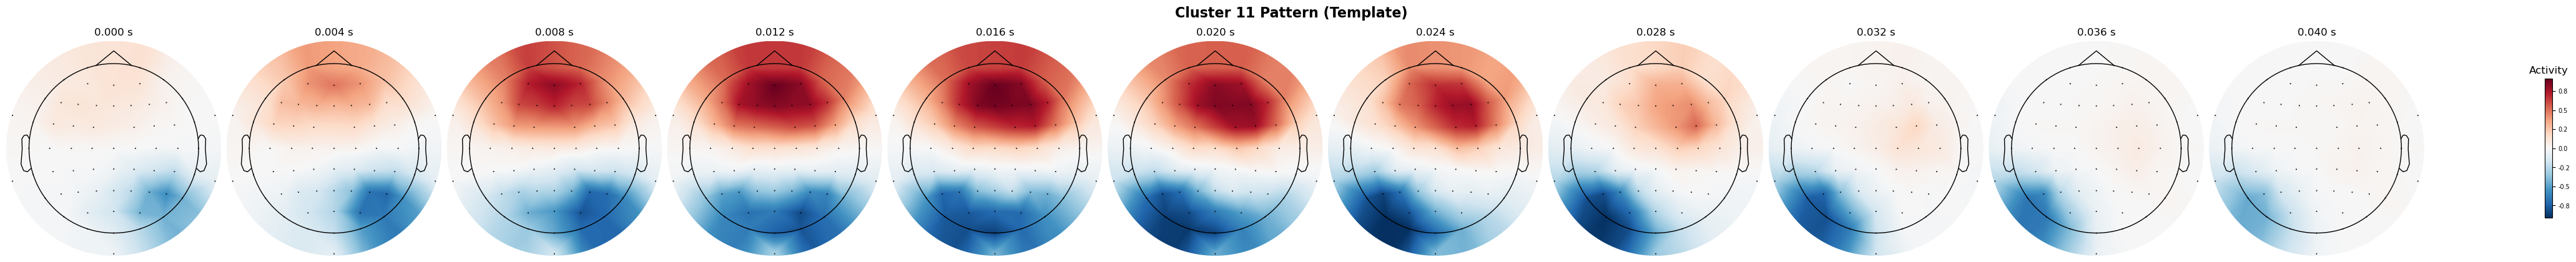


VISUALIZING ACTUAL DATA FROM RAPID BURST (3 activations)


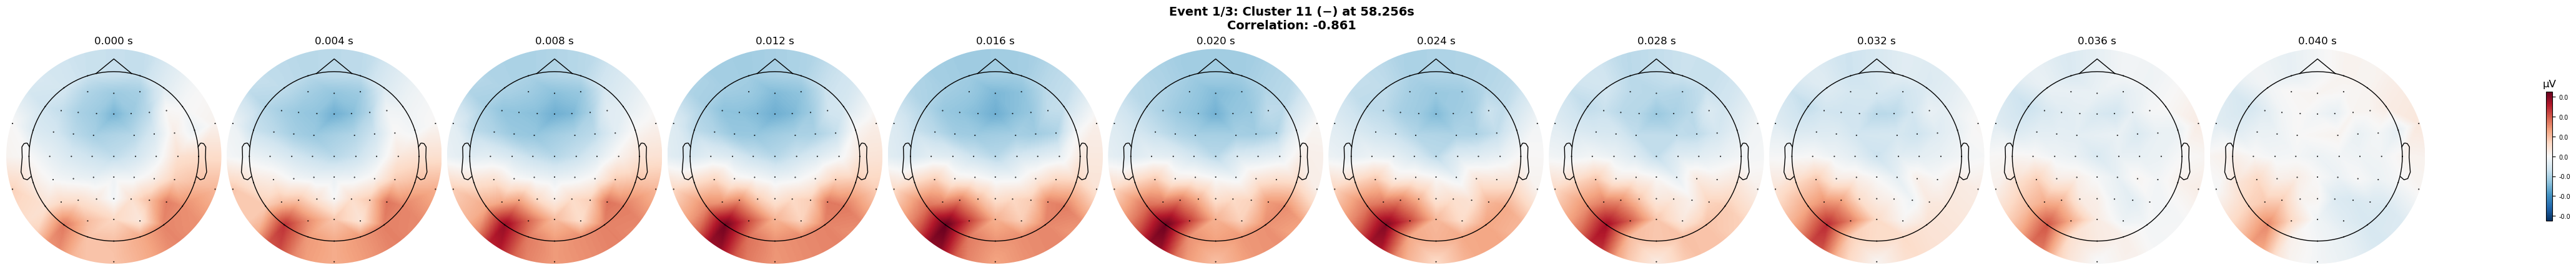

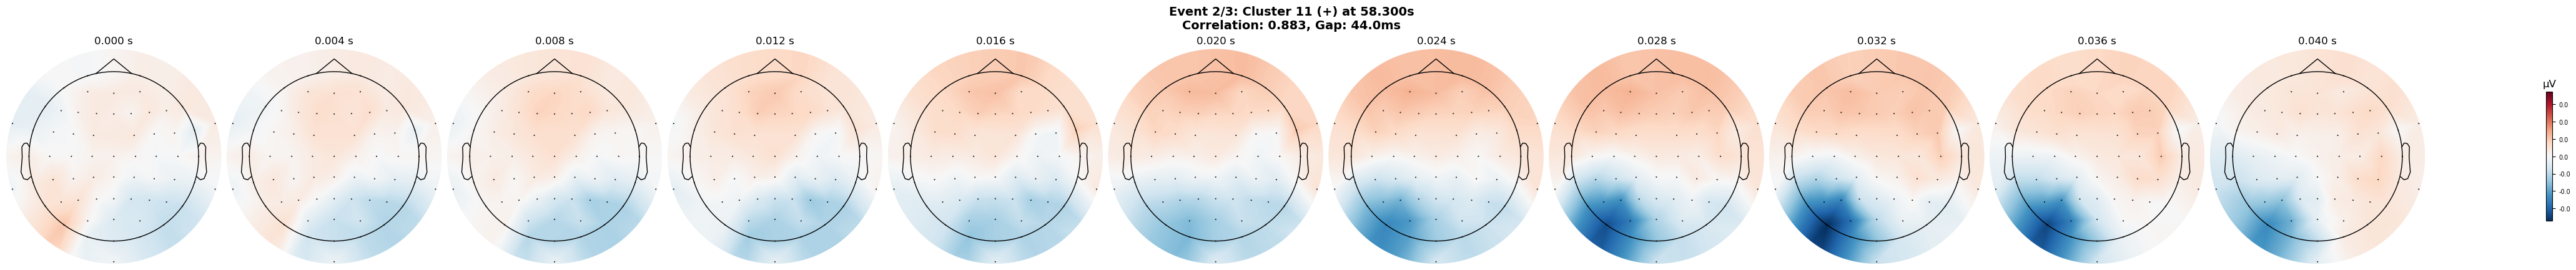

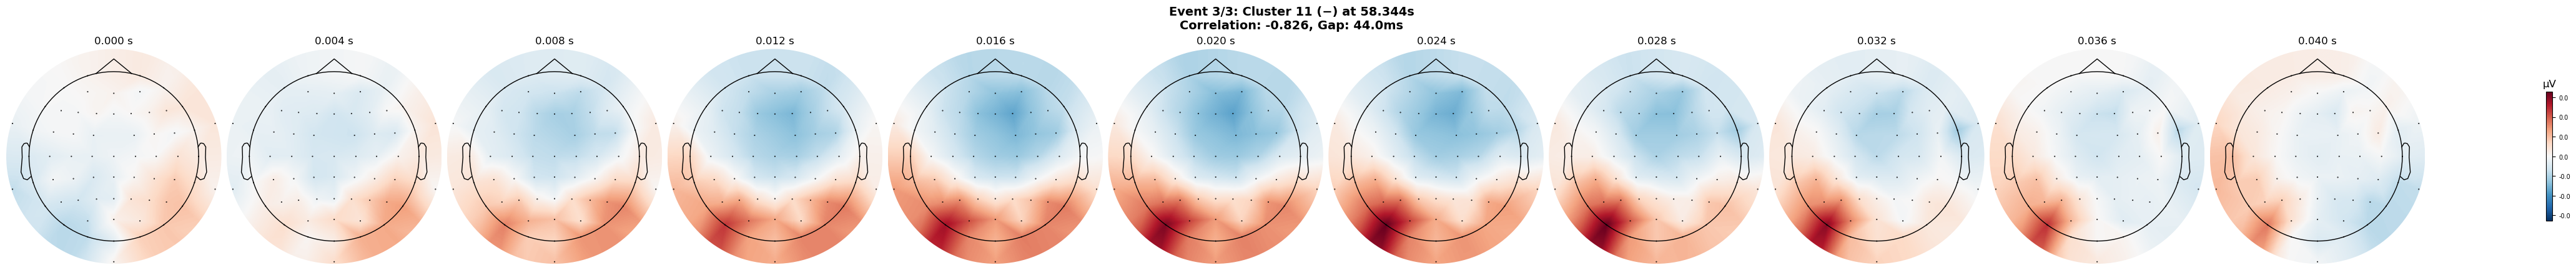


Visualization complete!
Showed first 3 of 3 activations


In [54]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
import json
import mne
from mne.channels import make_dig_montage

# SET WHICH CLUSTER TO VISUALIZE
cluster_to_visualize = 11  # Change this to visualize different clusters
max_interval_ms = 50  # Only show bursts where intervals are < 50ms
burst_rank = 1  # Change to visualize different bursts
min_burst_length = 2  # Minimum number of activations in a burst
min_correlation = 0.825  # Minimum correlation to include activation


print("="*80)
print("VISUALIZING REPETITIVE BURST PATTERNS (HIGH CORRELATIONS ONLY)")
print("="*80)
print(f"\nCluster to visualize: {cluster_to_visualize}")
print(f"Maximum interval: {max_interval_ms}ms")
print(f"Correlation filter: |r| > 0.8\n")

# Load necessary data
print("Loading data...")
with open('/home/novicky/clean_code/similarity_blocks_with_polarity_3/cluster_analysis_k10.0_no_threshold.pkl', 'rb') as f:
    results = pickle.load(f)

with open('/home/novicky/metadata.pkl', 'rb') as f:
    file_metadata = pickle.load(f)

with open('/home/novicky/datasets.pkl', 'rb') as f:
    datasets = pickle.load(f)

with open('/home/novicky/clean_code/similarity_blocks_with_polarity_3/cluster_averages.pkl', 'rb') as f:
    cluster_averages = pickle.load(f)

# Path to electrode positions
electrode_positions_file = '/home/novicky/clean_code/electrode_positions.json'

with open(electrode_positions_file, 'r') as f:
    electrode_data = json.load(f)

channels = list(electrode_data.keys())

# Create montage
ch_pos = {}
for ch in channels:
    pos = electrode_data[ch]
    ch_pos[ch] = [pos['x'], pos['y'], pos['z']]

montage = make_dig_montage(ch_pos=ch_pos, coord_frame='head')

# Get cluster activation times
cluster_activation_times = results['cluster_activation_times']

# Check if cluster exists
if cluster_to_visualize >= len(cluster_activation_times):
    print(f"Error: Cluster {cluster_to_visualize} not found. Only {len(cluster_activation_times)} clusters available.")
    exit(1)

# Calculate interval pattern statistics on the fly
print(f"\n{'='*80}")
print(f"CLUSTER {cluster_to_visualize} ACTIVATION STATISTICS")
print(f"{'='*80}\n")

# Get all high-correlation activations for this cluster
all_times = []
all_polarities = []
all_correlations = []
all_datasets = []

for dataset_idx, times, polarities, correlations in cluster_activation_times[cluster_to_visualize]:
    high_corr_mask = np.abs(correlations) > min_correlation
    all_times.extend(times[high_corr_mask])
    all_polarities.extend(polarities[high_corr_mask])
    all_correlations.extend(correlations[high_corr_mask])
    all_datasets.extend([dataset_idx] * np.sum(high_corr_mask))

all_times = np.array(all_times)
all_polarities = np.array(all_polarities)
all_correlations = np.array(all_correlations)

print(f"Total high-correlation activations (|r|>0.8): {len(all_times)}")
print(f"  Positive polarity: {np.sum(all_polarities > 0)} ({np.sum(all_polarities > 0)/len(all_polarities)*100:.1f}%)")
print(f"  Negative polarity: {np.sum(all_polarities < 0)} ({np.sum(all_polarities < 0)/len(all_polarities)*100:.1f}%)")
print(f"Mean |correlation|: {np.mean(np.abs(all_correlations)):.3f}")
print(f"Datasets with activations: {len(set(all_datasets))}")

# Find bursts of rapid activations for this cluster
print(f"\n{'='*80}")
print(f"FINDING RAPID BURSTS (intervals < {max_interval_ms}ms)")
print(f"{'='*80}\n")

all_bursts = []

for dataset_idx, times, polarities, correlations in cluster_activation_times[cluster_to_visualize]:
    if len(times) < min_burst_length:
        continue
    
    # FILTER: Only keep high correlations (|r| > 0.75)
    high_corr_mask = np.abs(correlations) > min_correlation
    times_filtered = times[high_corr_mask]
    polarities_filtered = polarities[high_corr_mask]
    correlations_filtered = correlations[high_corr_mask]
    
    if len(times_filtered) < min_burst_length:
        continue
    
    # Find bursts of rapid consecutive activations
    current_burst = {
        'times': [times_filtered[0]],
        'polarities': [polarities_filtered[0]],
        'correlations': [correlations_filtered[0]],
        'dataset': dataset_idx
    }
    
    for i in range(1, len(times_filtered)):
        interval_ms = (times_filtered[i] - current_burst['times'][-1]) * 1000
        
        if interval_ms < max_interval_ms:
            # Part of the burst
            current_burst['times'].append(times_filtered[i])
            current_burst['polarities'].append(polarities_filtered[i])
            current_burst['correlations'].append(correlations_filtered[i])
        else:
            # End of burst, save if it has at least 3 activations
            if len(current_burst['times']) >= min_burst_length:
                intervals = np.diff(current_burst['times']) * 1000
                all_bursts.append({
                    'dataset': dataset_idx,
                    'times': np.array(current_burst['times']),
                    'polarities': np.array(current_burst['polarities']),
                    'correlations': np.array(current_burst['correlations']),
                    'length': len(current_burst['times']),
                    'duration': (current_burst['times'][-1] - current_burst['times'][0]) * 1000,
                    'mean_interval': np.mean(intervals),
                    'std_interval': np.std(intervals)
                })
            
            # Start new burst
            current_burst = {
                'times': [times_filtered[i]],
                'polarities': [polarities_filtered[i]],
                'correlations': [correlations_filtered[i]],
                'dataset': dataset_idx
            }
    
    # Don't forget last burst
    if len(current_burst['times']) >= min_burst_length:
        intervals = np.diff(current_burst['times']) * 1000
        all_bursts.append({
            'dataset': dataset_idx,
            'times': np.array(current_burst['times']),
            'polarities': np.array(current_burst['polarities']),
            'correlations': np.array(current_burst['correlations']),
            'length': len(current_burst['times']),
            'duration': (current_burst['times'][-1] - current_burst['times'][0]) * 1000,
            'mean_interval': np.mean(intervals),
            'std_interval': np.std(intervals)
        })

# Sort by duration (longest time span first)
all_bursts.sort(key=lambda x: x['duration'], reverse=True)

print(f"Found {len(all_bursts)} rapid bursts with ≥3 activations\n")

if len(all_bursts) == 0:
    print(f"No rapid bursts found for Cluster {cluster_to_visualize}")
    print(f"Try increasing max_interval_ms or checking a different cluster")
    exit(0)

# Show all bursts
print("All Rapid Bursts (by duration):")
print("-" * 80)
for i, burst in enumerate(all_bursts, 1):
    metadata = file_metadata[burst['dataset']]
    filename = metadata.get('file_path', 'Unknown').split('/')[-1]
    polarity_str = ''.join(['+' if p > 0 else '−' for p in burst['polarities']])
    
    print(f"{i}. Duration={burst['duration']:.1f}ms, Length={burst['length']} activations")
    print(f"   Mean interval: {burst['mean_interval']:.1f}±{burst['std_interval']:.1f}ms")
    print(f"   Pattern: {polarity_str}")
    print(f"   Dataset {burst['dataset']}: {filename}")
    print(f"   Drug: {metadata.get('drug_condition', 'Unknown')} | Task: {metadata.get('task', 'Unknown')}")
    print(f"   Times: {burst['times'][0]:.3f}s → {burst['times'][-1]:.3f}s")
    print()

# Select which burst to visualize
if burst_rank > len(all_bursts):
    print(f"Error: burst_rank {burst_rank} is too high. Only {len(all_bursts)} bursts available.")
    print(f"Setting burst_rank to 1 (first burst)")
    burst_rank = 1

print(f"{'='*80}")
print(f"VISUALIZING BURST RANK {burst_rank}")
print(f"{'='*80}\n")

burst_info = all_bursts[burst_rank - 1]
burst_times = burst_info['times']
burst_polarities = burst_info['polarities']
burst_correlations = burst_info['correlations']
dataset_idx = burst_info['dataset']

metadata = file_metadata[dataset_idx]
filename = metadata.get('file_path', 'Unknown').split('/')[-1]
polarity_str = ''.join(['+' if p > 0 else '−' for p in burst_polarities])

print(f"Cluster: {cluster_to_visualize}")
print(f"Burst length: {burst_info['length']} activations")
print(f"Duration: {burst_info['duration']:.1f}ms")
print(f"Mean interval: {burst_info['mean_interval']:.1f}±{burst_info['std_interval']:.1f}ms")
print(f"Polarity pattern: {polarity_str}")
print(f"Dataset {dataset_idx}: {filename}")
print(f"Subject: {metadata.get('subject_id', 'Unknown')}_{metadata.get('subject_number', 'Unknown')}")
print(f"Drug: {metadata.get('drug_condition', 'Unknown')}")
print(f"Task: {metadata.get('task', 'Unknown')}")

# Visualize cluster pattern
print("\n" + "="*80)
print("VISUALIZING CLUSTER PATTERN")
print("="*80)

cluster_pattern = cluster_averages[cluster_to_visualize]
n_electrodes, n_timepoints = cluster_pattern.shape

# Get vlim
data_max = np.max(np.abs(cluster_pattern))
vlim_cluster = (-data_max, data_max) if data_max > 0 else (-1, 1)

# Plot cluster pattern
info = mne.create_info(ch_names=channels[:n_electrodes], sfreq=250, ch_types='eeg')
evoked = mne.EvokedArray(cluster_pattern, info)
evoked.set_montage(montage)
times = np.arange(n_timepoints) / 250.0

fig1 = evoked.plot_topomap(
    times=times,
    show=False,
    ncols=min(12, n_timepoints),
    nrows='auto',
    size=2.5,
    vlim=vlim_cluster,
    units='Activity',
    image_interp='linear',
    scalings=1,
    cmap='RdBu_r',
    res=256,
    extrapolate='head',
    outlines='head',
    contours=0,
    sensors=True,
    sphere='auto'
)
fig1.suptitle(f'Cluster {cluster_to_visualize} Pattern (Template)', fontsize=16, fontweight='bold')
plt.show()

# Visualize actual data windows from the burst
print("\n" + "="*80)
print(f"VISUALIZING ACTUAL DATA FROM RAPID BURST ({burst_info['length']} activations)")
print("="*80)

dataset = datasets[dataset_idx]
sfreq = 250

# Visualize all events in the burst (or first 20 if too many)
num_events_to_show = min(20, len(burst_times))

for i in range(num_events_to_show):
    event_time = burst_times[i]
    polarity = burst_polarities[i]
    correlation = burst_correlations[i]
    
    polarity_symbol = '+' if polarity > 0 else '−'
    
    # Convert time to sample index
    sample_idx = int(event_time * sfreq)
    
    # Extract window
    start_idx = sample_idx
    end_idx = sample_idx + n_timepoints
    
    if end_idx <= dataset.shape[1]:
        data_window = dataset[:n_electrodes, start_idx:end_idx]
        
        # Create evoked object
        info_window = mne.create_info(ch_names=channels[:n_electrodes], sfreq=250, ch_types='eeg')
        evoked_window = mne.EvokedArray(data_window, info_window)
        evoked_window.set_montage(montage)
        
        # Get vlim
        data_max_window = np.max(np.abs(data_window))
        vlim_window = (-data_max_window, data_max_window) if data_max_window > 0 else (-1, 1)
        
        times_window = np.arange(n_timepoints) / 250.0
        
        # Plot
        fig = evoked_window.plot_topomap(
            times=times_window,
            show=False,
            ncols=min(12, n_timepoints),
            nrows='auto',
            size=2.5,
            vlim=vlim_window,
            units='µV',
            image_interp='linear',
            scalings=1,
            cmap='RdBu_r',
            res=256,
            extrapolate='head',
            outlines='head',
            contours=0,
            sensors=True,
            sphere='auto'
        )
        
        if i > 0:
            prev_time = burst_times[i-1]
            gap = (event_time - prev_time) * 1000
            fig.suptitle(f'Event {i+1}/{burst_info["length"]}: Cluster {cluster_to_visualize} ({polarity_symbol}) at {event_time:.3f}s\n'
                       f'Correlation: {correlation:.3f}, Gap: {gap:.1f}ms', 
                       fontsize=14, fontweight='bold')
        else:
            fig.suptitle(f'Event {i+1}/{burst_info["length"]}: Cluster {cluster_to_visualize} ({polarity_symbol}) at {event_time:.3f}s\n'
                       f'Correlation: {correlation:.3f}', 
                       fontsize=14, fontweight='bold')
        plt.show()

print("\nVisualization complete!")
print(f"Showed first {num_events_to_show} of {burst_info['length']} activations")

# Save burst information
output_data = {
    'cluster_id': cluster_to_visualize,
    'all_bursts': all_bursts,
    'visualized_burst': burst_info,
    'activation_stats': {
        'total_high_corr_activations': len(all_times),
        'n_positive': np.sum(all_polarities > 0),
        'n_negative': np.sum(all_polarities < 0),
        'mean_abs_correlation': np.mean(np.abs(all_correlations)),
        'n_datasets': len(set(all_datasets))
    }
}

# with open(f'cluster_{cluster_to_visualize}_bursts.pkl', 'wb') as f:
#     pickle.dump(output_data, f)

# print(f"\nSaved burst data to 'cluster_{cluster_to_visualize}_bursts.pkl'")

In [43]:
import numpy as np
import matplotlib.pyplot as plt
import json
import mne
from mne.channels import make_dig_montage
import cv2
import os
import tempfile


def create_continuous_burst_video(burst_info, dataset, cluster_pattern, cluster_id, 
                                   electrode_positions_file, output_file=None, 
                                   fps=10, dpi=150, figsize=(12, 8)):
    """
    Create a video showing continuous EEG data from the start of the first 
    activation to the end of the last activation in a burst.
    
    Parameters:
    -----------
    burst_info : dict
        Burst information with keys: 'times', 'polarities', 'correlations', 
        'length', 'duration', 'mean_interval', 'std_interval', 'dataset'
    dataset : array
        EEG dataset array (channels × timepoints)
    cluster_pattern : array
        Cluster pattern array (channels × timepoints)
    cluster_id : int
        Cluster ID number
    electrode_positions_file : str
        Path to JSON file with electrode positions
    output_file : str, optional
        Output video filename (default: 'cluster_X_burst_continuous.mp4')
    fps : int
        Frames per second (default: 10)
    dpi : int
        Resolution of saved frames (default: 150)
    figsize : tuple
        Figure size in inches (default: (12, 8))
        
    Returns:
    --------
    str : Path to created video file
    """
    
    if output_file is None:
        output_file = f'cluster_{cluster_id}_burst_continuous.mp4'
    
    burst_times = burst_info['times']
    burst_polarities = burst_info['polarities']
    burst_correlations = burst_info['correlations']
    
    n_electrodes, n_timepoints_pattern = cluster_pattern.shape
    sfreq = 250
    
    # Calculate the continuous segment boundaries
    first_activation_time = burst_times[0]
    last_activation_time = burst_times[-1]
    
    # Start at the beginning of the first activation
    start_sample = int(first_activation_time * sfreq)
    # End at the end of the last activation (add pattern length)
    end_sample = int(last_activation_time * sfreq) + n_timepoints_pattern
    
    # Extract the entire continuous segment
    if end_sample > dataset.shape[1]:
        end_sample = dataset.shape[1]
    
    continuous_data = dataset[:n_electrodes, start_sample:end_sample]
    n_continuous_timepoints = continuous_data.shape[1]
    
    duration_ms = (n_continuous_timepoints / sfreq) * 1000
    
    print(f"Creating continuous video for Cluster {cluster_id} burst")
    print(f"  Burst length: {burst_info['length']} activations")
    print(f"  Total duration: {duration_ms:.1f}ms ({n_continuous_timepoints} timepoints)")
    print(f"  Start time: {first_activation_time:.3f}s")
    print(f"  End time: {(end_sample/sfreq):.3f}s")
    print(f"  Video will have {n_continuous_timepoints} frames at {fps} fps = {n_continuous_timepoints/fps:.1f}s")
    
    # Load electrode positions
    with open(electrode_positions_file, 'r') as f:
        electrode_data = json.load(f)
    
    channels = list(electrode_data.keys())
    
    # Create montage
    ch_pos = {}
    for ch in channels:
        pos = electrode_data[ch]
        ch_pos[ch] = [pos['x'], pos['y'], pos['z']]
    
    montage = make_dig_montage(ch_pos=ch_pos, coord_frame='head')
    
    # Setup MNE info
    info = mne.create_info(ch_names=channels[:n_electrodes], sfreq=250, ch_types='eeg')
    
    # Calculate consistent vlim across entire segment
    data_max = np.max(np.abs(continuous_data))
    vlim = (-data_max, data_max) if data_max > 0 else (-1, 1)
    
    # Create temporary directory for frames
    temp_dir = tempfile.mkdtemp()
    frame_files = []
    
    print(f"  Generating frames...")
    
    try:
        # Create a frame for each timepoint in the continuous segment
        for t_idx in range(n_continuous_timepoints):
            # Current time relative to start of burst
            current_time_ms = (t_idx / sfreq) * 1000
            # Absolute time in recording
            absolute_time_s = (start_sample + t_idx) / sfreq
            
            # Check if this timepoint is within any activation window
            is_activation = False
            activation_info = ""
            
            for act_idx, act_time in enumerate(burst_times):
                act_start_sample = int(act_time * sfreq)
                act_end_sample = act_start_sample + n_timepoints_pattern
                current_sample = start_sample + t_idx
                
                if act_start_sample <= current_sample < act_end_sample:
                    is_activation = True
                    polarity = burst_polarities[act_idx]
                    correlation = burst_correlations[act_idx]
                    polarity_symbol = '+' if polarity > 0 else '−'
                    activation_info = f" | ACTIVATION {act_idx+1}: {polarity_symbol} (r={correlation:.3f})"
                    break
            
            # Create evoked object
            evoked = mne.EvokedArray(continuous_data[:, [t_idx]], info, tmin=0)
            evoked.set_montage(montage)
            
            # Create figure
            fig, ax = plt.subplots(figsize=figsize, dpi=dpi)
            
            # Plot topomap
            im, cn = mne.viz.plot_topomap(
                evoked.data[:, 0],
                evoked.info,
                axes=ax,
                show=False,
                vlim=vlim,
                cmap='RdBu_r',
                res=256,
                extrapolate='head',
                outlines='head',
                contours=0,
                sensors=True,
                sphere='auto'
            )
            
            # Add colorbar
            cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
            cbar.set_label('µV', rotation=270, labelpad=20)
            
            # Add title with activation highlighting
            title = (f'Cluster {cluster_id} - Continuous Burst Segment\n'
                    f'Time: {current_time_ms:.1f}ms (frame {t_idx+1}/{n_continuous_timepoints}){activation_info}')
            
            # Change title color if within activation
            title_color = 'red' if is_activation else 'black'
            ax.set_title(title, fontsize=12, fontweight='bold', pad=20, color=title_color)
            
            # Save frame
            frame_file = os.path.join(temp_dir, f'frame_{t_idx:04d}.png')
            plt.savefig(frame_file, bbox_inches='tight', dpi=dpi)
            frame_files.append(frame_file)
            plt.close(fig)
            
            if (t_idx + 1) % 50 == 0 or t_idx == n_continuous_timepoints - 1:
                print(f"  Generated frame {t_idx+1}/{n_continuous_timepoints}")
        
        print(f"  All frames generated. Creating video...")
        
        # Read first frame to get dimensions
        first_frame = cv2.imread(frame_files[0])
        height, width, layers = first_frame.shape
        
        # Create video writer
        fourcc = cv2.VideoWriter_fourcc(*'mp4v')
        video = cv2.VideoWriter(output_file, fourcc, fps, (width, height))
        
        # Write all frames to video
        for frame_file in frame_files:
            frame = cv2.imread(frame_file)
            video.write(frame)
        
        video.release()
        
        print(f"\n✓ Video saved: {output_file}")
        print(f"  Frames: {n_continuous_timepoints}")
        print(f"  Duration: {n_continuous_timepoints/fps:.2f}s")
        print(f"  Resolution: {width}x{height}")
        print(f"  Shows continuous data from {first_activation_time:.3f}s to {(end_sample/sfreq):.3f}s")
        
        return output_file
        
    finally:
        # Cleanup temporary files
        for frame_file in frame_files:
            if os.path.exists(frame_file):
                os.remove(frame_file)
        if os.path.exists(temp_dir):
            os.rmdir(temp_dir)




In [ ]:
# Example usage in your notebook:
# 
video_file = create_continuous_burst_video(
    burst_info=burst_info,              # The selected burst dict
    dataset=datasets[dataset_idx],       # EEG data array
    cluster_pattern=cluster_averages[cluster_id],  # Cluster pattern
    cluster_id=11,                       # Cluster number
    electrode_positions_file='/home/novicky/clean_code/electrode_positions.json',
    output_file='my_continuous_burst_.mp4',
    fps=5,                              # 10 fps = 4ms per frame at 250Hz
    dpi=150
)

Creating continuous video for Cluster 11 burst
  Burst length: 3 activations
  Total duration: 132.0ms (33 timepoints)
  Start time: 58.256s
  End time: 58.388s
  Video will have 33 frames at 5 fps = 6.6s
  Generating frames...
  Generated frame 33/33
  All frames generated. Creating video...

✓ Video saved: my_continuous_burst_{cluster_id}.mp4
  Frames: 33
  Duration: 6.60s
  Resolution: 1142x1042
  Shows continuous data from 58.256s to 58.388s
